# Contexto global + rede magnética regional: SuperMAG e EMBRACE em 10 de junho de 2025

## Pergunta

O que uma rede regional densa revela sobre uma perturbação que um mapa global esparso pode não resolver — e o que o contexto global acrescenta à interpretação local?

Este estudo compara o arquivo diário global SuperMAG de 1 minuto com os registros anuais `final.xdr` da rede EMBRACE de 2025, já copiados para `LFS/EMBRACE_2025`. Usa-se **10 de junho de 2025** porque existe um produto global SuperMAG correspondente no diretório do projeto. Os arquivos e estações são mantidos identificados por fonte; os dois produtos não são tratados como se tivessem a mesma linha de base ou processamento.

**A motivação:** se os magnetômetros brasileiros forem analisados apenas como rede local, perde-se a estrutura espacial e temporal de grande escala que ajuda a distinguir uma resposta regional de uma perturbação global. Em contrapartida, o produto global desse exemplo não contém a maior parte das estações EMBRACE listadas: a cobertura local continua essencial.

## Dados e convenções

- **EMBRACE:** `2025_<CODIGO>_final.xdr`; série com 525.600 amostras por componente no ano não bissexto de 2025 (cadência de 1 minuto). O conteúdo IDL/XDR traz `n`, `e`, `z`, `station`, `provider` e `year`. O valor 999999 é tratado como sentinela inválida. A unidade é interpretada como nT a partir das convenções do produto; o arquivo não expõe uma variável de unidade.
- **SuperMAG:** `20250610.vec-supermag.60s.rev-0006.ncdf.gz`; vetores geográficos `dbn_geo`, `dbe_geo`, `dbz_geo` em nT, posição geográfica e código de estação a cada minuto. As longitudes da fonte em 0–360° são normalizadas para −180–180° antes do mapeamento.
- Para comparar variações temporais, cada componente local é centralizado pela mediana diária da própria estação. Isso **não** equivale à linha de base SuperMAG nem a uma calibração comum. Após normalizar as longitudes, o produto selecionado contém vetores de sete estações na caixa da América do Sul e compartilha o código VSS com EMBRACE. A série pareada de VSS é uma verificação de consistência entre produtos, não duas medições independentes.
- As coordenadas da rede regional abaixo vêm da tabela fornecida pelo usuário. Um ponto no mapa não implica que o arquivo de 2025 esteja disponível para aquela estação.

In [1]:
from pathlib import Path
import os, gzip
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.io import readsav
from netCDF4 import Dataset

SEED=20250610
KEYNOTE=Path(os.environ.get("SBGEA_KEYNOTE_DATA",Path.home()/"Documents/Science/Programs/LFS/KEYNOTE")).expanduser()
EMBRACE_DIR=KEYNOTE/"inputs"/"supermag"/"brazil_network"/"EMBRACE_2025"
GLOBAL_FILE=KEYNOTE/"inputs"/"supermag"/"global"/"2025"/"20250610.vec-supermag.60s.rev-0006.ncdf.gz"
OUT_DATA=KEYNOTE/"outputs"/"data"/"supermag"
OUT_FIG=KEYNOTE/"outputs"/"figures"/"supermag"
OUT_DATA.mkdir(parents=True,exist_ok=True); OUT_FIG.mkdir(parents=True,exist_ok=True)
EVENT_DATE=pd.Timestamp("2025-06-10",tz="UTC")
MAP_TIME=pd.Timestamp("2025-06-10T18:00:00Z")

# Catalog supplied for this analysis; longitude, latitude in geographic degrees.
STATION_CATALOG=pd.DataFrame([
 ("ALF","Alta Floresta",-56.10403,-9.87033),("ARA","Araguatins",-48.07352,-5.65130),
 ("CAR","São João do Cariri",-36.52972,-7.37916),("CBA","Cuiabá",-56.06945,-15.55472),
 ("CHI","Chillán",-71.99485,-36.64122),("CXP","Cachoeira Paulista",-45.01443,-22.70207),
 ("EUS","Eusébio",-38.42467,-3.87998),("JAT","Jataí",-51.71840,-17.93185),
 ("MED","Medianeira",-54.11451,-25.29967),("MAN","Manaus",-59.97465,-3.10803),
 ("PAL","Palmas",-48.35889,-10.17889),("PVE","Porto Velho",-63.94000,-8.83500),
 ("RGA","Rio Grande",-67.75145,-53.78572),("SJC","São José dos Campos",-45.96353,-23.20862),
 ("SLZ","São Luís",-44.20972,-2.59417),("STM","Santarém",-54.53920,-2.68630),
 ("SMS","São Martinho da Serra",-53.82273,-29.44357),("TCM","Tucumán",-65.31555,-26.79612),
 ("VSS","Vassouras",-43.65223,-22.40197)],
 columns=["station","name","longitude","latitude"])

assert EMBRACE_DIR.exists(), f"EMBRACE input directory not found: {EMBRACE_DIR}"
assert GLOBAL_FILE.exists(), f"SuperMAG input file not found: {GLOBAL_FILE}"
print("EMBRACE input:",EMBRACE_DIR,"| global input:",GLOBAL_FILE.name)
print("Available EMBRACE final files:",len(list(EMBRACE_DIR.glob("2025_*_final.xdr"))))


EMBRACE input: $SBGEA_KEYNOTE_DATA/inputs/supermag/brazil_network/EMBRACE_2025 | global input: 20250610.vec-supermag.60s.rev-0006.ncdf.gz
Available EMBRACE final files: 9


## Leitura e validação dos produtos

As funções abaixo leem diretamente os arquivos XDR e NetCDF compactado. A série regional é atribuída a minutos UTC a partir de 1º de janeiro, verificando o comprimento anual. No SuperMAG, os vetores mantêm seus próprios horários e códigos; não interpolamos as coordenadas como se fossem estações fixas ao longo de todo o arquivo.

In [3]:
def decode_bytes(value):
    if isinstance(value,(bytes,np.bytes_)):
        return bytes(value).decode("utf-8","ignore").strip("\x00 ")
    return str(value).strip()

def load_embrace_year(folder):
    files=sorted(folder.glob("2025_*_final.xdr"))
    frames=[]; metadata=[]
    year_start=pd.Timestamp("2025-01-01T00:00:00Z")
    expected=365*24*60
    for path in files:
        saved=readsav(str(path),python_dict=True)
        station=decode_bytes(saved["station"]).upper()
        year=int(np.asarray(saved["year"]).item())
        if year!=2025: raise ValueError(f"Unexpected year {year} in {path.name}")
        arrays={key:np.asarray(saved[key],dtype=float).reshape(-1) for key in ("n","e","z")}
        lengths={len(a) for a in arrays.values()}
        if len(lengths)!=1: raise ValueError(f"Component length mismatch: {path.name}")
        n=len(arrays["n"])
        if n!=expected: raise ValueError(f"{path.name}: expected {expected} minute samples, found {n}")
        time=pd.date_range(year_start,periods=n,freq="min")
        frame=pd.DataFrame({"time_utc":time,"station":station,**{f"{k}_nT":v for k,v in arrays.items()}})
        for k in ("n","e","z"):
            bad=(~np.isfinite(frame[f"{k}_nT"]))|(np.abs(frame[f"{k}_nT"])>=100000)
            frame.loc[bad,f"{k}_nT"]=np.nan
        frame["valid_vector"] = frame[["n_nT","e_nT","z_nT"]].notna().all(axis=1)
        frames.append(frame)
        metadata.append({"station":station,"file":path.name,"provider":decode_bytes(saved.get("provider",b"")),"samples":n})
    if not frames: raise FileNotFoundError(f"No 2025_*_final.xdr files in {folder}")
    return pd.concat(frames,ignore_index=True),pd.DataFrame(metadata)

def decode_station_id(row):
    chars=np.ma.filled(row,fill_value=b" ")
    raw=b"".join(bytes(v) for v in np.asarray(chars).ravel())
    return raw.decode("ascii","ignore").strip("\x00 ")

def load_supermag_day(path):
    with gzip.open(path,"rb") as stream: payload=stream.read()
    with Dataset("supermag_global.ncdf",mode="r",memory=payload) as ds:
        required=("time_yr","time_mo","time_dy","time_hr","time_mt","time_sc","id","glat","glon","dbn_geo","dbe_geo","dbz_geo")
        missing=[name for name in required if name not in ds.variables]
        if missing: raise KeyError(f"Missing SuperMAG variables: {missing}")
        ts=pd.DatetimeIndex(pd.to_datetime({
            "year":np.asarray(ds["time_yr"][:],dtype=int),"month":np.asarray(ds["time_mo"][:],dtype=int),
            "day":np.asarray(ds["time_dy"][:],dtype=int),"hour":np.asarray(ds["time_hr"][:],dtype=int),
            "minute":np.asarray(ds["time_mt"][:],dtype=int),"second":np.floor(np.asarray(ds["time_sc"][:],dtype=float)).astype(int)},utc=True))
        ids=np.empty(ds["id"].shape[:2],dtype=object)
        raw_ids=ds["id"][:]
        for it in range(ids.shape[0]):
            for js in range(ids.shape[1]): ids[it,js]=decode_station_id(raw_ids[it,js])
        data={name:np.ma.filled(ds[name][:],np.nan).astype(float) for name in ("glat","glon","dbn_geo","dbe_geo","dbz_geo")}
    nt,ns=ids.shape
    flat=pd.DataFrame({"time_utc":np.repeat(ts.to_numpy(),ns),"station":ids.ravel(),
        "latitude":data["glat"].ravel(),"longitude":data["glon"].ravel(),
        "dBn_geo_nT":data["dbn_geo"].ravel(),"dBe_geo_nT":data["dbe_geo"].ravel(),"dBz_geo_nT":data["dbz_geo"].ravel()})
    # SuperMAG glon is commonly encoded on 0..360 degrees; retain it, then
    # normalize to the -180..180 convention used by the geographic maps.
    valid_lon=flat.longitude.between(-180,180)|flat.longitude.between(180,360)
    good=(flat.station!="")&flat.latitude.between(-90,90)&valid_lon
    good &= np.isfinite(flat.dBn_geo_nT)&np.isfinite(flat.dBe_geo_nT)&(flat.dBn_geo_nT.abs()<2000)&(flat.dBe_geo_nT.abs()<2000)
    flat=flat.loc[good].copy()
    flat["longitude"]=((flat.longitude+180)%360)-180
    flat["dBH_nT"]=np.hypot(flat.dBn_geo_nT,flat.dBe_geo_nT)
    return flat.sort_values(["time_utc","station"]).reset_index(drop=True),ts

embrace,embrace_files=load_embrace_year(EMBRACE_DIR)
supermag,supermag_times=load_supermag_day(GLOBAL_FILE)
assert supermag_times.min().date()==EVENT_DATE.date() and supermag_times.max().date()==EVENT_DATE.date()
assert supermag_times.is_monotonic_increasing and supermag_times.duplicated().sum()==0
assert np.all(supermag_times.to_series().diff().dropna().eq(pd.Timedelta(seconds=60)).all()),"Expected a 60-second SuperMAG cadence"
local_day=embrace[embrace.time_utc.dt.date==EVENT_DATE.date()].copy()
local_day["n_centered_nT"]=local_day.n_nT-local_day.groupby("station").n_nT.transform("median")
local_day["e_centered_nT"]=local_day.e_nT-local_day.groupby("station").e_nT.transform("median")
local_day["z_centered_nT"]=local_day.z_nT-local_day.groupby("station").z_nT.transform("median")

# Station availability is computed from valid N/E/Z triples in the event day.
coverage=(local_day.groupby("station").agg(
    valid_minutes=("valid_vector","sum"),n_samples=("time_utc","size"),
    median_abs_dN_nT=("n_centered_nT",lambda x:float(np.nanmedian(np.abs(x))) if x.notna().any() else np.nan),
    p95_abs_dN_nT=("n_centered_nT",lambda x:float(np.nanpercentile(np.abs(x.dropna()),95)) if x.notna().any() else np.nan))
    .reset_index())
coverage["valid_fraction"]=coverage.valid_minutes/coverage.n_samples
coverage=STATION_CATALOG.merge(coverage,on="station",how="left")
coverage["file_present"]=coverage.station.isin(embrace_files.station)
coverage["global_product_present"]=coverage.station.isin(supermag.station.unique())
coverage.to_csv(OUT_DATA/"embrace_station_coverage_20250610.csv",index=False)

supermag_epoch=supermag.iloc[np.argmin(np.abs((supermag.time_utc-MAP_TIME).dt.total_seconds()))].time_utc
sm_epoch=supermag[supermag.time_utc==supermag_epoch].copy()
local_file_codes=set(embrace_files.station)
global_day_codes=set(supermag.station.unique())
common_codes=sorted(local_file_codes & global_day_codes)
print("EMBRACE final files:",sorted(local_file_codes))
print("Valid local stations on event day:",coverage.loc[coverage.valid_minutes>0,"station"].tolist())
print("SuperMAG vectors at",supermag_epoch,"=",len(sm_epoch),"| shared station codes:",common_codes)
print("Regional coverage CSV:",OUT_DATA/"embrace_station_coverage_20250610.csv")


EMBRACE final files: ['CAR', 'CHI', 'CXP', 'EUS', 'SJC', 'SLZ', 'SMS', 'STM', 'VSS']
Valid local stations on event day: ['CAR', 'CHI', 'CXP', 'EUS', 'SJC', 'SLZ', 'STM', 'VSS']
SuperMAG vectors at 2025-06-10 18:00:00+00:00 = 169 | shared station codes: ['VSS']
Regional coverage CSV: $SBGEA_KEYNOTE_DATA/outputs/data/supermag/embrace_station_coverage_20250610.csv


## O que aparece na escala global e na escala regional?

O mapa global mostra o módulo horizontal SuperMAG no instante selecionado. O detalhe regional sobrepõe as posições das estações do catálogo às estações com vetores globais válidos. A série EMBRACE é representada como anomalia em relação à mediana diária de cada estação. A contagem horária evidencia quantas estações têm dados em cada fonte dentro da caixa regional definida.

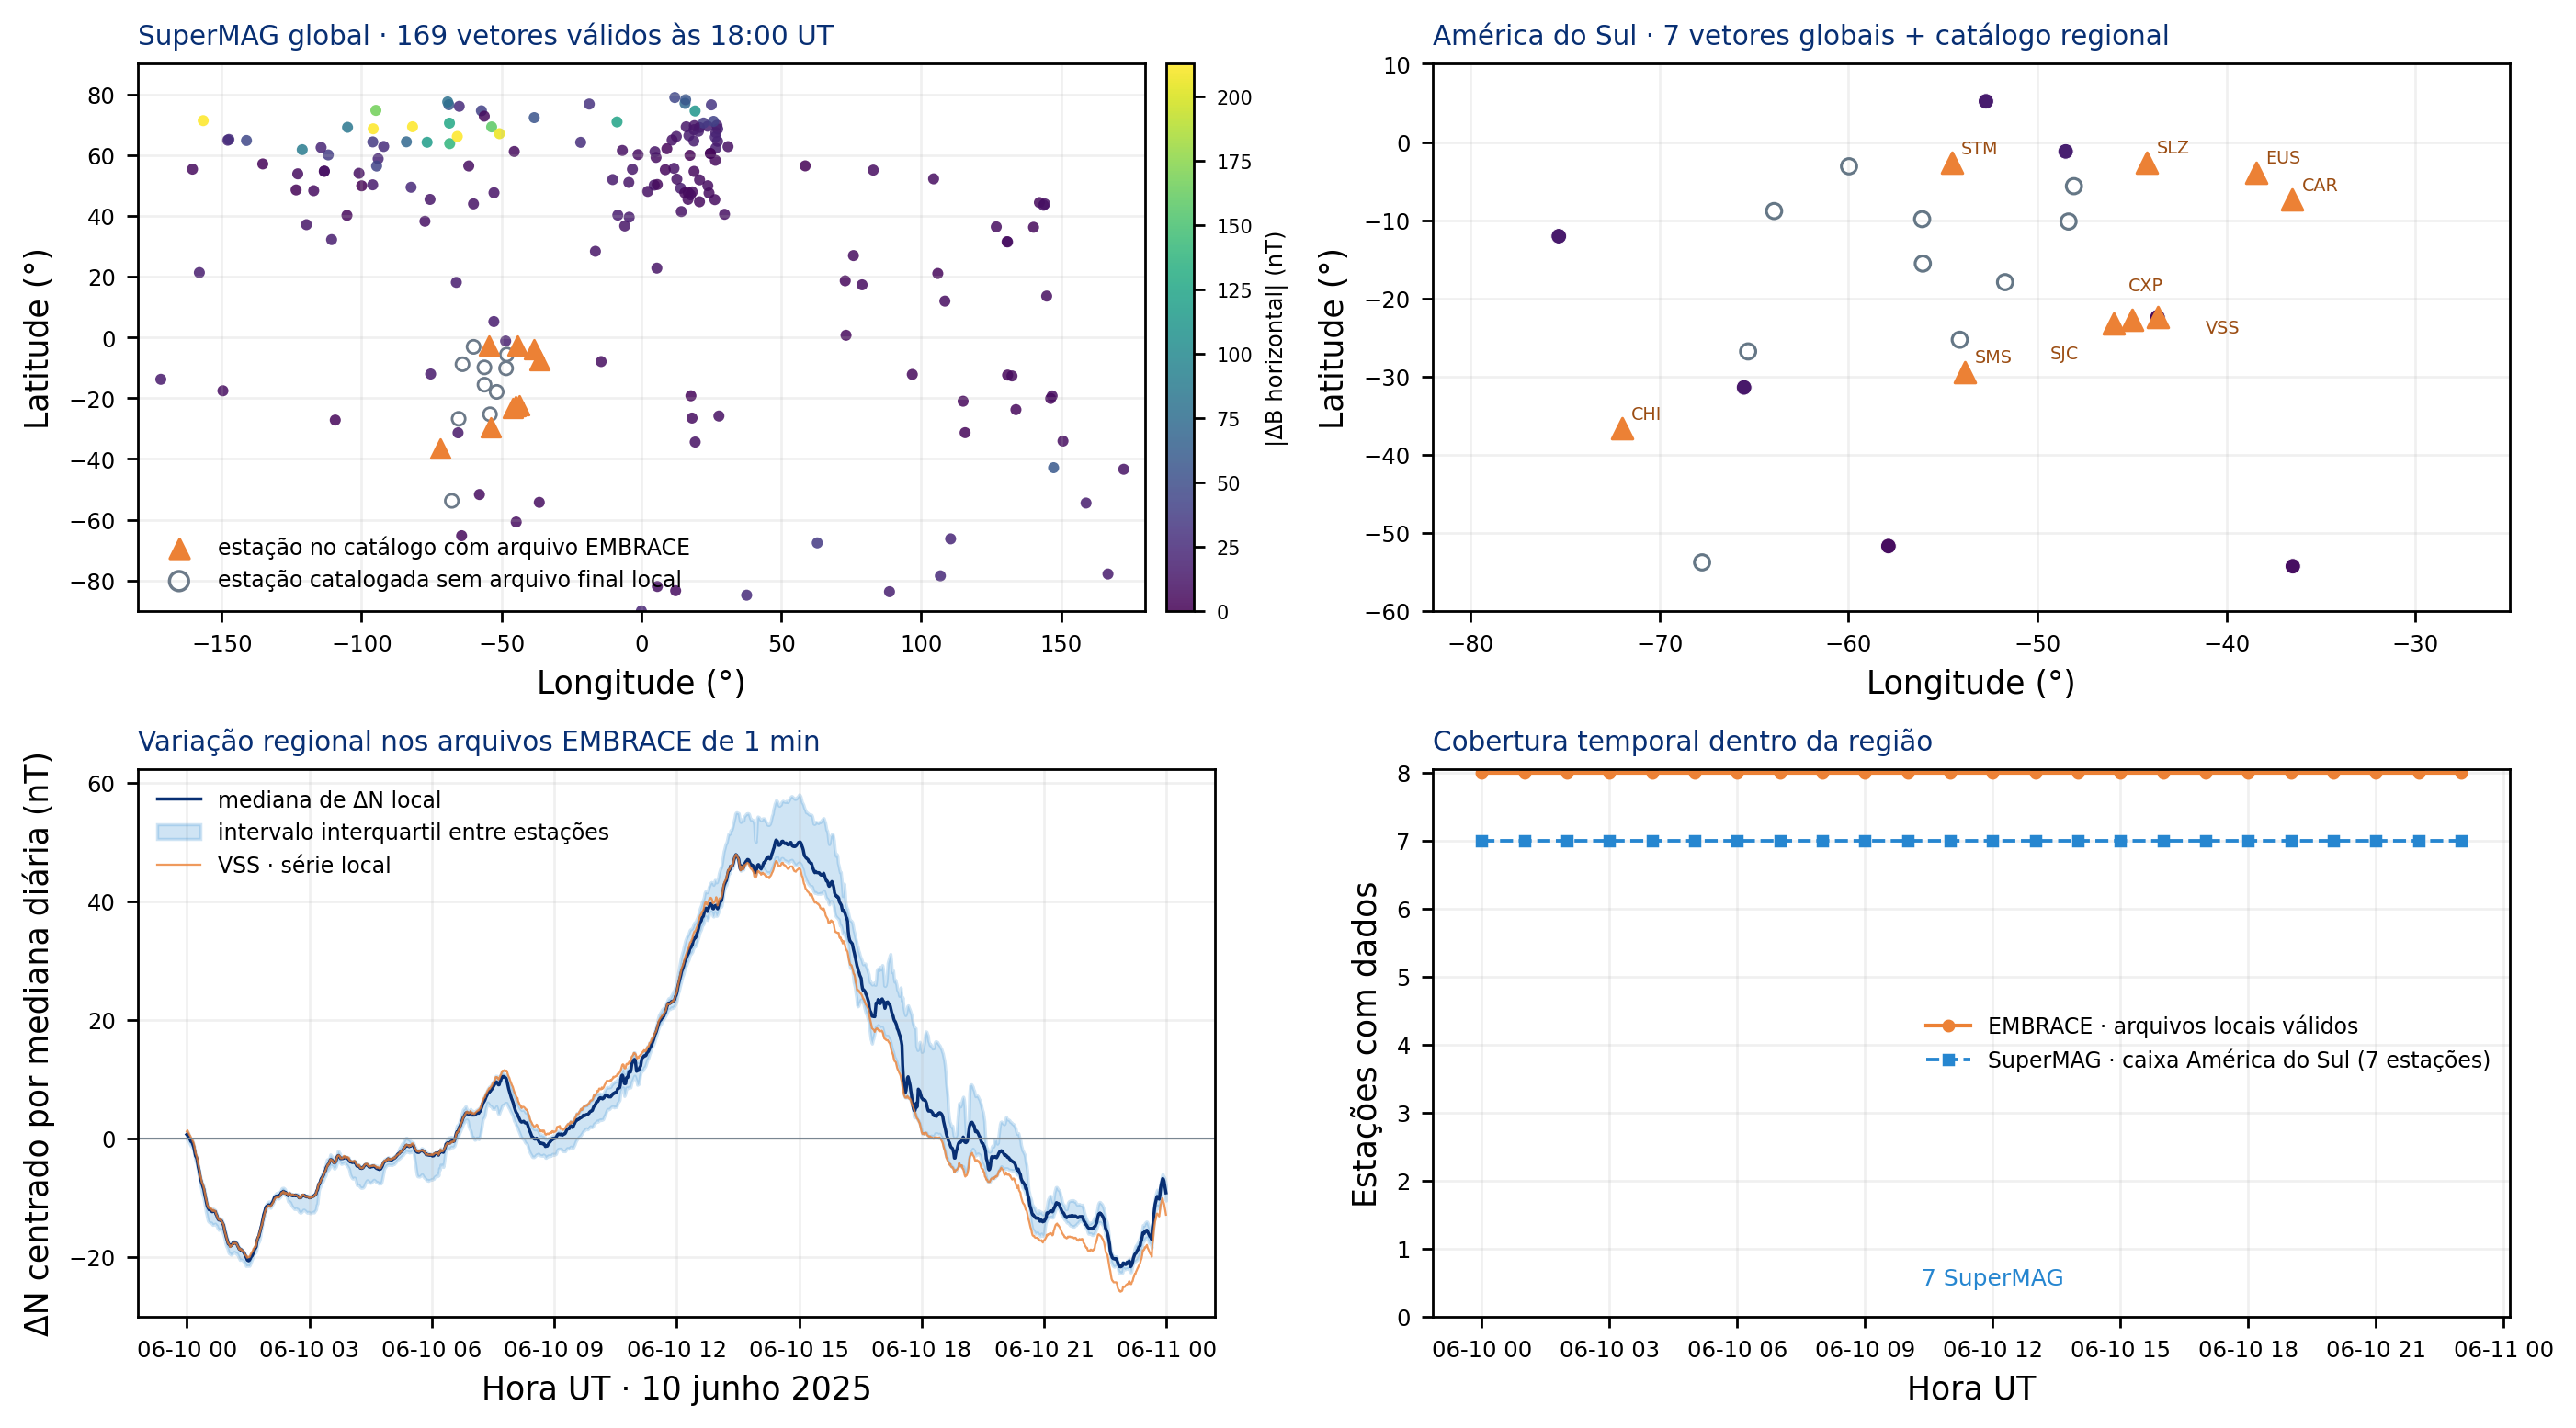

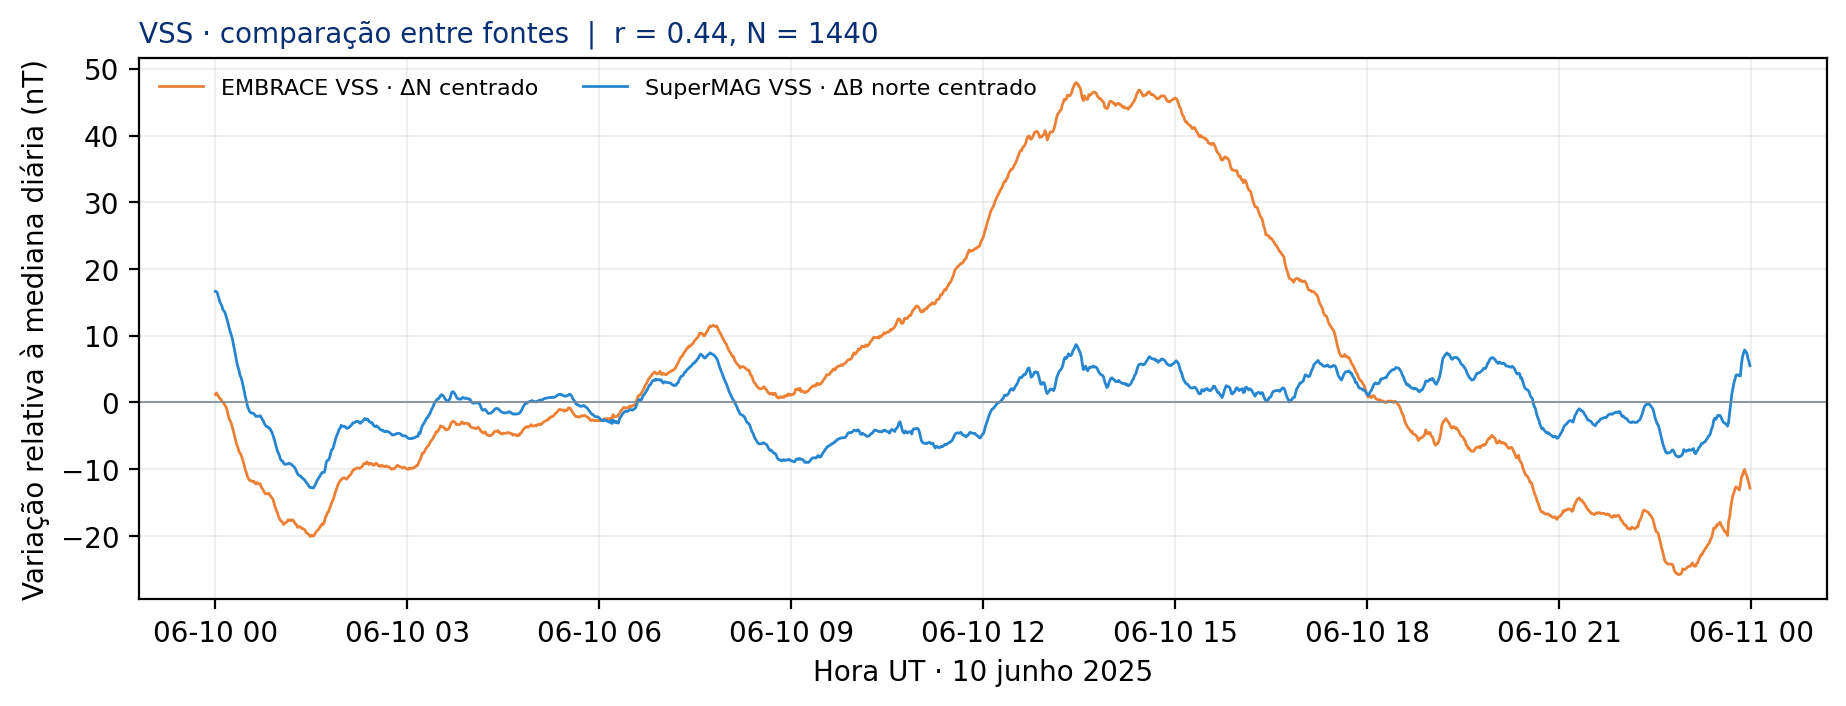

Comparison figure displayed inline; no external copy saved.
Saved station-count table: $SBGEA_KEYNOTE_DATA/outputs/data/supermag/station_count_by_hour_20250610.csv
VSS comparison correlation: 0.4449828466533939 with 1440 paired minute samples


In [3]:
# Hourly count of usable local records and global vectors in the South American box.
local_box=(-82,-25,-60,10)  # lon_min, lon_max, lat_min, lat_max
global_region=supermag[supermag.longitude.between(local_box[0],local_box[1])&supermag.latitude.between(local_box[2],local_box[3])].copy()
local_active=(local_day[local_day.valid_vector].groupby(local_day.time_utc.dt.floor("h")).station.nunique())
global_active=global_region.groupby(global_region.time_utc.dt.floor("h")).station.nunique()
hours=pd.date_range(EVENT_DATE,periods=24,freq="h")
count_hourly=pd.DataFrame({"time_utc":hours,
    "embrace_active_stations":local_active.reindex(hours,fill_value=0).to_numpy(),
    "supermag_south_america_stations":global_active.reindex(hours,fill_value=0).to_numpy()})
count_hourly.to_csv(OUT_DATA/"station_count_by_hour_20250610.csv",index=False)

# Robust regional summary of centered north component at each minute.
local_valid=local_day[local_day.n_centered_nT.notna()]
local_q=local_valid.groupby("time_utc").n_centered_nT.quantile([.25,.5,.75]).unstack()
local_q.columns=["q25","median","q75"]
local_q=local_q.reindex(pd.date_range(EVENT_DATE,periods=1440,freq="min"))

# VSS exists in both products for this event; compare daily-centered north traces.
vss_local=local_day[local_day.station=="VSS"].set_index("time_utc").n_centered_nT.rename("EMBRACE_VSS_dN_centered_nT")
vss_global=supermag[supermag.station=="VSS"].set_index("time_utc").dBn_geo_nT.rename("SuperMAG_VSS_dBn_geo_nT")
vss=pd.concat([vss_local,vss_global],axis=1).dropna()
if len(vss):
    vss["EMBRACE_VSS_centered_nT"]=vss.EMBRACE_VSS_dN_centered_nT-vss.EMBRACE_VSS_dN_centered_nT.median()
    vss["SuperMAG_VSS_centered_nT"]=vss.SuperMAG_VSS_dBn_geo_nT-vss.SuperMAG_VSS_dBn_geo_nT.median()
    vss_corr=float(vss.EMBRACE_VSS_centered_nT.corr(vss.SuperMAG_VSS_centered_nT))
else:
    vss_corr=np.nan
if len(vss):
    vss.to_csv(OUT_DATA/"vss_embrace_supermag_comparison_20250610.csv")

summary_rows=[
    ("SuperMAG","valid_vectors_near_18_UT",len(sm_epoch),"vetores","instante mais próximo de 18:00 UT"),
    ("SuperMAG","stations_in_south_america_box",int(global_region.station.nunique()),"estações","todas as épocas do dia"),
    ("EMBRACE","annual_files_available",len(local_file_codes),"estações","arquivos 2025_*_final.xdr"),
    ("EMBRACE","stations_with_valid_event_day_data",int((coverage.valid_minutes.fillna(0)>0).sum()),"estações","10 de junho de 2025"),
    ("Overlap","shared_station_codes",len(common_codes),"códigos","arquivos disponíveis"),
]
pd.DataFrame(summary_rows,columns=["source","metric","value","unit","scope"]).to_csv(
    OUT_DATA/"source_overlap_summary_20250610.csv",index=False)

# Projection-ready 16:9 figure using actual event data.
fig,axs=plt.subplots(2,2,figsize=(11.2,6.2),dpi=250,facecolor="white")
axg,axr,axt,axc=axs.ravel()

vmax=max(30.0,float(np.nanpercentile(sm_epoch.dBH_nT,98)))
sc=axg.scatter(sm_epoch.longitude,sm_epoch.latitude,c=sm_epoch.dBH_nT,s=12,cmap="viridis",vmin=0,vmax=vmax,alpha=.85,linewidths=0)
files_present=set(coverage.loc[coverage.file_present,"station"])
for row in STATION_CATALOG.itertuples():
    axg.scatter(row.longitude,row.latitude,s=35 if row.station in files_present else 17,
        marker="^" if row.station in files_present else "o",
        facecolor="#EC8135" if row.station in files_present else "none",
        edgecolor="#EC8135" if row.station in files_present else "#6C7A89",linewidth=.8,zorder=5)
axg.set(xlim=(-180,180),ylim=(-90,90),xlabel="Longitude (°)",ylabel="Latitude (°)")
axg.grid(alpha=.18); axg.set_title(f"SuperMAG global · {len(sm_epoch)} vetores válidos às {supermag_epoch:%H:%M} UT",loc="left",fontsize=8.5,color="#082F73")
cb=fig.colorbar(sc,ax=axg,fraction=.045,pad=.02); cb.set_label("|ΔB horizontal| (nT)",fontsize=7); cb.ax.tick_params(labelsize=6)
axg.scatter([],[],marker="^",facecolor="#EC8135",edgecolor="#EC8135",label="estação no catálogo com arquivo EMBRACE")
axg.scatter([],[],marker="o",facecolor="none",edgecolor="#6C7A89",label="estação catalogada sem arquivo final local")
axg.legend(frameon=False,fontsize=6.8,loc="lower left")

regional=sm_epoch[sm_epoch.longitude.between(local_box[0],local_box[1])&sm_epoch.latitude.between(local_box[2],local_box[3])]
axr.scatter(regional.longitude,regional.latitude,c=regional.dBH_nT,s=24,cmap="viridis",vmin=0,vmax=vmax,edgecolors="white",linewidths=.3,zorder=2)
for row in STATION_CATALOG.itertuples():
    present=row.station in files_present
    axr.scatter(row.longitude,row.latitude,s=42 if present else 23,marker="^" if present else "o",
        facecolor="#EC8135" if present else "none",edgecolor="#EC8135" if present else "#657786",linewidth=.9,zorder=4)
    if present:
        offsets={"SJC":(-20,-11),"CXP":(-1,9),"VSS":(15,-5)}
        axr.annotate(row.station,(row.longitude,row.latitude),xytext=offsets.get(row.station,(3,3)),
                     textcoords="offset points",fontsize=5.5,color="#9B4D13")
axr.set(xlim=local_box[:2],ylim=local_box[2:],xlabel="Longitude (°)",ylabel="Latitude (°)")
axr.grid(alpha=.18); axr.set_title(f"América do Sul · {len(regional)} vetores globais + catálogo regional",loc="left",fontsize=8.5,color="#082F73")

ax_t=axt
ax_t.plot(local_q.index,local_q["median"],color="#082F73",lw=1.0,label="mediana de ΔN local")
ax_t.fill_between(local_q.index,local_q.q25,local_q.q75,color="#2686D0",alpha=.22,label="intervalo interquartil entre estações")
if "VSS" in local_day.station.unique():
    vline=local_day[local_day.station=="VSS"].set_index("time_utc").n_centered_nT
    ax_t.plot(vline.index,vline,color="#EC8135",lw=.65,alpha=.8,label="VSS · série local")
ax_t.axhline(0,color="#7A8792",lw=.6); ax_t.set(xlabel="Hora UT · 10 junho 2025",ylabel="ΔN centrado por mediana diária (nT)")
ax_t.grid(alpha=.18); ax_t.legend(frameon=False,fontsize=6.8,ncol=1); ax_t.set_title("Variação regional nos arquivos EMBRACE de 1 min",loc="left",fontsize=8.5,color="#082F73")

axc.plot(count_hourly.time_utc,count_hourly.embrace_active_stations,"o-",color="#EC8135",lw=1.2,ms=3,label="EMBRACE · arquivos locais válidos")
axc.plot(count_hourly.time_utc,count_hourly.supermag_south_america_stations,"s--",color="#2686D0",lw=1.1,ms=3,label=f"SuperMAG · caixa América do Sul ({global_region.station.nunique()} estações)")
axc.set(xlabel="Hora UT",ylabel="Estações com dados",ylim=(0,None)); axc.grid(alpha=.18); axc.legend(frameon=False,fontsize=6.8)
axc.annotate(f"{global_region.station.nunique()} SuperMAG",xy=(count_hourly.time_utc.iloc[12],0),xytext=(0,10),textcoords="offset points",ha="center",color="#2686D0",fontsize=7.2)
axc.set_title("Cobertura temporal dentro da região",loc="left",fontsize=8.5,color="#082F73")
for ax in axs.ravel(): ax.tick_params(labelsize=7)

n_local_files=len(files_present); n_local_day=int((coverage.valid_minutes.fillna(0)>0).sum()); n_common=len(common_codes)
fig.tight_layout(pad=.65,w_pad=.8,h_pad=.9)
plt.show()

if len(vss):
    fig2,ax=plt.subplots(figsize=(9.2,3.5),dpi=200,facecolor="white")
    ax.plot(vss.index,vss.EMBRACE_VSS_centered_nT,color="#EC8135",lw=1,label="EMBRACE VSS · ΔN centrado")
    ax.plot(vss.index,vss.SuperMAG_VSS_centered_nT,color="#2686D0",lw=1,label="SuperMAG VSS · ΔB norte centrado")
    ax.axhline(0,color="#7A8792",lw=.6); ax.grid(alpha=.2)
    ax.set(xlabel="Hora UT · 10 junho 2025",ylabel="Variação relativa à mediana diária (nT)")
    ax.set_title(f"VSS · comparação entre fontes  |  r = {vss_corr:.2f}, N = {len(vss)}",loc="left",fontsize=10,color="#082F73")
    ax.legend(frameon=False,ncol=2,fontsize=8); fig2.tight_layout(pad=.6); plt.show()
else:
    print("No shared VSS minute series in this SuperMAG file; no paired cross-source CSV or figure was created.")

print("Comparison figure displayed inline; no external copy saved.")
print("Saved station-count table:",OUT_DATA/"station_count_by_hour_20250610.csv")
if len(vss):
    print("VSS comparison correlation:",vss_corr,"with",len(vss),"paired minute samples")
else:
    print("VSS cross-source correlation not calculated: no paired records in the selected global product.")


## A rede SuperMAG e a disponibilidade de dados EMBRACE 2025

O mapa combina estações com vetor SuperMAG válido em 10 de junho de 2025 e o catálogo regional. Estrelas laranjas indicam estações com produto EMBRACE 2025 em formato semelhante ao SuperMAG. Círculos laranjas preenchidos indicam arquivos brutos diários no portal EMBRACE em 2025, mas sem produto SuperMAG-like local. Um × cinza marca estações brasileiras do catálogo sem arquivo bruto de 2025 listado no portal.

Diamantes verdes mostram estações sul-americanas de contexto fora do Brasil sem arquivo EMBRACE 2025; quando existe produto SuperMAG-like ou arquivo bruto no portal, a estação usa a estrela ou o círculo correspondente. A presença de arquivos diários não implica cobertura de todos os dias do ano. A lista do portal é registrada em `KEYNOTE/inputs/embrace/portal/` para reproduzir o mapa; defina `REFRESH_PORTAL_2025_INDEX=True` para atualizar a listagem.

A posição SuperMAG representa a cobertura observada no produto diário de 10 de junho, não um inventário histórico de todas as estações que já contribuíram para o SuperMAG. O PNG é salvo em `KEYNOTE/outputs/figures/supermag/`.

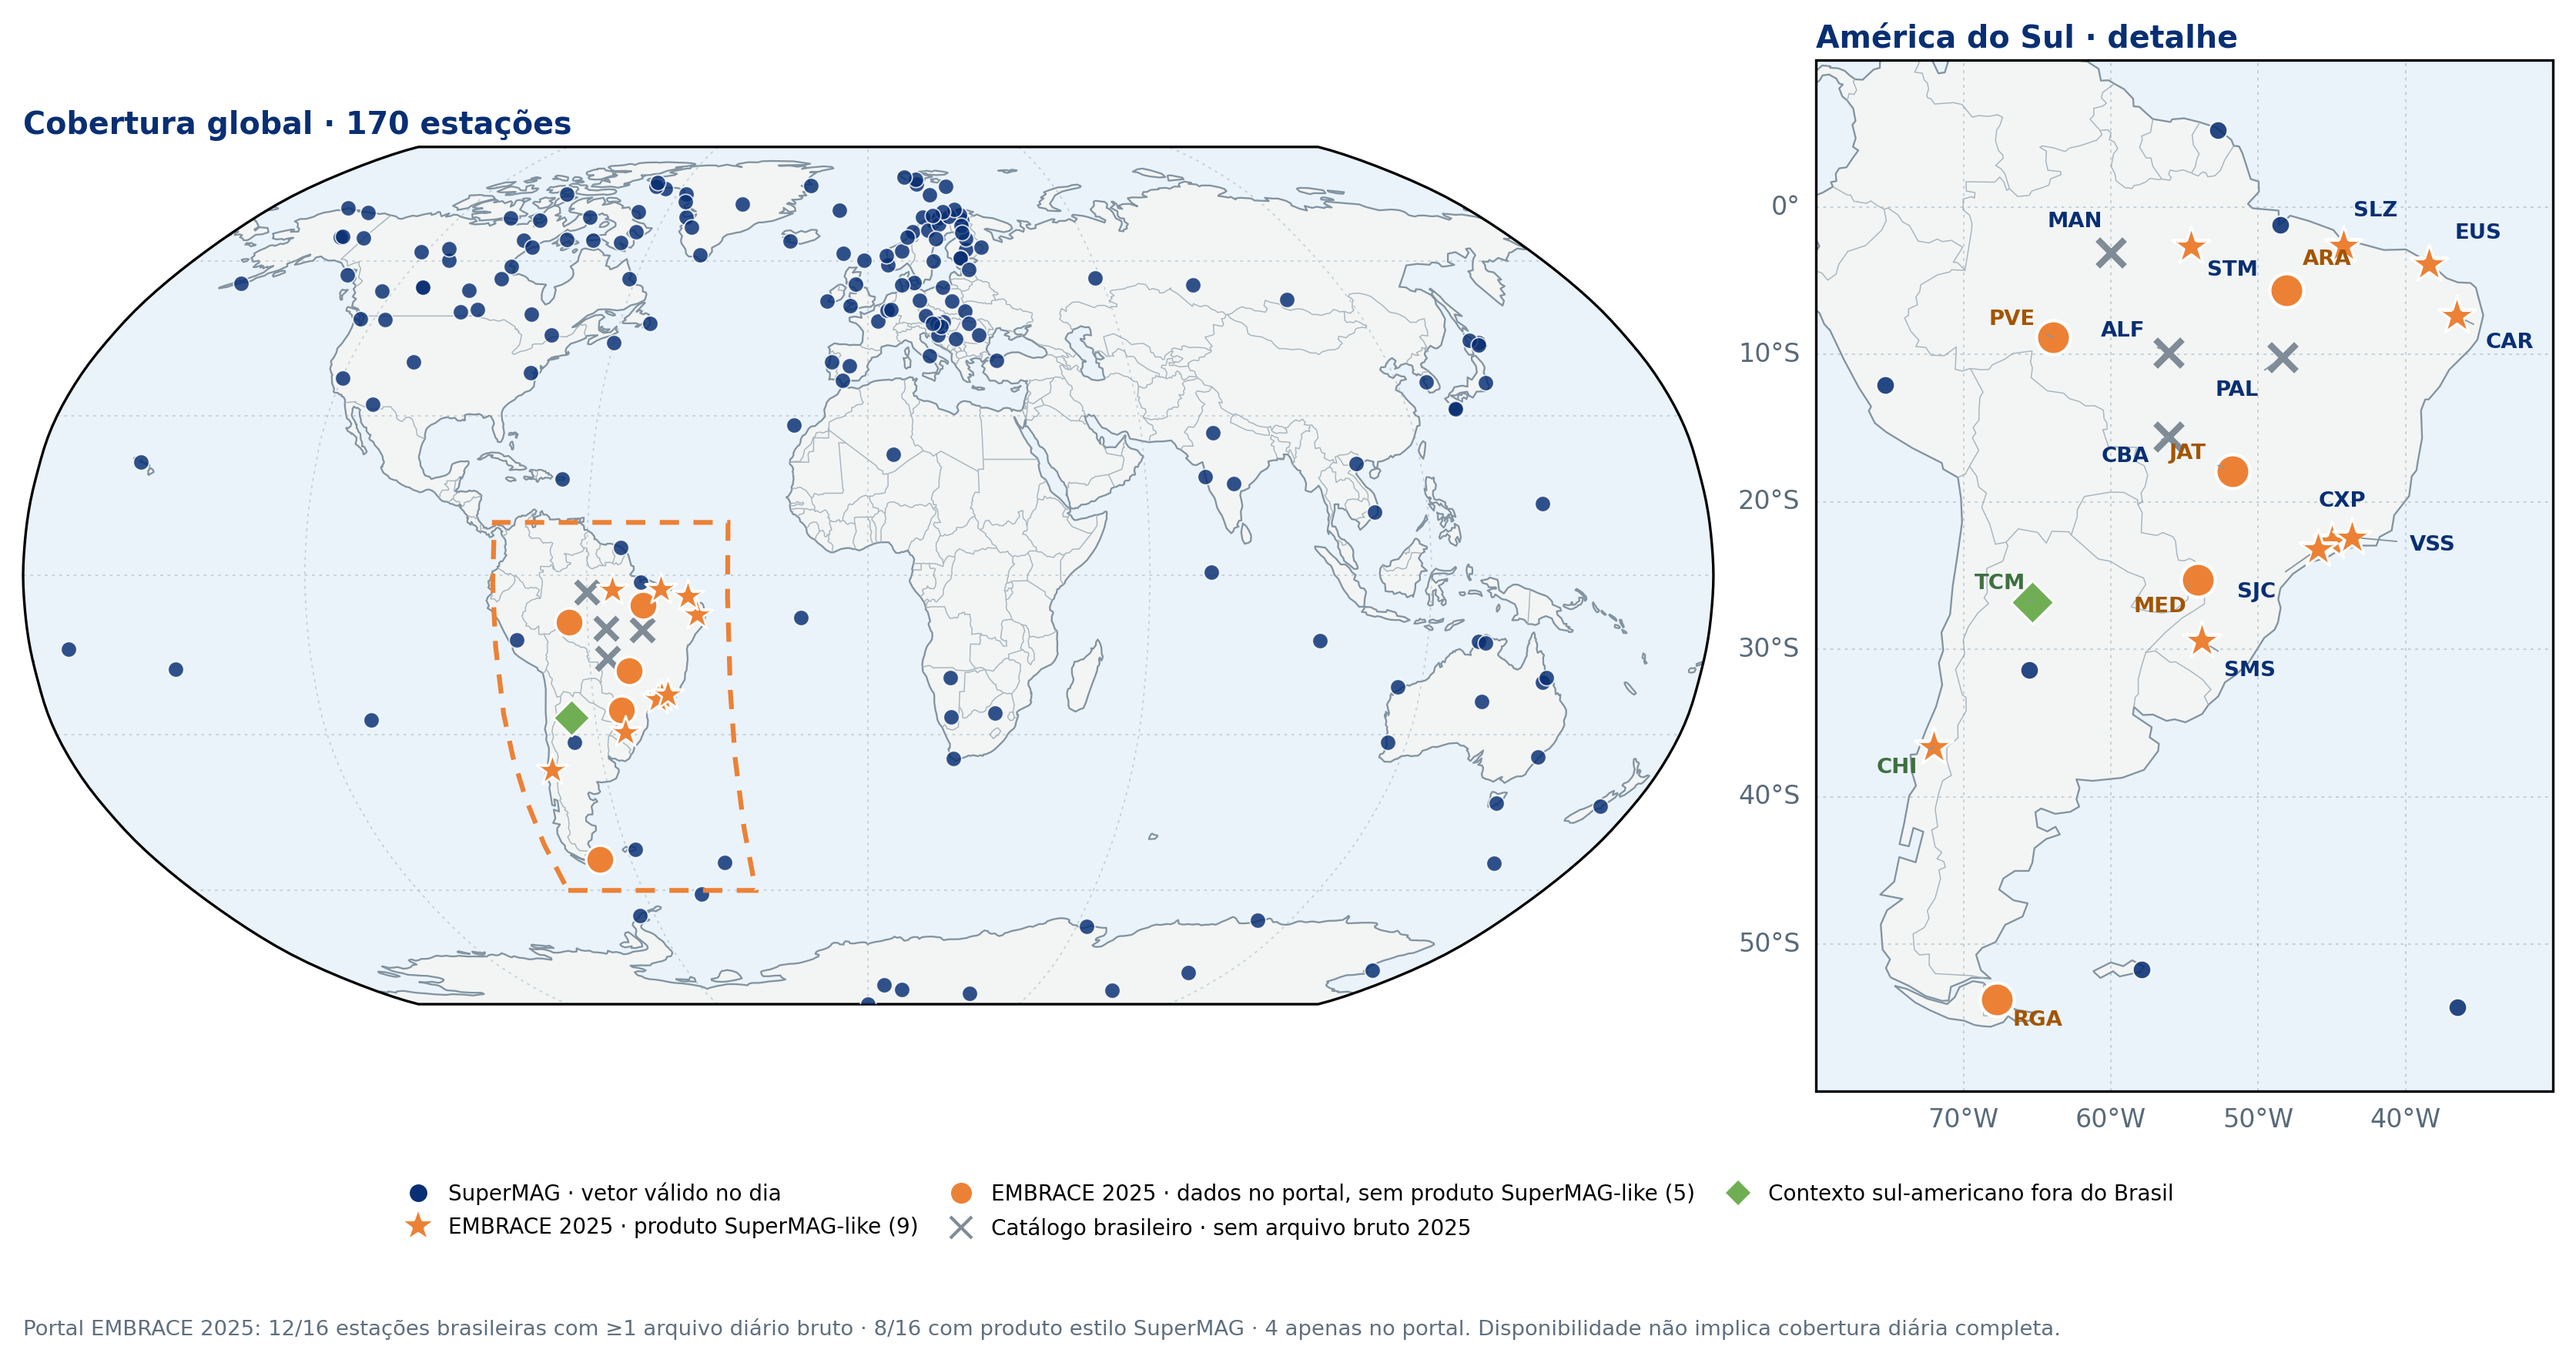

SuperMAG stations represented: 170 | Brazilian catalog: 16
EMBRACE portal raw 2025: ['ARA', 'CAR', 'CXP', 'EUS', 'JAT', 'MED', 'PVE', 'SJC', 'SLZ', 'SMS', 'STM', 'VSS'] | stations with SuperMAG-like product: ['CAR', 'CXP', 'EUS', 'SJC', 'SLZ', 'SMS', 'STM', 'VSS']
Brazilian portal-only stations: ['ARA', 'JAT', 'MED', 'PVE'] | no raw 2025 portal file: ['ALF', 'CBA', 'MAN', 'PAL']
South American context with raw-only portal data: ['RGA']
Portal file manifest: $SBGEA_KEYNOTE_DATA/inputs/embrace/portal/2025_daily_file_manifest.json
Saved keynote map: $SBGEA_KEYNOTE_DATA/outputs/figures/supermag/SuperMAG_station_network_2025.png


In [3]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from html.parser import HTMLParser
from pathlib import Path
import json
import re
from urllib.parse import unquote, urljoin, urlparse
import requests
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

# Stations represented by at least one valid SuperMAG vector in the staged daily product.
sm_station_locations=(supermag.groupby("station",as_index=False)
    .agg(longitude=("longitude","median"),latitude=("latitude","median"),
         first_valid_utc=("time_utc","min")))
sm_station_locations=sm_station_locations.dropna(subset=["longitude","latitude"])

# Brazilian catalog and South American context stations.
brazil_codes={"ALF","ARA","CAR","CBA","CXP","EUS","JAT","MED","MAN","PAL","PVE","SJC","SLZ","STM","SMS","VSS"}
brazil_catalog=STATION_CATALOG[STATION_CATALOG.station.isin(brazil_codes)].copy()
regional_context=STATION_CATALOG[~STATION_CATALOG.station.isin(brazil_codes)].copy()

# Snapshot the official EMBRACE portal's daily 1-minute files. The cached listing
# records filenames and gaps; set REFRESH_PORTAL_2025_INDEX=True to re-query it.
PORTAL_ROOT="https://embracedata.inpe.br/magnetometer/"
PORTAL_MANIFEST=KEYNOTE/"inputs"/"embrace"/"portal"/"2025_daily_file_manifest.json"
PORTAL_MANIFEST.parent.mkdir(parents=True,exist_ok=True)
REFRESH_PORTAL_2025_INDEX=False

class _PortalIndexParser(HTMLParser):
    def __init__(self):
        super().__init__(); self.hrefs=[]
    def handle_starttag(self,tag,attrs):
        if tag.lower()=="a":
            href=dict(attrs).get("href")
            if href: self.hrefs.append(href)

def _portal_links(html):
    parser=_PortalIndexParser(); parser.feed(html); return parser.hrefs

def _fetch_portal_2025_manifest():
    response=requests.get(PORTAL_ROOT,timeout=(15,60)); response.raise_for_status()
    catalog_codes=set(STATION_CATALOG.station)
    station_urls={}
    for href in _portal_links(response.text):
        parsed=urlparse(urljoin(PORTAL_ROOT,href))
        code=unquote(parsed.path.rstrip("/").split("/")[-1]).upper()
        if code in catalog_codes and parsed.path.endswith("/"):
            station_urls[code]=urljoin(PORTAL_ROOT,href)

    def find_year_folder(code):
        url=station_urls.get(code)
        if not url: return code,None
        page=requests.get(url,timeout=(15,60)); page.raise_for_status()
        for href in _portal_links(page.text):
            name=unquote(urlparse(href).path.rstrip("/").split("/")[-1])
            if name=="2025": return code,urljoin(url,href)
        return code,None

    with ThreadPoolExecutor(max_workers=8) as pool:
        year_urls=dict(pool.map(find_year_folder,sorted(catalog_codes)))

    daily_pattern=re.compile(r"[a-z]{3}\d{2}(?:jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)\.25m$",re.I)
    def list_daily_files(item):
        code,year_url=item
        record={"year_folder_present":bool(year_url),"daily_files":[],"days_by_month":{}}
        if year_url:
            page=requests.get(year_url,timeout=(15,90)); page.raise_for_status()
            names=[]
            for href in _portal_links(page.text):
                name=unquote(urlparse(href).path.rsplit("/",1)[-1])
                if daily_pattern.fullmatch(name) and name[:3].upper()==code:
                    names.append(name)
            record["daily_files"]=sorted(set(names))
            month_counts={}
            for name in record["daily_files"]:
                month=name[-7:-4].lower()
                month_counts[month]=month_counts.get(month,0)+1
            record["days_by_month"]=month_counts
        record["daily_file_count"]=len(record["daily_files"])
        record["has_2025_raw_data"]=record["daily_file_count"]>0
        return code,record

    with ThreadPoolExecutor(max_workers=8) as pool:
        station_records=dict(pool.map(list_daily_files,sorted(year_urls.items())))
    return {
        "source":PORTAL_ROOT,
        "retrieved_utc":datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "description":"Directory listing of daily 1-minute EMBRACE .25m files for 2025; file presence is not full-year completeness.",
        "stations":station_records,
    }

if REFRESH_PORTAL_2025_INDEX or not PORTAL_MANIFEST.exists():
    portal_manifest=_fetch_portal_2025_manifest()
    PORTAL_MANIFEST.write_text(json.dumps(portal_manifest,indent=2,ensure_ascii=False)+"\n",encoding="utf-8")
else:
    portal_manifest=json.loads(PORTAL_MANIFEST.read_text(encoding="utf-8"))
portal_2025_codes={code for code,record in portal_manifest["stations"].items()
                   if record.get("has_2025_raw_data")}

# Local files are the processed SuperMAG-like annual products; portal files are raw.
style_2025_codes=set(embrace_files.station)
style_available=STATION_CATALOG[STATION_CATALOG.station.isin(style_2025_codes)].copy()
portal_raw_only=STATION_CATALOG[
    STATION_CATALOG.station.isin(portal_2025_codes-style_2025_codes)].copy()
brazil_with_portal=brazil_catalog[brazil_catalog.station.isin(portal_2025_codes)]
brazil_with_style=brazil_catalog[brazil_catalog.station.isin(style_2025_codes)]
brazil_portal_only=brazil_catalog[brazil_catalog.station.isin(portal_2025_codes-style_2025_codes)]
brazil_without_2025=brazil_catalog[
    ~brazil_catalog.station.isin(portal_2025_codes|style_2025_codes)]
context_without_data=regional_context[
    ~regional_context.station.isin(portal_2025_codes|style_2025_codes)]

NAVY="#082F73"; BLUE="#2686D0"; GREEN="#70AE54"; ORANGE="#EC8135"
PALE_LAND="#F2F5F4"; PALE_WATER="#EAF3FA"; GRID="#91A4B5"; MUTED="#7F8B96"
PLATE=ccrs.PlateCarree()

fig=plt.figure(figsize=(11.5,5.8),dpi=300,facecolor="white")
gs=fig.add_gridspec(1,2,left=.025,right=.99,bottom=.20,top=.97,
                    width_ratios=[2.1,1.0],wspace=.055)
ax_world=fig.add_subplot(gs[0,0],projection=ccrs.Robinson(central_longitude=0))
ax_region=fig.add_subplot(gs[0,1],projection=PLATE)
for ax in (ax_world,ax_region):
    ax.set_facecolor(PALE_WATER)
    ax.add_feature(cfeature.OCEAN.with_scale("110m"),facecolor=PALE_WATER,zorder=0)
    ax.add_feature(cfeature.LAND.with_scale("110m"),facecolor=PALE_LAND,edgecolor="none",zorder=1)
    ax.add_feature(cfeature.COASTLINE.with_scale("110m"),edgecolor="#8293A1",linewidth=.55,zorder=2)
    ax.add_feature(cfeature.BORDERS.with_scale("110m"),edgecolor="#A8B4BD",linewidth=.35,zorder=2)

ax_world.set_global()
gl=ax_world.gridlines(crs=PLATE,draw_labels=False,linewidth=.45,color=GRID,alpha=.42,
                       linestyle=(0,(2,3)),zorder=1.5)
gl.xlocator=plt.FixedLocator(np.arange(-180,181,60)); gl.ylocator=plt.FixedLocator(np.arange(-60,61,30))
ax_world.scatter(sm_station_locations.longitude,sm_station_locations.latitude,
    transform=PLATE,s=24,color=NAVY,edgecolors="white",linewidths=.42,alpha=.83,zorder=4)

# A small X means the Brazilian catalog station has no raw 2025 portal file.
ax_world.scatter(brazil_without_2025.longitude,brazil_without_2025.latitude,
    transform=PLATE,s=48,marker="x",color=MUTED,linewidths=1.8,zorder=6)
# Filled orange circles are raw portal data with no local SuperMAG-like product.
ax_world.scatter(portal_raw_only.longitude,portal_raw_only.latitude,
    transform=PLATE,s=78,marker="o",facecolors=ORANGE,edgecolors="white",
    linewidths=.8,zorder=7)
# Stars mark the processed SuperMAG-like 2025 product, including CHI in context.
ax_world.scatter(style_available.longitude,style_available.latitude,
    transform=PLATE,s=108,marker="*",color=ORANGE,edgecolors="white",
    linewidths=.65,zorder=8)
ax_world.scatter(context_without_data.longitude,context_without_data.latitude,
    transform=PLATE,s=65,marker="D",color=GREEN,edgecolors="white",
    linewidths=.65,zorder=6)
ax_world.add_patch(Rectangle((-80,-60),50,70,transform=PLATE,facecolor="none",
    edgecolor=ORANGE,linewidth=1.5,linestyle=(0,(4,3)),zorder=9))
ax_world.set_title(f"Cobertura global · {len(sm_station_locations)} estações",
                   loc="left",fontsize=9.5,fontweight="bold",color=NAVY,pad=4)

ax_region.set_extent([-80,-30,-60,10],crs=PLATE)
gr=ax_region.gridlines(crs=PLATE,draw_labels=True,linewidth=.45,color=GRID,alpha=.48,
                       linestyle=(0,(2,3)),zorder=1.5)
gr.top_labels=False; gr.right_labels=False
gr.xlabel_style={"size":8,"color":"#586A79"}; gr.ylabel_style={"size":8,"color":"#586A79"}
region_sm=sm_station_locations[
    sm_station_locations.longitude.between(-80,-30)&sm_station_locations.latitude.between(-60,10)]
if len(region_sm):
    ax_region.scatter(region_sm.longitude,region_sm.latitude,transform=PLATE,s=32,color=NAVY,
        edgecolors="white",linewidths=.5,alpha=.88,zorder=4)
ax_region.scatter(brazil_without_2025.longitude,brazil_without_2025.latitude,
    transform=PLATE,s=70,marker="x",color=MUTED,linewidths=2.0,zorder=6)
ax_region.scatter(portal_raw_only.longitude,portal_raw_only.latitude,
    transform=PLATE,s=112,marker="o",facecolors=ORANGE,edgecolors="white",
    linewidths=1.0,zorder=7)
ax_region.scatter(style_available.longitude,style_available.latitude,
    transform=PLATE,s=155,marker="*",color=ORANGE,edgecolors="white",
    linewidths=.75,zorder=8)
ax_region.scatter(context_without_data.longitude,context_without_data.latitude,
    transform=PLATE,s=90,marker="D",color=GREEN,edgecolors="white",
    linewidths=.7,zorder=6)

# Offsets keep dense station labels legible in the regional inset.
label_offsets={"SJC":(-25,-15),"CXP":(-4,11),"VSS":(18,-4),
               "CAR":(9,-10),"EUS":(8,8),"SLZ":(3,9),"STM":(5,-9),
               "ALF":(-21,5),"CBA":(-21,-8),"ARA":(5,8),"PAL":(-21,-12),
               "JAT":(-20,4),"MED":(-20,-10),"SMS":(7,-11),"MAN":(-20,8),
               "PVE":(-20,4),"CHI":(-18,-8),"TCM":(-18,4),"RGA":(5,-8)}
for row in STATION_CATALOG.itertuples():
    dx,dy=label_offsets.get(row.station,(5,5))
    if row.station in portal_raw_only.station.values:
        label_color="#A35400"
    elif row.station in style_2025_codes and row.station not in brazil_codes:
        label_color="#3F7040"
    elif row.station in brazil_codes:
        label_color=NAVY
    else:
        label_color="#3F7040"
    ax_region.annotate(row.station,(row.longitude,row.latitude),
        xycoords=PLATE._as_mpl_transform(ax_region),xytext=(dx,dy),textcoords="offset points",
        fontsize=6.6,fontweight="bold",color=label_color,
        arrowprops={"arrowstyle":"-","color":"#8796A2","lw":.45,"shrinkA":2,"shrinkB":3}
        if abs(dx)+abs(dy)>17 else None,zorder=10)
ax_region.set_title("América do Sul · detalhe",loc="left",fontsize=9.5,
                    fontweight="bold",color=NAVY,pad=4)

legend_handles=[
    Line2D([],[],marker="o",ls="",markersize=6.5,color=NAVY,markeredgecolor="white",
           label="SuperMAG · vetor válido no dia"),
    Line2D([],[],marker="*",ls="",markersize=12,color=ORANGE,markeredgecolor="white",
           label=f"EMBRACE 2025 · produto SuperMAG-like ({len(style_available)})"),
    Line2D([],[],marker="o",ls="",markersize=7.5,color=ORANGE,markeredgecolor="white",
           label=f"EMBRACE 2025 · dados no portal, sem produto SuperMAG-like ({len(portal_raw_only)})"),
    Line2D([],[],marker="x",ls="",markersize=6.5,color=MUTED,
           label="Catálogo brasileiro · sem arquivo bruto 2025"),
    Line2D([],[],marker="D",ls="",markersize=6.5,color=GREEN,markeredgecolor="white",
           label="Contexto sul-americano fora do Brasil"),
]
fig.legend(handles=legend_handles,loc="lower center",bbox_to_anchor=(.5,.075),
           ncol=3,frameon=False,fontsize=6.7,columnspacing=1.0,handletextpad=.4,
           labelspacing=.55)
fig.text(.025,.018,
    f"Portal EMBRACE 2025: {len(brazil_with_portal)}/{len(brazil_catalog)} estações brasileiras com ≥1 arquivo diário bruto · "
    f"{len(brazil_with_style)}/{len(brazil_catalog)} com produto estilo SuperMAG · {len(brazil_portal_only)} apenas no portal. "
    "Disponibilidade não implica cobertura diária completa.",
    ha="left",fontsize=6.6,color="#5F6F7E")
fig.savefig(OUT_FIG/"SuperMAG_station_network_2025.png",dpi=300,facecolor="white")
plt.show()
print("SuperMAG stations represented:",len(sm_station_locations),"| Brazilian catalog:",len(brazil_catalog))
print("EMBRACE portal raw 2025:",sorted(brazil_with_portal.station.tolist()),
      "| stations with SuperMAG-like product:",sorted(brazil_with_style.station.tolist()))
print("Brazilian portal-only stations:",sorted(brazil_portal_only.station.tolist()),
      "| no raw 2025 portal file:",sorted(brazil_without_2025.station.tolist()))
print("South American context with raw-only portal data:",
      sorted(set(portal_raw_only.station)-set(brazil_catalog.station)))
print("Portal file manifest:",PORTAL_MANIFEST)
print("Saved keynote map:",OUT_FIG/"SuperMAG_station_network_2025.png")


## Índices SuperMAG e Dst de 2025: dados pelo HAPI

O registro público do [HAPI](https://hapi-server.org/) contém o conjunto `ground-based-sme` do servidor AMDA. Seus metadados indicam amostragem de 1 minuto e cobertura de 1975 a 7 de maio de 2026; o conjunto inclui `SME`, `SML` e `SMU`, portanto cobre 2025. O índice horário `Dst` vem do conjunto `hour_dst` do WDC Kyoto, disponível no HAPI e definido como a melhor versão disponível (Final > Provisória > Tempo real). As figuras identificam a versão servida para 2025.

O HAPI da AMDA não publica `SMR` nem os quatro setores `SMR-LT`. Para completar o foco em tempestades, o notebook obtém `SMR` e `SMR-LT` do serviço público de índices do SuperMAG. Procedência por variável: `SME/SML/SMU` via HAPI/AMDA; `Dst` via HAPI/WDC Kyoto; `SMR/SMR-LT` via SuperMAG. O conjunto HAPI legado da KNMI é mostrado apenas como comparação: sua cobertura termina em 2023. Metadados e respostas HAPI ficam em `KEYNOTE/inputs/hapi/`: as séries SME/SML/SMU são armazenadas em CSV mensal e Dst em CSV anual. Cada execução valida e lê esses arquivos locais primeiro; só baixa novamente um arquivo ausente ou inválido.

In [5]:
import json
from io import StringIO
import requests

HAPI_REGISTRY="https://hapi-server.org/servers/all.txt"
HAPI_BASE="https://amda.irap.omp.eu/service/hapi"
HAPI_DATASET="ground-based-sme"
DST_HAPI_BASE="https://wdc.kugi.kyoto-u.ac.jp/hapi"
DST_DATASET="hour_dst"
HAPI_CACHE_ROOT=KEYNOTE/"inputs"/"hapi"
HAPI_METADATA_CACHE=HAPI_CACHE_ROOT/"metadata"
HAPI_METADATA_CACHE.mkdir(parents=True,exist_ok=True)
HAPI_CACHE_ROOT.mkdir(parents=True,exist_ok=True)

def _atomic_cache_text(path,text):
    """Write a complete cache file atomically so interrupted downloads are ignored."""
    path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_name(path.name+".part")
    temporary.write_text(text,encoding="utf-8")
    temporary.replace(path)

def _cached_text(path,url,params=None,validator=None):
    """Read a valid local HAPI response first; fetch and cache only when missing/bad."""
    if path.exists() and path.stat().st_size:
        cached=path.read_text(encoding="utf-8")
        if validator is None or validator(cached):
            return cached,"cache"
    response=requests.get(url,params=params,timeout=(20,60))
    response.raise_for_status()
    text=response.text
    if not text.strip() or (validator is not None and not validator(text)):
        raise RuntimeError(f"HAPI returned an empty or invalid response for {url}")
    _atomic_cache_text(path,text)
    return text,"network"

def _cached_json(path,url,params=None):
    def _valid_json(text):
        try:
            json.loads(text)
            return True
        except (json.JSONDecodeError,TypeError):
            return False
    text,source=_cached_text(path,url,params=params,validator=_valid_json)
    return json.loads(text),source

registry_text,registry_source=_cached_text(
    HAPI_METADATA_CACHE/"hapi_server_registry_all.txt",HAPI_REGISTRY,
    validator=lambda text: bool(text.strip()))
hapi_registry_match=[line for line in registry_text.splitlines() if HAPI_BASE in line]
if not hapi_registry_match:
    raise RuntimeError("AMDA HAPI server was not found in the cached public HAPI registry.")

hapi_info,hapi_info_source=_cached_json(
    HAPI_METADATA_CACHE/"amda_ground_based_sme_info.json",
    f"{HAPI_BASE}/info",{"id":HAPI_DATASET})
hapi_start=pd.Timestamp(hapi_info["startDate"])
hapi_stop=pd.Timestamp(hapi_info["stopDate"])
hapi_parameters=[item["name"] for item in hapi_info.get("parameters",[])]
required_hapi_parameters={"sme","sml","smu"}
if not required_hapi_parameters.issubset({name.lower() for name in hapi_parameters}):
    raise RuntimeError(f"Unexpected HAPI parameters for {HAPI_DATASET}: {hapi_parameters}")
if hapi_start>pd.Timestamp("2025-01-01",tz="UTC") or hapi_stop<pd.Timestamp("2025-12-31T23:59:00Z"):
    raise RuntimeError(f"The AMDA HAPI dataset does not cover all of 2025: {hapi_info['startDate']} to {hapi_info['stopDate']}")

def _valid_probe(text):
    rows=[line for line in text.splitlines() if line.strip() and not line.lstrip().startswith("#")]
    if not rows:
        return False
    try:
        first=pd.read_csv(StringIO("\n".join(rows)),header=None)
        return first.shape[1]==4 and len(first)>0
    except (pd.errors.ParserError,ValueError):
        return False

hapi_probe_cache=HAPI_METADATA_CACHE/"amda_ground_based_sme_probe_2025.csv"
hapi_probe_text,hapi_probe_source=_cached_text(hapi_probe_cache,f"{HAPI_BASE}/data",{
    "id":HAPI_DATASET,
    "time.min":"2025-01-01T00:00:00Z",
    "time.max":"2025-01-01T00:05:00Z",
    "parameters":"sme,sml,smu",
    "format":"csv",
},validator=_valid_probe)
hapi_probe_rows=[line for line in hapi_probe_text.splitlines() if line.strip()]

knmi_info,knmi_source=_cached_json(
    HAPI_METADATA_CACHE/"knmi_supermag_sme_index_info.json",
    "https://hapi.spaceweather.knmi.nl/hapi/info",{"id":"supermag_sme_index"})
dst_info,dst_info_source=_cached_json(
    HAPI_METADATA_CACHE/"wdc_kyoto_hour_dst_info.json",
    f"{DST_HAPI_BASE}/info",{"id":DST_DATASET})

(HAPI_CACHE_ROOT/"README.txt").write_text(
    "HAPI data cache for the SuperMAG 2025 analysis.\n"
    "AMDA ground-based-sme: one-minute SME/SML/SMU, cached as original monthly CSV payloads.\n"
    "WDC Kyoto hour_dst: hourly Dst and versionCode, cached as the original annual CSV payload.\n"
    "Dataset metadata, HAPI registry snapshot, and a small availability probe are under metadata/.\n",
    encoding="utf-8")
print("HAPI registry source:",registry_source,"| AMDA metadata:",hapi_info_source,
      "| probe:",hapi_probe_source,"| Kyoto Dst metadata:",dst_info_source)
print("HAPI registry entry:",hapi_registry_match[0])
print("HAPI dataset:",HAPI_DATASET,"| provider:",hapi_info.get("description","AMDA"))
print("HAPI coverage:",hapi_info["startDate"],"to",hapi_info["stopDate"])
print("HAPI parameters:",hapi_parameters)
print("2025 HAPI probe:",len(hapi_probe_rows),"records; first row:",hapi_probe_rows[0])
print("Separate KNMI dataset ends:",knmi_info["stopDate"],"| parameters:",
      [item["name"] for item in knmi_info.get("parameters",[])])
print("Dst HAPI:",DST_DATASET,"|",dst_info.get("title"),"| cadence:",dst_info.get("cadence"),
      "| coverage:",dst_info["startDate"],"to",dst_info["stopDate"])


HAPI registry source: cache | AMDA metadata: cache | probe: cache | Kyoto Dst metadata: cache
HAPI registry entry: https://amda.irap.omp.eu/service/hapi, AMDA, AMDA, Vincent Génot, amda@irap.omp.eu
HAPI dataset: ground-based-sme | provider: SuperMAG SML, SMU, SME indices<br/> Sampling: 1M<br/> Provider: SuperMAG
HAPI coverage: 1975-01-01T00:00:00Z to 2026-05-07T23:59:00Z
HAPI parameters: ['Time', 'sme', 'smu', 'sml']
2025 HAPI probe: 6 records; first row: 2025-01-01T00:00:00.000Z,567.271,-313.062,254.208
Separate KNMI dataset ends: 2023-12-31T23:58:00.000000Z | parameters: ['time', 'smu', 'sml']
Dst HAPI: hour_dst | Dst Index (Best Available, 1-hour) | cadence: PT1H | coverage: 1957-01-01T00:29:30Z to 2026-10-28T22:29:30Z


### Índices de tempestade e eletrojato auroral

`SME`, `SML` e `SMU` vêm do conjunto HAPI/AMDA em cadência de 1 minuto. `SMR` acompanha a corrente de anel, enquanto `SMR00/06/12/18` representam quatro setores de horário magnético local; esses campos vêm do serviço de índices SuperMAG porque não estão expostos no conjunto HAPI da AMDA. O `Dst` horário vem do WDC Kyoto via HAPI. Para 2025, o HAPI serve a versão provisória (`versionCode=10`); ela pode ser revisada quando uma versão final for publicada.

O segundo painel mostra Dst horário resumido por dia; os demais painéis mostram os resumos diários para revelar a evolução anual sem esconder episódios intensos. Os limiares `SMR ≤ −50 nT` e `SMR ≤ −100 nT` são guias visuais, não uma classificação oficial de tempestades. As lacunas são preservadas, sem interpolação.

SuperMAG SMR Jan: 44,641 rows


SuperMAG SMR Feb: 40,321 rows


SuperMAG SMR Mar: 44,641 rows


SuperMAG SMR Apr: 43,201 rows


SuperMAG SMR May: 44,641 rows


SuperMAG SMR Jun: 43,201 rows


... (4 outputs left out)

SuperMAG SMR Nov: 43,201 rows


SuperMAG SMR Dec: 44,641 rows
HAPI Jan: 44,641 rows (cache)
HAPI Feb: 40,321 rows (cache)
HAPI Mar: 44,641 rows (cache)
HAPI Apr: 43,201 rows (cache)
HAPI May: 44,641 rows (cache)


HAPI Jun: 43,201 rows (cache)
HAPI Jul: 44,641 rows (cache)
HAPI Aug: 44,641 rows (cache)
HAPI Sep: 43,201 rows (cache)
HAPI Oct: 44,641 rows (cache)
HAPI Nov: 43,201 rows (cache)
HAPI Dec: 44,641 rows (cache)


WDC Kyoto Dst: 8,760 hourly rows (cache)
Source split: SME/SML/SMU via HAPI/AMDA; SMR and SMR-LT via SuperMAG index service.
Missing minutes — HAPI SME: 0 | SuperMAG SMR: 0
Unique UTC minutes: 525,600 / 525,600; SMR missing: 0
Dst records: 8,760 hourly; version codes: [10] (provisória); minimum -217 nT at 2025-11-12 04:29:30+00:00
Minimum SMR: -256 nT at 2025-11-12 11:48:00+00:00; minutes <= -50 nT: 22,383; <= -100 nT: 3,982


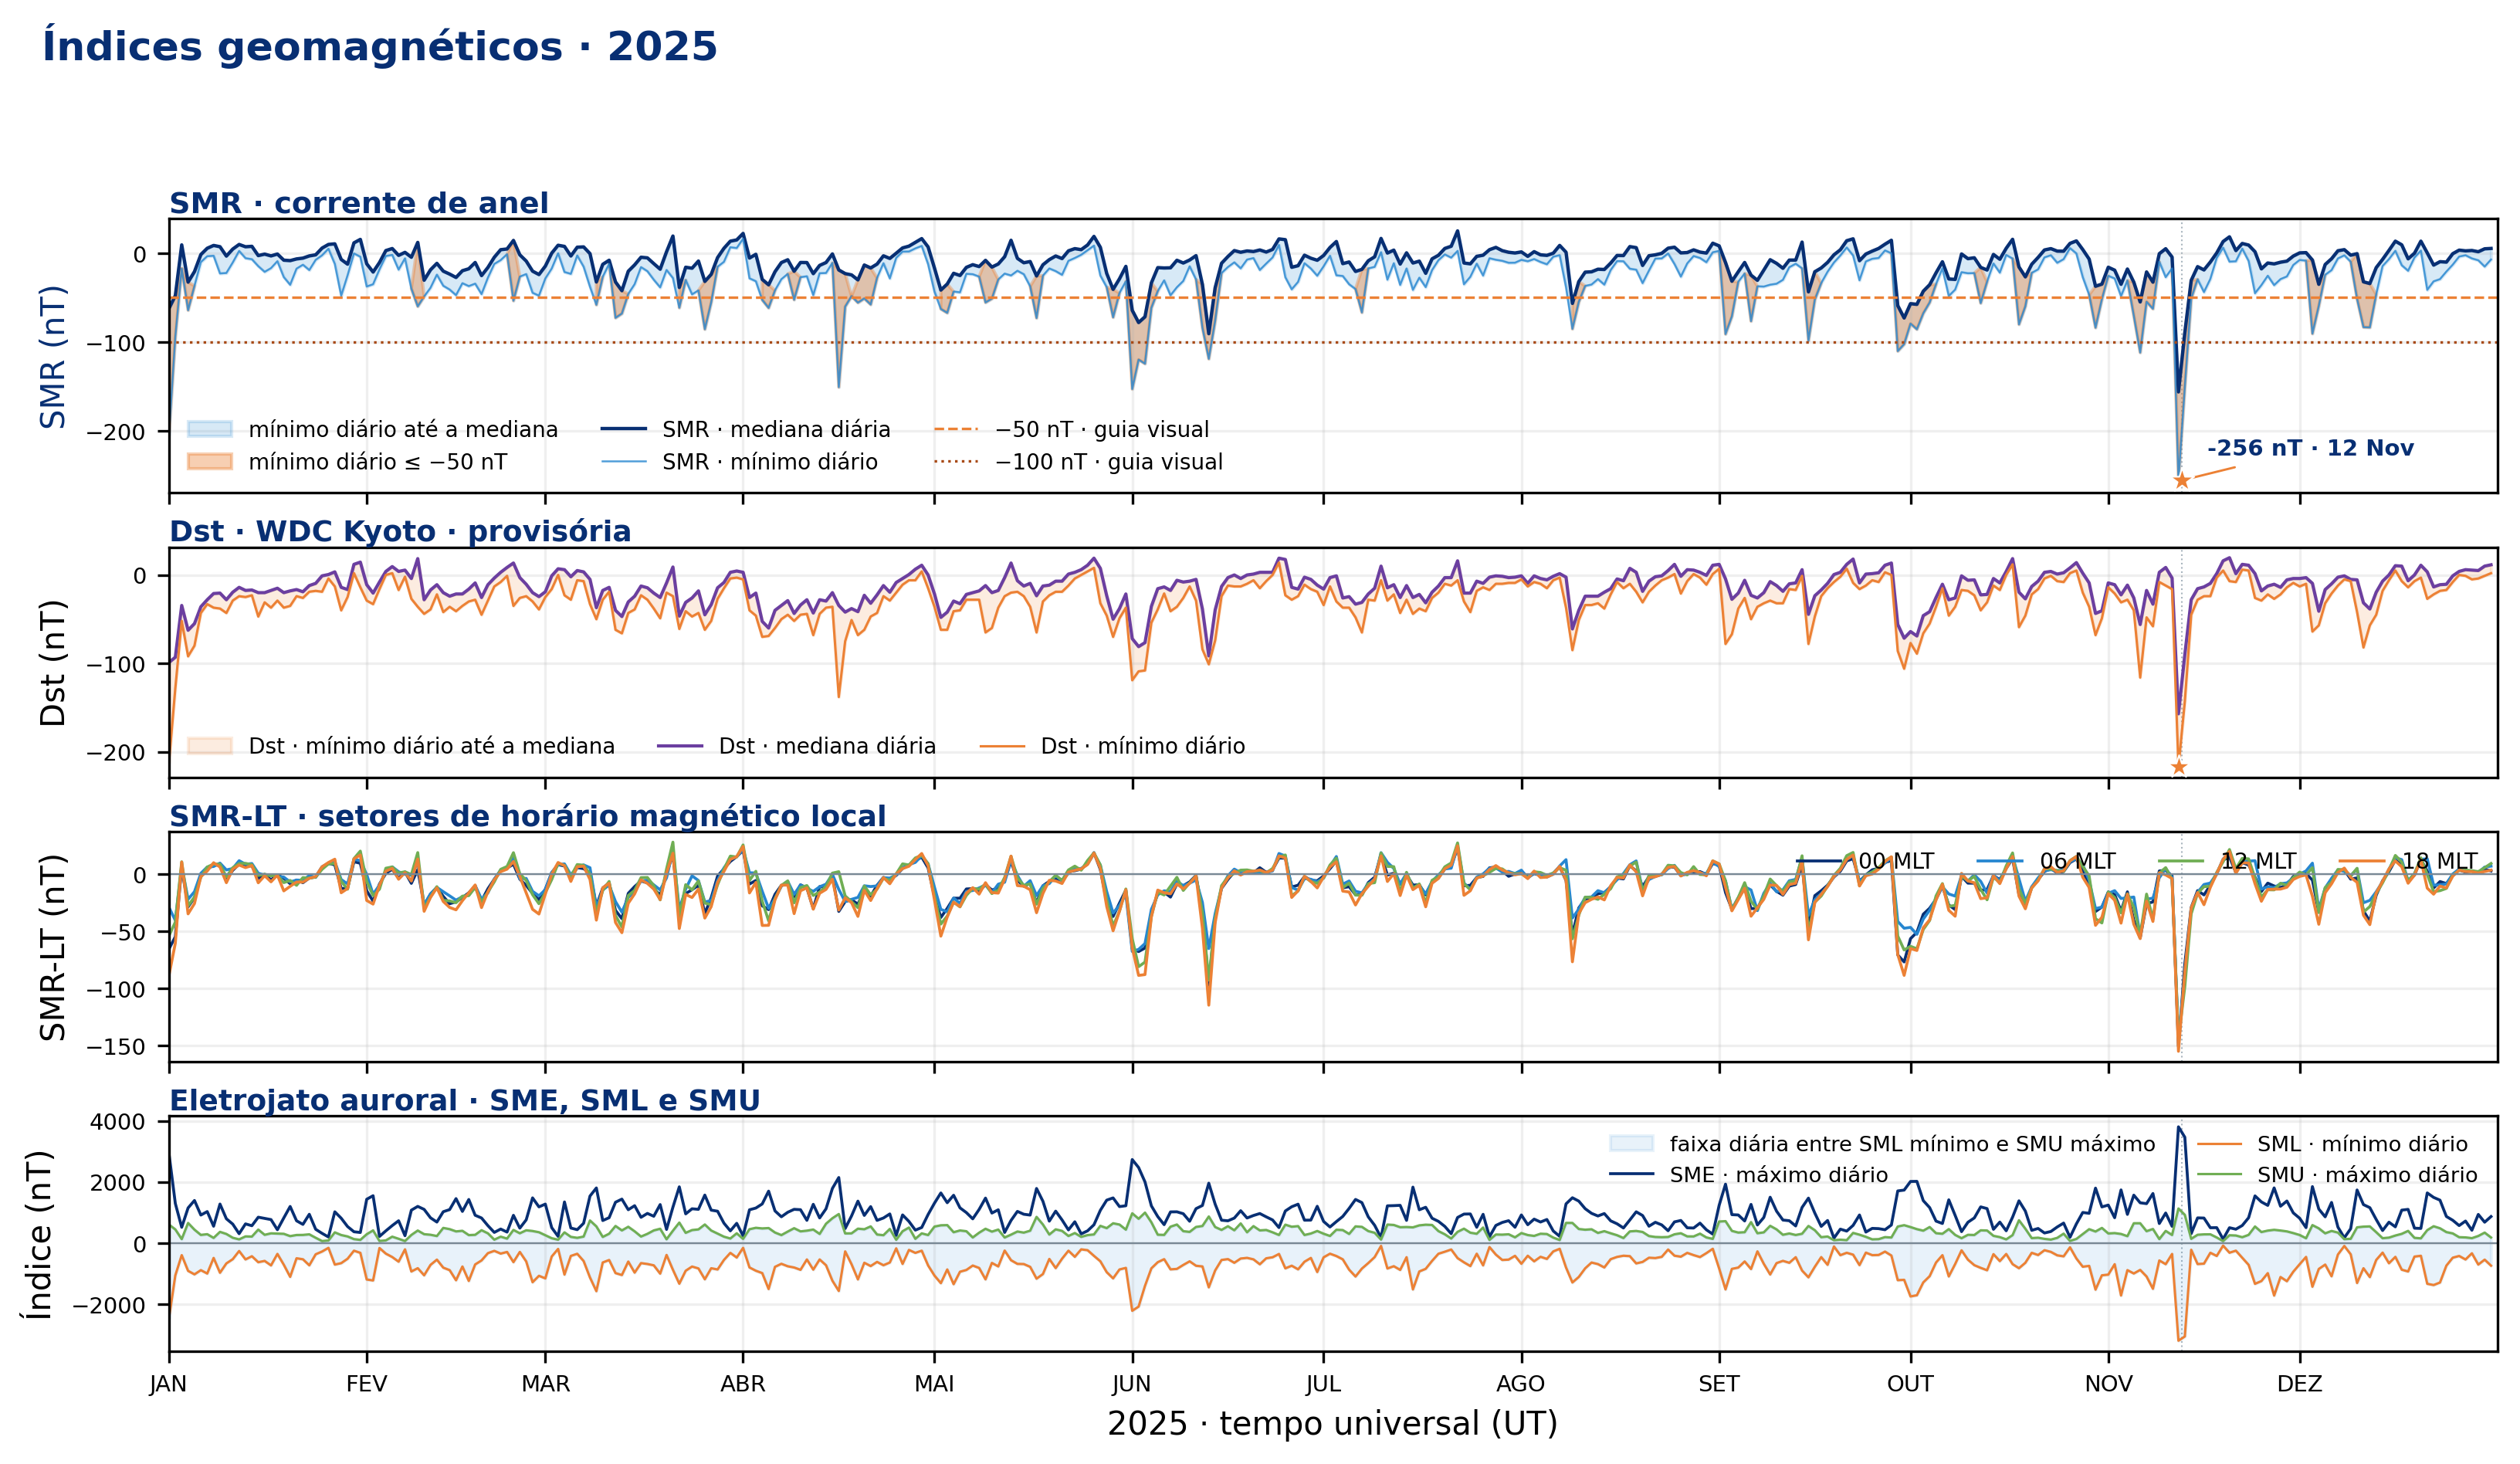

Saved annual index plot: $SBGEA_KEYNOTE_DATA/outputs/figures/supermag/SuperMAG_Indices_2025.png
Saved daily summary: $SBGEA_KEYNOTE_DATA/outputs/data/supermag/SuperMAG_Indices_2025_daily_summary.csv
SuperMAG SMR Apr: 43,201 rows
SuperMAG SMR May: 44,641 rows
SuperMAG SMR Jun: 43,201 rows
SuperMAG SMR Jul: 44,641 rows
SuperMAG SMR Aug: 44,641 rows
SuperMAG SMR Sep: 43,201 rows
SuperMAG SMR Oct: 44,641 rows
SuperMAG SMR Nov: 43,201 rows
SuperMAG SMR Dec: 44,641 rows
HAPI Jan: 44,641 rows (cache)
HAPI Feb: 40,321 rows (cache)
HAPI Mar: 44,641 rows (cache)
HAPI Apr: 43,201 rows (cache)
HAPI May: 44,641 rows (cache)
HAPI Jun: 43,201 rows (cache)
HAPI Jul: 44,641 rows (cache)
HAPI Aug: 44,641 rows (cache)
HAPI Sep: 43,201 rows (cache)
HAPI Oct: 44,641 rows (cache)
HAPI Nov: 43,201 rows (cache)
HAPI Dec: 44,641 rows (cache)
WDC Kyoto Dst: 8,760 hourly rows (cache)
Source split: SME/SML/SMU via HAPI/AMDA; SMR and SMR-LT via SuperMAG index service.
Missing minutes — HAPI SME: 0 | SuperMAG SMR: 

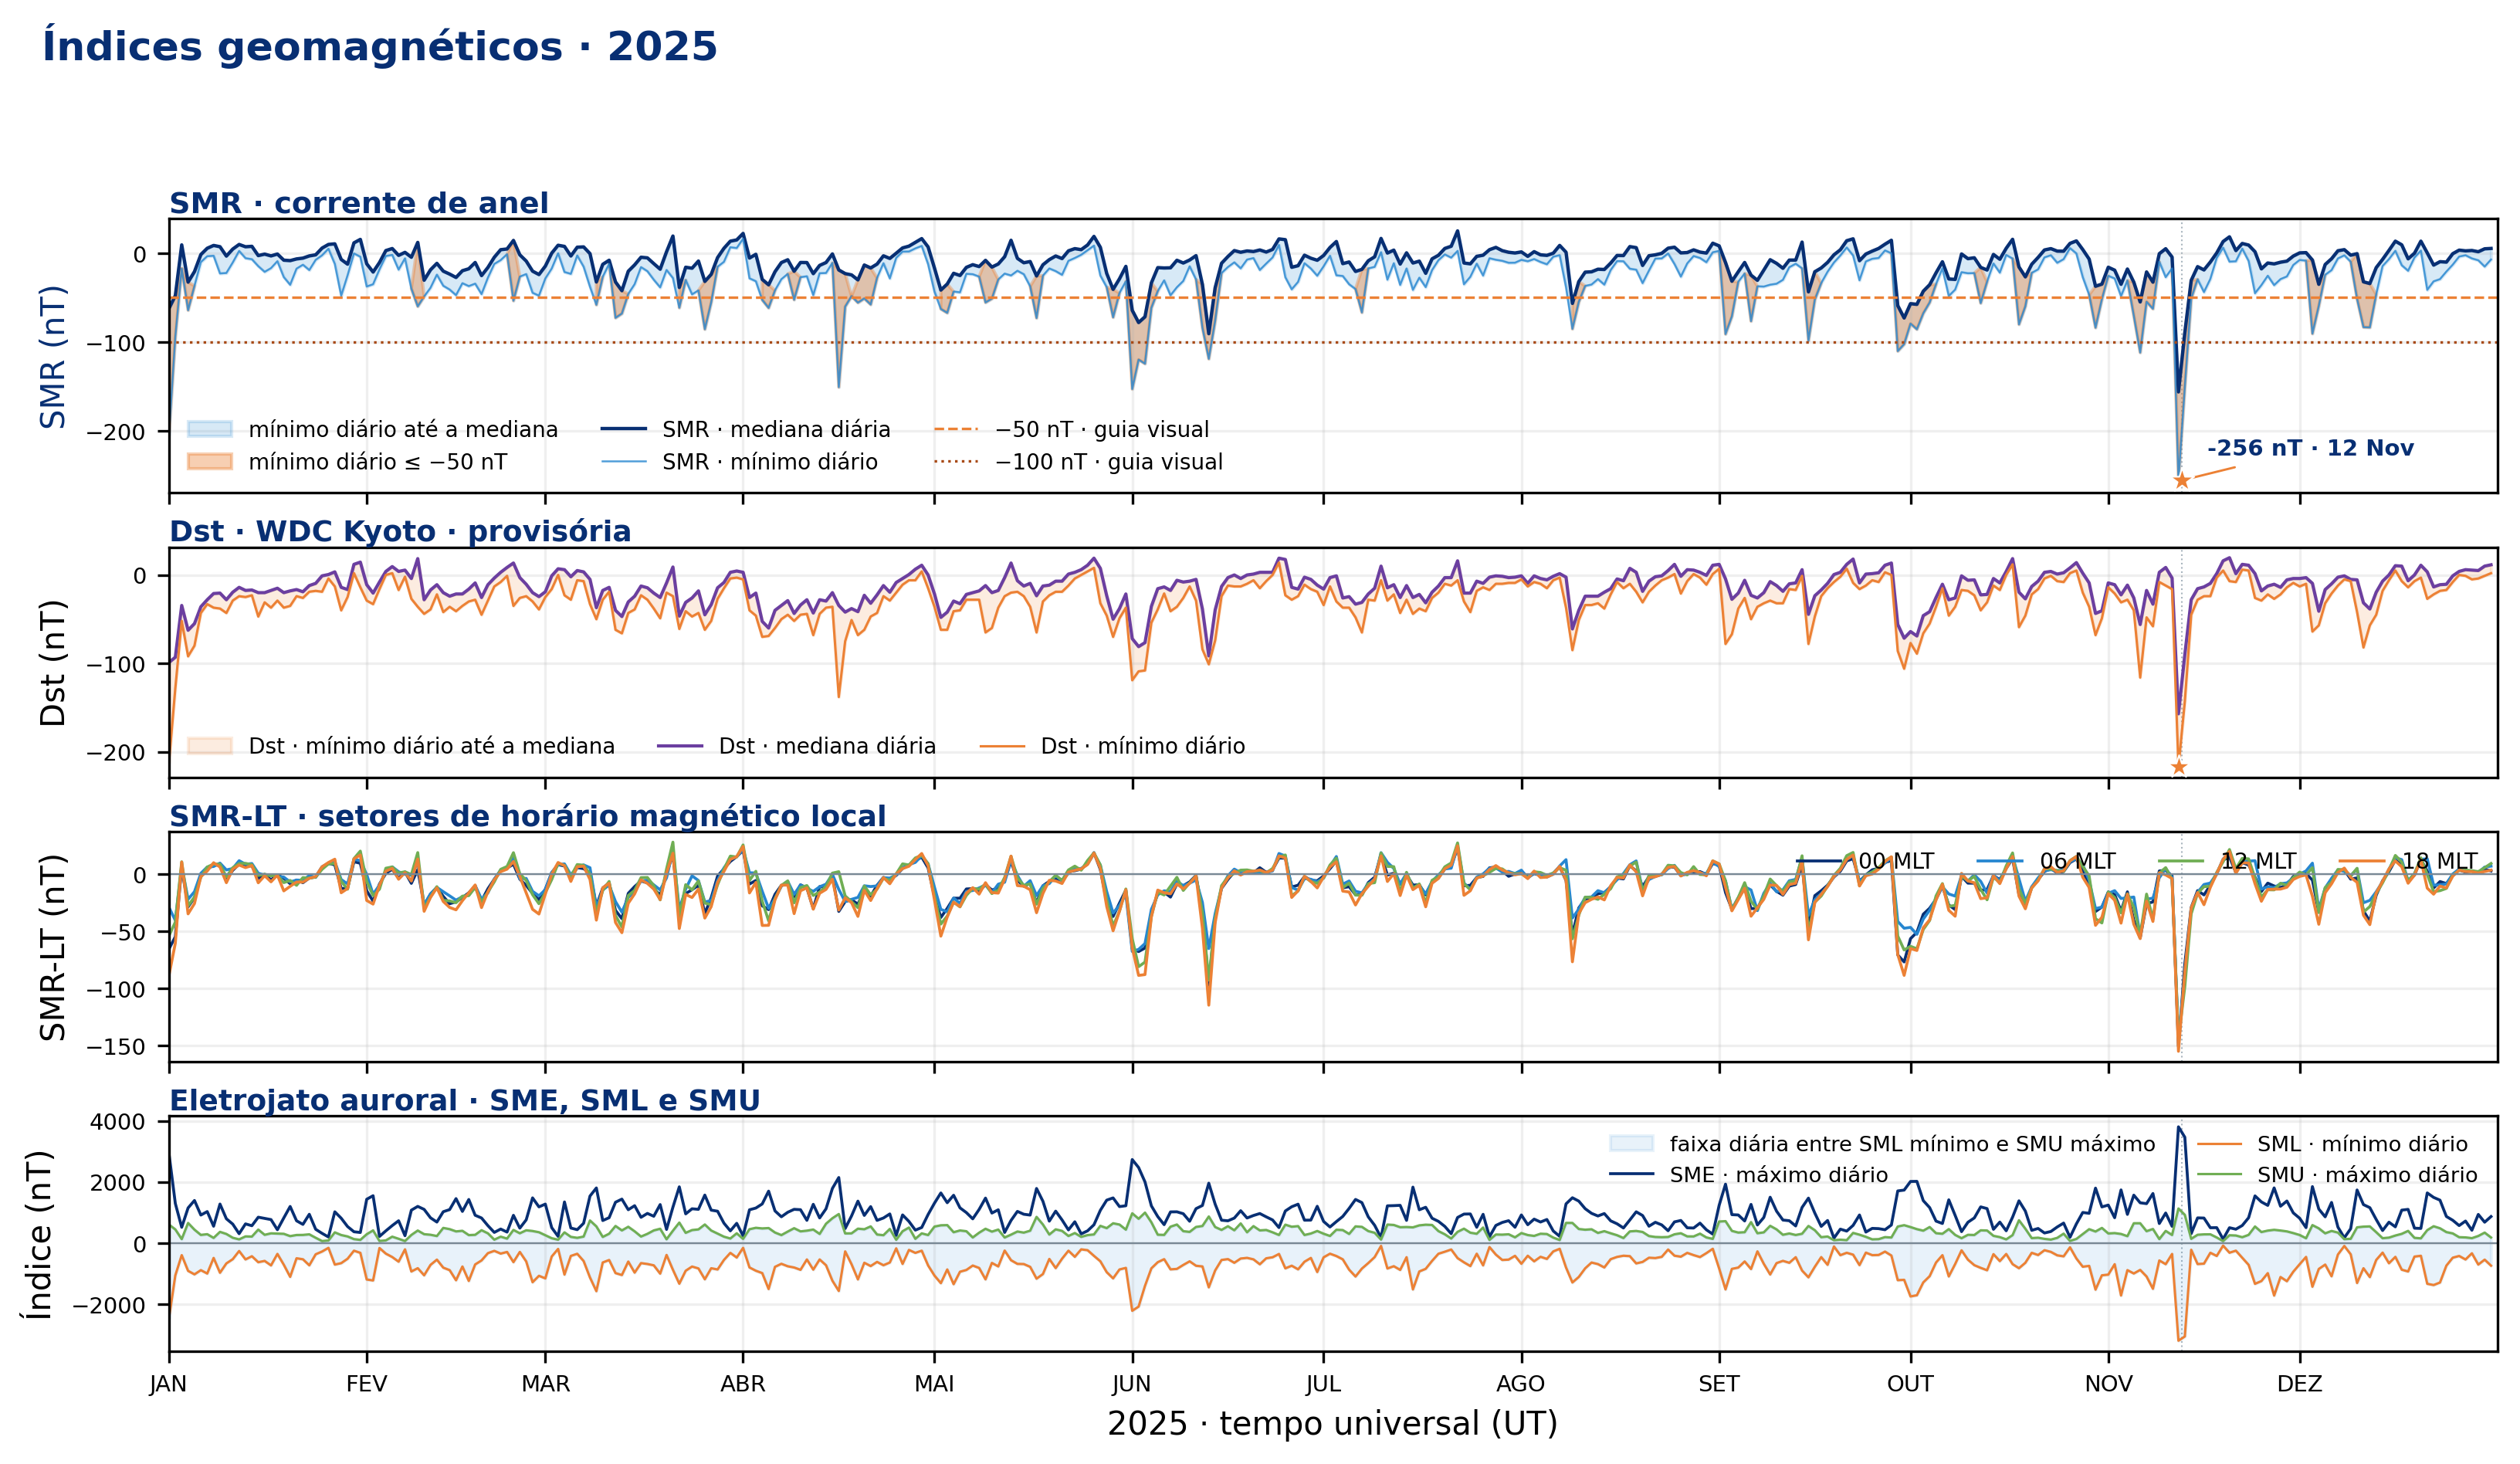

Saved annual index plot: $SBGEA_KEYNOTE_DATA/outputs/figures/supermag/SuperMAG_Indices_2025.png
Saved daily summary: $SBGEA_KEYNOTE_DATA/outputs/data/supermag/SuperMAG_Indices_2025_daily_summary.csv


In [6]:
from io import StringIO
import time as _time

SUPERMag_INDEX_URL="https://supermag.jhuapl.edu/lib/services/"
INDEX_START=pd.Timestamp("2025-01-01T00:00:00Z")
INDEX_STOP=pd.Timestamp("2026-01-01T00:00:00Z")  # exclusive
SMR_FIELDS=["SMR","SMR00","SMR06","SMR12","SMR18"]
HAPI_FIELDS=["SME","SML","SMU"]
INDEX_FIELDS=HAPI_FIELDS+SMR_FIELDS

# Fetch ring-current indices from the official SuperMAG service in modest monthly chunks.
smr_monthly=[]
month_starts=pd.date_range(INDEX_START,INDEX_STOP,freq="MS")
with requests.Session() as session:
    for month_start,month_stop in zip(month_starts[:-1],month_starts[1:]):
        params={
            "service":"indices",
            "downloadtype":"website_request",
            "start":month_start.strftime("%Y-%m-%dT%H:%M"),
            "end":month_stop.strftime("%Y-%m-%dT%H:%M"),
            "indices":"smr,smrlt",
            "imf":"",
            "fmt":"csv",
            "fidelity":"60s",
        }
        response=None
        last_problem=None
        for attempt in range(5):
            try:
                response=session.get(SUPERMag_INDEX_URL,params=params,timeout=(20,120))
                if response.ok and response.text.lstrip("\ufeff").startswith("Date_UTC,"):
                    break
                last_problem=f"HTTP {response.status_code}: {response.text[:150]}"
            except requests.RequestException as exc:
                last_problem=repr(exc)
            if attempt<4:
                _time.sleep(1.0+attempt)
        else:
            raise RuntimeError(f"SuperMAG SMR request failed for {month_start:%Y-%m} after retries: {last_problem}")
        month=pd.read_csv(StringIO(response.text.lstrip("\ufeff")))
        month["Date_UTC"]=pd.to_datetime(month["Date_UTC"],utc=True)
        smr_monthly.append(month)
        print(f"SuperMAG SMR {month_start:%b}: {len(month):,} rows")

smr_data=(pd.concat(smr_monthly,ignore_index=True)
    .drop_duplicates(subset="Date_UTC",keep="first")
    .sort_values("Date_UTC"))
smr_data=smr_data[(smr_data.Date_UTC>=INDEX_START)&(smr_data.Date_UTC<INDEX_STOP)]
for column in SMR_FIELDS:
    smr_data[column]=pd.to_numeric(smr_data[column],errors="coerce")
smr_data=smr_data.set_index("Date_UTC")[SMR_FIELDS]

# Retrieve SME/SML/SMU from LFS cache first. Each original monthly HAPI response
# is downloaded only when its local CSV is missing or fails basic time/shape checks.
HAPI_SME_CACHE_DIR=HAPI_CACHE_ROOT/"amda_ground_based_sme"/"2025"
HAPI_SME_CACHE_DIR.mkdir(parents=True,exist_ok=True)
hapi_monthly=[]

def _parse_sme_month(payload,month_start,month_stop):
    expected_rows=int((month_stop-month_start)/pd.Timedelta(minutes=1))+1
    try:
        frame=pd.read_csv(StringIO(payload),header=None,names=["time_utc",*HAPI_FIELDS])
        if len(frame)!=expected_rows:
            return None
        times=pd.to_datetime(frame["time_utc"],utc=True,errors="coerce")
        expected_times=pd.date_range(month_start,month_stop,freq="min")
        if times.isna().any() or not times.reset_index(drop=True).equals(pd.Series(expected_times)):
            return None
        frame["time_utc"]=times
        return frame
    except (pd.errors.ParserError,ValueError,TypeError):
        return None

with requests.Session() as session:
    for month_start,month_stop in zip(month_starts[:-1],month_starts[1:]):
        cache_file=HAPI_SME_CACHE_DIR/f"ground-based-sme_{month_start:%Y-%m}.csv"
        payload=cache_file.read_text(encoding="utf-8") if cache_file.exists() else None
        month=_parse_sme_month(payload,month_start,month_stop) if payload else None
        source="cache" if month is not None else "network"
        if month is None:
            params={
                "id":HAPI_DATASET,
                "time.min":month_start.strftime("%Y-%m-%dT%H:%M:%SZ"),
                "time.max":month_stop.strftime("%Y-%m-%dT%H:%M:%SZ"),
                "parameters":"sme,sml,smu",
                "format":"csv",
            }
            response=None
            last_problem=None
            for attempt in range(5):
                try:
                    response=session.get(f"{HAPI_BASE}/data",params=params,timeout=(20,120))
                    if response.ok and response.text.strip() and not response.text.lstrip().startswith("{"):
                        break
                    last_problem=f"HTTP {response.status_code}: {response.text[:150]}"
                except requests.RequestException as exc:
                    last_problem=repr(exc)
                if attempt<4:
                    _time.sleep(1.0+attempt)
            else:
                raise RuntimeError(f"AMDA HAPI request failed for {month_start:%Y-%m} after retries: {last_problem}")
            payload=response.text
            month=_parse_sme_month(payload,month_start,month_stop)
            if month is None:
                raise RuntimeError(f"Unexpected HAPI CSV schema or time coverage for {month_start:%Y-%m}")
            temporary=cache_file.with_name(cache_file.name+".part")
            temporary.write_text(payload,encoding="utf-8")
            temporary.replace(cache_file)
        for column in HAPI_FIELDS:
            month[column]=pd.to_numeric(month[column],errors="coerce")
        hapi_monthly.append(month)
        print(f"HAPI {month_start:%b}: {len(month):,} rows ({source}{'; cached now' if source=='network' else ''})")

hapi_data=pd.concat(hapi_monthly,ignore_index=True)
hapi_data=(hapi_data.drop_duplicates(subset="time_utc",keep="first")
    .sort_values("time_utc"))
hapi_data=hapi_data[(hapi_data.time_utc>=INDEX_START)&(hapi_data.time_utc<INDEX_STOP)]
hapi_data=hapi_data.set_index("time_utc")[HAPI_FIELDS]

# Retrieve hourly Dst from the WDC Kyoto HAPI cache. Reuse the annual response
# directly from LFS; refetch only if the cache is absent or fails validation.
DST_CACHE_DIR=HAPI_CACHE_ROOT/"wdc_kyoto_hour_dst"/"2025"
DST_CACHE_DIR.mkdir(parents=True,exist_ok=True)
DST_CACHE_FILE=DST_CACHE_DIR/"hour_dst_2025.csv"
expected_dst=pd.date_range(INDEX_START+pd.Timedelta(minutes=29,seconds=30),
                            INDEX_STOP-pd.Timedelta(minutes=30,seconds=30),freq="h")

def _parse_dst_payload(payload):
    try:
        frame=pd.read_csv(StringIO(payload),header=None,
                          names=["time_utc","Dst_nT","versionCode"])
        frame["time_utc"]=pd.to_datetime(frame["time_utc"],utc=True,errors="coerce")
        frame["Dst_nT"]=pd.to_numeric(frame["Dst_nT"],errors="coerce").replace(99999,np.nan)
        frame["versionCode"]=pd.to_numeric(frame["versionCode"],errors="coerce")
        frame=frame[(frame.time_utc>=INDEX_START)&(frame.time_utc<INDEX_STOP)]
        frame=frame.drop_duplicates("time_utc",keep="first").set_index("time_utc").sort_index()
        if len(frame)!=8760 or frame.Dst_nT.isna().any() or not frame.index.equals(expected_dst):
            return None
        return frame
    except (pd.errors.ParserError,ValueError,TypeError,KeyError):
        return None

cached_dst_payload=(DST_CACHE_FILE.read_text(encoding="utf-8")
                    if DST_CACHE_FILE.exists() and DST_CACHE_FILE.stat().st_size else None)
dst_data=_parse_dst_payload(cached_dst_payload) if cached_dst_payload else None
dst_cache_source="cache" if dst_data is not None else "network"
if dst_data is None:
    dst_response=requests.get(f"{DST_HAPI_BASE}/data",params={
        "id":DST_DATASET,
        "time.min":INDEX_START.strftime("%Y-%m-%dT%H:%M:%SZ"),
        "time.max":INDEX_STOP.strftime("%Y-%m-%dT%H:%M:%SZ"),
        "parameters":"dstValue,versionCode",
        "format":"csv",
    },timeout=(20,120))
    dst_response.raise_for_status()
    dst_payload=dst_response.text
    dst_data=_parse_dst_payload(dst_payload)
    if dst_data is None:
        raise RuntimeError("WDC Kyoto HAPI response did not contain 8,760 consecutive hourly Dst values.")
    temporary=DST_CACHE_FILE.with_name(DST_CACHE_FILE.name+".part")
    temporary.write_text(dst_payload,encoding="utf-8")
    temporary.replace(DST_CACHE_FILE)
print(f"WDC Kyoto Dst: {len(dst_data):,} hourly rows ({dst_cache_source}{'; cached now' if dst_cache_source=='network' else ''})")
dst_codes=sorted(int(code) for code in dst_data.versionCode.dropna().unique())
dst_status={0:"tempo real",1:"provisória",2:"final"}
dst_versions=sorted({dst_status.get(code//10,"desconhecida") for code in dst_codes})

# Align the two documented sources to one UTC-minute grid; preserve gaps as missing.
indices_2025=smr_data.join(hapi_data,how="outer").sort_index()
expected_minutes=pd.date_range(INDEX_START,INDEX_STOP,freq="min",inclusive="left")
indices_2025=indices_2025.reindex(expected_minutes)
indices_2025.index.name="time_utc"
indices_2025[INDEX_FIELDS]=indices_2025[INDEX_FIELDS].replace([999999,-1e31],np.nan)
valid_smr=indices_2025.SMR.dropna()
if valid_smr.empty:
    raise RuntimeError("The 2025 SuperMAG response contains no valid SMR values.")
print("Source split: SME/SML/SMU via HAPI/AMDA; SMR and SMR-LT via SuperMAG index service.")
print("Missing minutes — HAPI SME:",int(indices_2025.SME.isna().sum()),
      "| SuperMAG SMR:",int(indices_2025.SMR.isna().sum()))

# Data-derived daily statistics: median and minimum for SMR, sectors, and auroral indices.
daily=pd.DataFrame(index=pd.date_range(INDEX_START,INDEX_STOP,freq="D",inclusive="left"))
daily.index.name="time_utc"
daily["SMR_median"]=indices_2025.SMR.resample("1D").median()
daily["SMR_min"]=indices_2025.SMR.resample("1D").min()
for sector in ("SMR00","SMR06","SMR12","SMR18"):
    daily[f"{sector}_median"]=indices_2025[sector].resample("1D").median()
daily["SME_max"]=indices_2025.SME.resample("1D").max()
daily["SML_min"]=indices_2025.SML.resample("1D").min()
daily["SMU_max"]=indices_2025.SMU.resample("1D").max()
daily["Dst_median"]=dst_data.Dst_nT.resample("1D").median().reindex(daily.index)
daily["Dst_min"]=dst_data.Dst_nT.resample("1D").min().reindex(daily.index)

smr_min_time=valid_smr.idxmin()
smr_min=float(valid_smr.min())
minutes_le_50=int((valid_smr<=-50).sum())
minutes_le_100=int((valid_smr<=-100).sum())
days_le_50=int((daily.SMR_min<=-50).sum())
days_le_100=int((daily.SMR_min<=-100).sum())
missing_minutes=int(indices_2025.SMR.isna().sum())
dst_min_time=dst_data.Dst_nT.idxmin()
dst_min=float(dst_data.Dst_nT.min())
print(f"Unique UTC minutes: {len(indices_2025):,} / {len(expected_minutes):,}; SMR missing: {missing_minutes:,}")
print(f"Dst records: {len(dst_data):,} hourly; version codes: {dst_codes} ({', '.join(dst_versions)}); minimum {dst_min:.0f} nT at {dst_min_time}")
print(f"Minimum SMR: {smr_min:.0f} nT at {smr_min_time}; minutes <= -50 nT: {minutes_le_50:,}; <= -100 nT: {minutes_le_100:,}")

NAVY="#082F73"; BLUE="#2686D0"; GREEN="#70AE54"; ORANGE="#EC8135"
fig,axs=plt.subplots(4,1,figsize=(11.5,6.5),dpi=300,sharex=True,
                     gridspec_kw={"height_ratios":[1.05,.88,.88,.9]},facecolor="white")
fig.suptitle("Índices geomagnéticos · 2025",x=.055,y=.99,ha="left",
             fontsize=12.5,fontweight="bold",color=NAVY)

ax=axs[0]
ax.fill_between(daily.index,daily.SMR_min,daily.SMR_median,
                color=BLUE,alpha=.18,label="mínimo diário até a mediana")
storm_days=daily.SMR_min<=-50
ax.fill_between(daily.index,daily.SMR_min,daily.SMR_median,where=storm_days,
                color=ORANGE,alpha=.38,interpolate=True,label="mínimo diário ≤ −50 nT")
ax.plot(daily.index,daily.SMR_median,color=NAVY,lw=1.05,label="SMR · mediana diária")
ax.plot(daily.index,daily.SMR_min,color=BLUE,lw=.6,alpha=.8,label="SMR · mínimo diário")
ax.axhline(-50,color=ORANGE,lw=.8,ls="--",label="−50 nT · guia visual")
ax.axhline(-100,color="#A84A16",lw=.8,ls=":",label="−100 nT · guia visual")
ax.scatter([smr_min_time],[smr_min],s=62,marker="*",color=ORANGE,edgecolor="white",linewidth=.5,zorder=8)
ax.annotate(f"{smr_min:.0f} nT · {smr_min_time:%d %b}",
            xy=(smr_min_time,smr_min),xytext=(8,8),textcoords="offset points",
            fontsize=7.0,color=NAVY,fontweight="bold",
            arrowprops={"arrowstyle":"-","color":ORANGE,"lw":.7})
ax.set_ylabel("SMR (nT)",color=NAVY)
ax.set_title("SMR · corrente de anel",loc="left",fontsize=9.2,fontweight="bold",color=NAVY,pad=2)
ax.grid(alpha=.2); ax.legend(frameon=False,ncol=3,fontsize=6.7,loc="lower left")

ax=axs[1]
ax.fill_between(daily.index,daily.Dst_min,daily.Dst_median,color=ORANGE,alpha=.15,
                label="Dst · mínimo diário até a mediana")
ax.plot(daily.index,daily.Dst_median,color="#6B3FA0",lw=1.0,label="Dst · mediana diária")
ax.plot(daily.index,daily.Dst_min,color=ORANGE,lw=.75,label="Dst · mínimo diário")
dst_day_min_time=daily.Dst_min.idxmin()
ax.scatter([dst_day_min_time],[daily.loc[dst_day_min_time,"Dst_min"]],s=55,marker="*",
           color=ORANGE,edgecolor="white",linewidth=.5,zorder=8)
ax.set_ylabel("Dst (nT)")
ax.set_title(f"Dst · WDC Kyoto · {', '.join(dst_versions)}",loc="left",fontsize=9.0,fontweight="bold",color=NAVY,pad=2)
ax.grid(alpha=.2); ax.legend(frameon=False,ncol=3,fontsize=6.7,loc="lower left")

ax=axs[2]
sector_styles={"SMR00":(NAVY,"00 MLT"),"SMR06":(BLUE,"06 MLT"),
               "SMR12":(GREEN,"12 MLT"),"SMR18":(ORANGE,"18 MLT")}
for key,(color,label) in sector_styles.items():
    ax.plot(daily.index,daily[f"{key}_median"],color=color,lw=.9,label=label)
ax.axhline(0,color="#788895",lw=.55)
ax.set_ylabel("SMR-LT (nT)")
ax.set_title("SMR-LT · setores de horário magnético local",loc="left",fontsize=9.0,fontweight="bold",color=NAVY,pad=2)
ax.grid(alpha=.2); ax.legend(frameon=False,ncol=4,fontsize=6.8,loc="upper right")

ax=axs[3]
ax.fill_between(daily.index,daily.SML_min,daily.SMU_max,color=BLUE,alpha=.10,
                label="faixa diária entre SML mínimo e SMU máximo")
ax.plot(daily.index,daily.SME_max,color=NAVY,lw=.9,label="SME · máximo diário")
ax.plot(daily.index,daily.SML_min,color=ORANGE,lw=.75,label="SML · mínimo diário")
ax.plot(daily.index,daily.SMU_max,color=GREEN,lw=.75,label="SMU · máximo diário")
ax.axhline(0,color="#788895",lw=.55)
ax.set_ylabel("Índice (nT)"); ax.set_title("Eletrojato auroral · SME, SML e SMU",loc="left",fontsize=9.0,fontweight="bold",color=NAVY,pad=2)
ax.grid(alpha=.2); ax.legend(frameon=False,ncol=2,fontsize=6.6,loc="upper right")

month_ticks=pd.date_range(INDEX_START,INDEX_STOP,freq="MS")
month_labels=["JAN","FEV","MAR","ABR","MAI","JUN","JUL","AGO","SET","OUT","NOV","DEZ"]
axs[-1].set_xticks(month_ticks[:-1],month_labels)
axs[-1].set_xlim(INDEX_START,INDEX_STOP)
axs[-1].set_xlabel("2025 · tempo universal (UT)")
for a in axs:
    a.tick_params(axis="both",labelsize=7.0)
    a.axvline(smr_min_time,color="#AAB6BF",lw=.5,ls=":",zorder=0)
fig.tight_layout(rect=(.035,.025,.99,.955),h_pad=.42)
INDEX_FIG=OUT_FIG/"SuperMAG_Indices_2025.png"
fig.savefig(INDEX_FIG,dpi=300,facecolor="white")
plt.show()

# A compact derived daily table is retained for reproducibility; raw minute data are not exported.
DAILY_INDEX_CSV=OUT_DATA/"SuperMAG_Indices_2025_daily_summary.csv"
daily.to_csv(DAILY_INDEX_CSV,float_format="%.2f")
print("Saved annual index plot:",INDEX_FIG)
print("Saved daily summary:",DAILY_INDEX_CSV)


## Leitura científica e limites

Neste arquivo SuperMAG de 10 de junho, há 169 vetores globais válidos no instante mais próximo de 18:00 UT e sete estações com vetores válidos na caixa da América do Sul ao longo do dia. Um código EMBRACE, VSS, também aparece no produto global selecionado. Isso descreve este arquivo e esta data; não caracteriza a cobertura anual do SuperMAG. Os dados EMBRACE têm nove estações com arquivo local e oito estações com vetores válidos no dia.

As longitudes `glon` do NetCDF são normalizadas de 0–360° para −180–180° antes da filtragem geográfica; sem essa conversão, grande parte do hemisfério ocidental desaparece dos mapas. A comparação pareada de VSS centraliza cada série pela própria mediana diária e é uma verificação entre produtos, não duas medições independentes.

O XDR cobre o ano, mas o produto SuperMAG copiado aqui cobre **somente 10 de junho de 2025**. A conclusão não deve ser generalizada para toda a rede, todos os anos ou todos os produtos SuperMAG. Antes de uma comparação científica formal, confirme com os provedores as convenções de eixo e sinal do XDR, linha de base, flags de qualidade, unidades e política de redistribuição. Nenhum campo ausente é preenchido artificialmente.

### Próximas perguntas

1. Em quais tempestades de 2025 a variação local de `CAR`, `EUS` e `SLZ` se correlaciona com o contexto global SuperMAG?
2. Como estimar atrasos e coerência espacial entre a resposta de baixa latitude e as correntes aurorais?
3. Que metadados, baseline e controle de qualidade seriam necessários para incorporar rotineiramente a rede EMBRACE a um produto global interoperável?
### Índices anuais pelo HAPI

Para os índices de 2025, `SME`, `SML` e `SMU` foram consultados no HAPI/AMDA (`ground-based-sme`, 1 min); `SMR` e `SMR-LT` vieram do serviço público de índices SuperMAG porque não estão no conjunto HAPI da AMDA. O HAPI KNMI `supermag_sme_index` é um produto diferente e legado, com cobertura até 2023. As fontes foram alinhadas por minuto UTC e lacunas permanecem ausentes.


## Magnetômetros EMBRACE · dados brutos de 10 a 15 de novembro de 2025

O mínimo anual de SMR ocorre em 12 de novembro. Esta seção baixa do [arquivo público EMBRACE/INPE](https://embracedata.inpe.br/magnetometer/) os arquivos diários de 1 minuto das estações brasileiras entre 10 e 15 de novembro de 2025 e preserva os arquivos originais em `KEYNOTE/inputs/embrace/magnetometer/2025-11-10_15/`.

A figura única sobrepõe todas as estações disponíveis ao longo do mesmo eixo UTC, com um painel para cada grandeza reportada (`D`, `H`, `Z`, `I`, `F`). As séries são mostradas sem remoção de linha de base, suavização ou outra transformação; declinação `D` e inclinação `I` estão em graus, e `H`, `Z` e `F` em nT. Os horários são UTC. Intervalos sem arquivo ou sem medida permanecem em branco. O Dst horário aparece em um painel próprio, logo abaixo do SMR, com a mesma escala temporal.

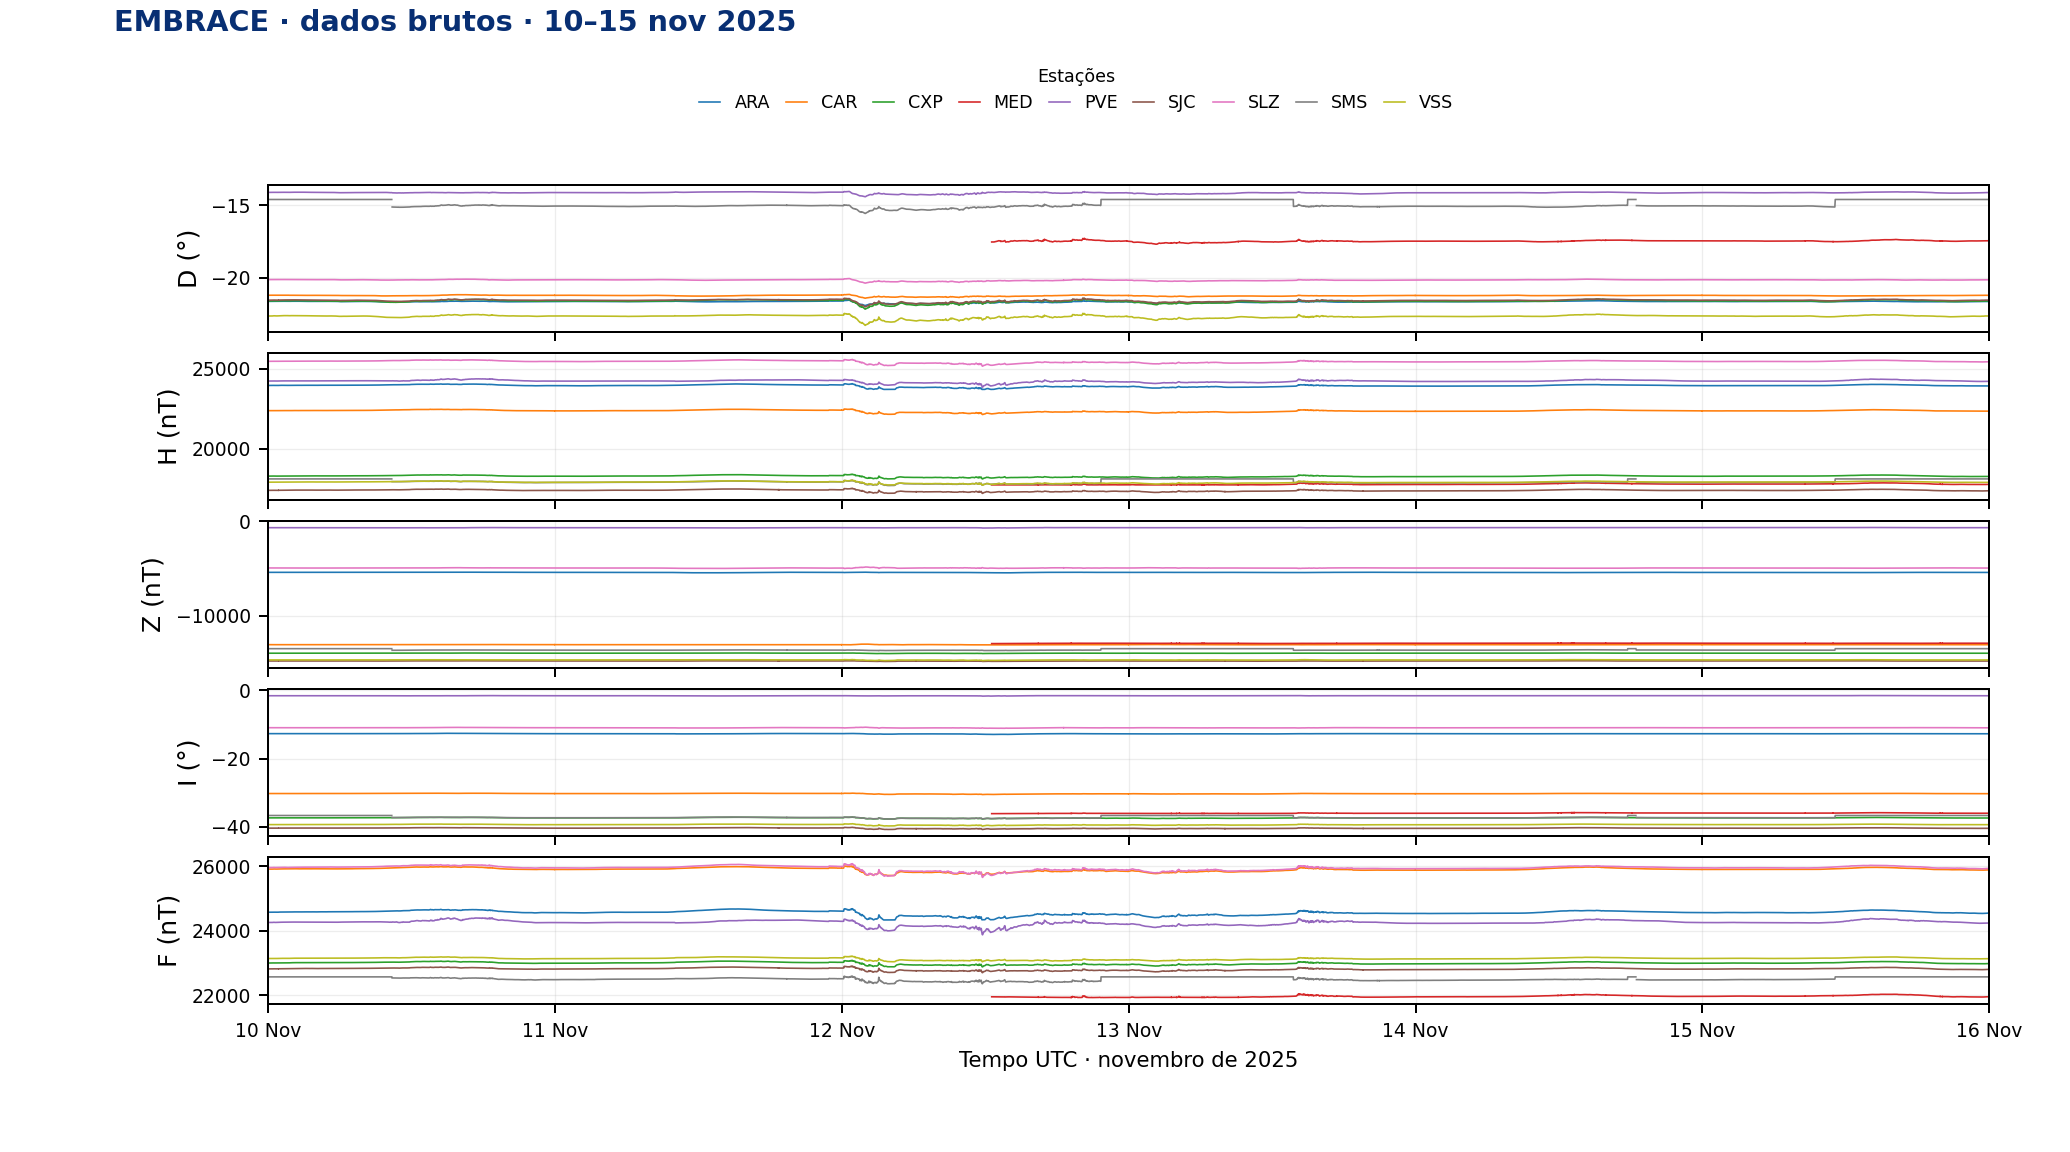

Arquivos por estação (dias disponíveis): ARA 6/6 · CAR 6/6 · CXP 6/6 · MED 4/6 · PVE 6/6 · SJC 6/6 · SLZ 6/6 · SMS 6/6 · VSS 6/6
Figura combinada salva em: $SBGEA_KEYNOTE_DATA/outputs/figures/embrace/raw_magnetometer_2025-11-10_15/EMBRACE_Brazil_raw_all_stations_2025-11-10_to_15.png
Dados originais salvos em: $SBGEA_KEYNOTE_DATA/inputs/embrace/magnetometer/2025-11-10_15
Plot bruto combinado salvo em: $SBGEA_KEYNOTE_DATA/outputs/figures/embrace/raw_magnetometer_2025-11-10_15
Estações sem arquivos no período: ALF, CBA, EUS, JAT, MAN, PAL, STM
MED tem dias ausentes preservados como lacunas; não há interpolação.


In [7]:
from concurrent.futures import ThreadPoolExecutor, as_completed
from html.parser import HTMLParser
from io import StringIO
from pathlib import Path
import re
import time
import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Image as IPyImage

EMBRACE_PORTAL="https://embracedata.inpe.br/magnetometer/"
DST_HAPI_BASE="https://wdc.kugi.kyoto-u.ac.jp/hapi"
DST_DATASET="hour_dst"
EMBRACE_RAW_DIR=KEYNOTE/"inputs"/"embrace"/"magnetometer"/"2025-11-10_15"
EMBRACE_RAW_FIG_DIR=KEYNOTE/"outputs"/"figures"/"embrace"/"raw_magnetometer_2025-11-10_15"
EMBRACE_RAW_DIR.mkdir(parents=True,exist_ok=True)
EMBRACE_RAW_FIG_DIR.mkdir(parents=True,exist_ok=True)
RAW_DAYS=range(10,16)
BRAZIL_STATIONS={
    "ALF":"Alta Floresta", "ARA":"Araguatins", "CAR":"São João do Cariri",
    "CBA":"Cuiabá", "CXP":"Cachoeira Paulista", "EUS":"Eusébio",
    "JAT":"Jataí", "MAN":"Manaus", "MED":"Medianeira", "PAL":"Palmas",
    "PVE":"Porto Velho", "SJC":"São José dos Campos", "SLZ":"São Luís",
    "SMS":"São Martinho da Serra", "STM":"Santarém", "VSS":"Vassouras",
}

class _LinkParser(HTMLParser):
    def __init__(self):
        super().__init__(); self.hrefs=[]
    def handle_starttag(self,tag,attrs):
        if tag.lower()=="a":
            href=dict(attrs).get("href")
            if href: self.hrefs.append(href)

def _get_with_retry(session,url):
    """Retry transient portal timeouts while preserving genuine 404 responses."""
    last_error=None
    for attempt in range(4):
        try:
            response=session.get(url,timeout=(15,60))
            if response.status_code==404:
                return response
            response.raise_for_status()
            return response
        except requests.RequestException as exc:
            last_error=exc
            if attempt<3:
                time.sleep(1.5*(attempt+1))
    raise RuntimeError(f"INPE portal request failed after retries: {url} ({last_error})")

def _get_raw_station_files(station):
    """Reuse LFS originals first; download only station-days missing from the cache."""
    station_dir=EMBRACE_RAW_DIR/station
    cached=sorted(path for path in station_dir.glob(f"{station.lower()}*nov.25m")
                  if path.is_file() and path.stat().st_size)
    cached_days={int(re.search(r"(\d{2})nov",path.name,re.IGNORECASE).group(1))
                 for path in cached}
    missing_days=set(RAW_DAYS)-cached_days
    if not missing_days:
        return station,cached
    year_url=f"{EMBRACE_PORTAL}{station}/2025/"
    with requests.Session() as session:
        response=_get_with_retry(session,year_url)
        if response.status_code==404:
            return station,cached
        parser=_LinkParser(); parser.feed(response.text)
        found=list(cached)
        for day in sorted(missing_days):
            pattern=re.compile(rf"^{station.lower()}{day:02d}nov\.25m$",re.IGNORECASE)
            filename=next((name for name in parser.hrefs if pattern.fullmatch(name)),None)
            if filename is None:
                continue
            data_response=_get_with_retry(session,year_url+filename)
            if data_response.status_code==404:
                continue
            destination=station_dir/filename
            destination.parent.mkdir(parents=True,exist_ok=True)
            destination.write_bytes(data_response.content)
            found.append(destination)
    return station,sorted(found)

station_files={}
with ThreadPoolExecutor(max_workers=3) as pool:
    futures=[pool.submit(_get_raw_station_files,station) for station in BRAZIL_STATIONS]
    for future in as_completed(futures):
        station,files=future.result()
        station_files[station]=sorted(files)

# Preserve a short source note beside the downloaded originals.
(EMBRACE_RAW_DIR/"README.txt").write_text(
    "Raw 1-minute magnetometer reports downloaded from https://embracedata.inpe.br/magnetometer/\n"
    "Period requested: 2025-11-10 through 2025-11-15 UTC.\n"
    "Original portal filenames and file contents are preserved by station.\n"
    "Columns: UTC day, month, year, hour, minute, D (deg), H (nT), Z (nT), I (deg), F (nT).\n",
    encoding="utf-8")

RAW_COLUMNS=["day","month","year","hour","minute","D_deg","H_nT","Z_nT","I_deg","F_nT"]
RAW_FIELDS=[("D_deg","D (°)"),("H_nT","H (nT)"),("Z_nT","Z (nT)"),
            ("I_deg","I (°)"),("F_nT","F (nT)")]
RAW_START=pd.Timestamp("2025-11-10T00:00:00Z")
RAW_STOP=pd.Timestamp("2025-11-16T00:00:00Z")
RAW_MINUTES=pd.date_range(RAW_START,RAW_STOP,freq="min",inclusive="left")

def _read_raw_report(path):
    """Parse numeric report rows only; do not alter the reported measurements."""
    records=[]
    for line in path.read_text(encoding="ascii",errors="replace").splitlines():
        tokens=line.split()
        if len(tokens)!=10:
            continue
        try:
            values=[float(token) for token in tokens]
        except ValueError:
            continue
        records.append(values)
    if not records:
        return pd.DataFrame(columns=RAW_COLUMNS+['time_utc'])
    frame=pd.DataFrame(records,columns=RAW_COLUMNS)
    frame["time_utc"]=pd.to_datetime({
        "year":frame.year.astype(int),"month":frame.month.astype(int),
        "day":frame.day.astype(int),"hour":frame.hour.astype(int),
        "minute":frame.minute.astype(int)},utc=True)
    return frame

raw_station_series={}
for station in BRAZIL_STATIONS:
    files=station_files.get(station,[])
    if not files:
        continue
    parsed_reports=[_read_raw_report(path) for path in files]
    if any(frame.empty for frame in parsed_reports):
        raise ValueError(f"An INPE daily file has no parseable measurements for {station}.")
    data=pd.concat(parsed_reports,ignore_index=True)
    data=data[(data.time_utc>=RAW_START)&(data.time_utc<RAW_STOP)]
    data=data.drop_duplicates("time_utc",keep="first").set_index("time_utc").sort_index()
    # Reindex only to expose missing intervals as blank gaps; measured values stay raw.
    raw_station_series[station]=data.reindex(RAW_MINUTES)

if not raw_station_series:
    raise RuntimeError("No Brazilian station files were available for the requested dates.")

# One figure, one shared UTC timeline: all stations overlaid for each raw field.
colors=plt.get_cmap("tab10").colors
station_color={station:colors[i%len(colors)] for i,station in enumerate(raw_station_series)}
fig,axes=plt.subplots(5,1,figsize=(11.5,6.4),sharex=True,facecolor="white")
for ax,(field,label) in zip(axes,RAW_FIELDS):
    for station,series in raw_station_series.items():
        ax.plot(series.index,series[field],color=station_color[station],lw=.65,
                label=station)
    ax.set_ylabel(label)
    ax.grid(True,alpha=.22,lw=.5)

handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc="upper center",bbox_to_anchor=(.52,.955),
           ncol=min(10,len(labels)),frameon=False,fontsize=7.0,
           columnspacing=.9,handlelength=1.2,title="Estações",title_fontsize=7.0)
axes[-1].xaxis.set_major_locator(mdates.DayLocator(interval=1,tz=RAW_START.tz))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b",tz=RAW_START.tz))
axes[-1].set_xlim(RAW_START,RAW_STOP)
axes[-1].set_xlabel("Tempo UTC · novembro de 2025",fontsize=8.5)
for ax in axes:
    ax.tick_params(axis="both",labelsize=7.5)
fig.suptitle("EMBRACE · dados brutos · 10–15 nov 2025",x=.055,y=.992,
             ha="left",fontweight="bold",color="#082F73",fontsize=11.5)
fig.tight_layout(rect=(.055,.045,.99,.91),h_pad=.2)
RAW_COMBINED_FIG=EMBRACE_RAW_FIG_DIR/"EMBRACE_Brazil_raw_all_stations_2025-11-10_to_15.png"
fig.savefig(RAW_COMBINED_FIG,dpi=180,facecolor="white")
display(IPyImage(filename=str(RAW_COMBINED_FIG)))
plt.close(fig)
# Remove the previous per-station previews; the requested deliverable is the single combined plot.
for old_figure in EMBRACE_RAW_FIG_DIR.glob("EMBRACE_*.png"):
    if old_figure!=RAW_COMBINED_FIG:
        old_figure.unlink()

coverage_text=" · ".join(f"{station} {len(files)}/6" for station,files in sorted(station_files.items()) if files)
print("Arquivos por estação (dias disponíveis):",coverage_text)
print("Figura combinada salva em:",RAW_COMBINED_FIG)
print("Dados originais salvos em:",EMBRACE_RAW_DIR)
print("Plot bruto combinado salvo em:",EMBRACE_RAW_FIG_DIR)
print("Estações sem arquivos no período:",
      ", ".join(st for st in BRAZIL_STATIONS if not station_files.get(st)))
print("MED tem dias ausentes preservados como lacunas; não há interpolação.")

## EMBRACE calibrado · formato SuperMAG · 10–15 de novembro de 2025

Esta versão usa os vetores calibrados `*_final.xdr` e as curvas de linha de base correspondentes em `LFS/EMBRACE_2025`. Os componentes absolutos N e Z incluem o campo principal, por isso não são diretamente comparáveis aos pequenos desvios temporais mostrados no produto final. Para visualizar as perturbações, removo as linhas de base quietas anual e diária fornecidas junto aos dados:

\[\Delta X = X_{\mathrm{final}} - X_{q,\mathrm{year}} - X_{q,\mathrm{day}} - X_{q,\mathrm{offset}}, \quad X \in \{N,E,Z\}.\]

A janela vai de **10 nov 2025 00:00 UT** a **16 nov 2025 00:00 UT (exclusivo)**; linhas tracejadas indicam as meias-noites. A remoção inclui os dois perfis e o offset escalar registrado em `*_baselines.xdr`. Não aplico outra centralização, suavização ou interpolação. Amostras marcadas como inválidas nos arquivos permanecem como lacunas.


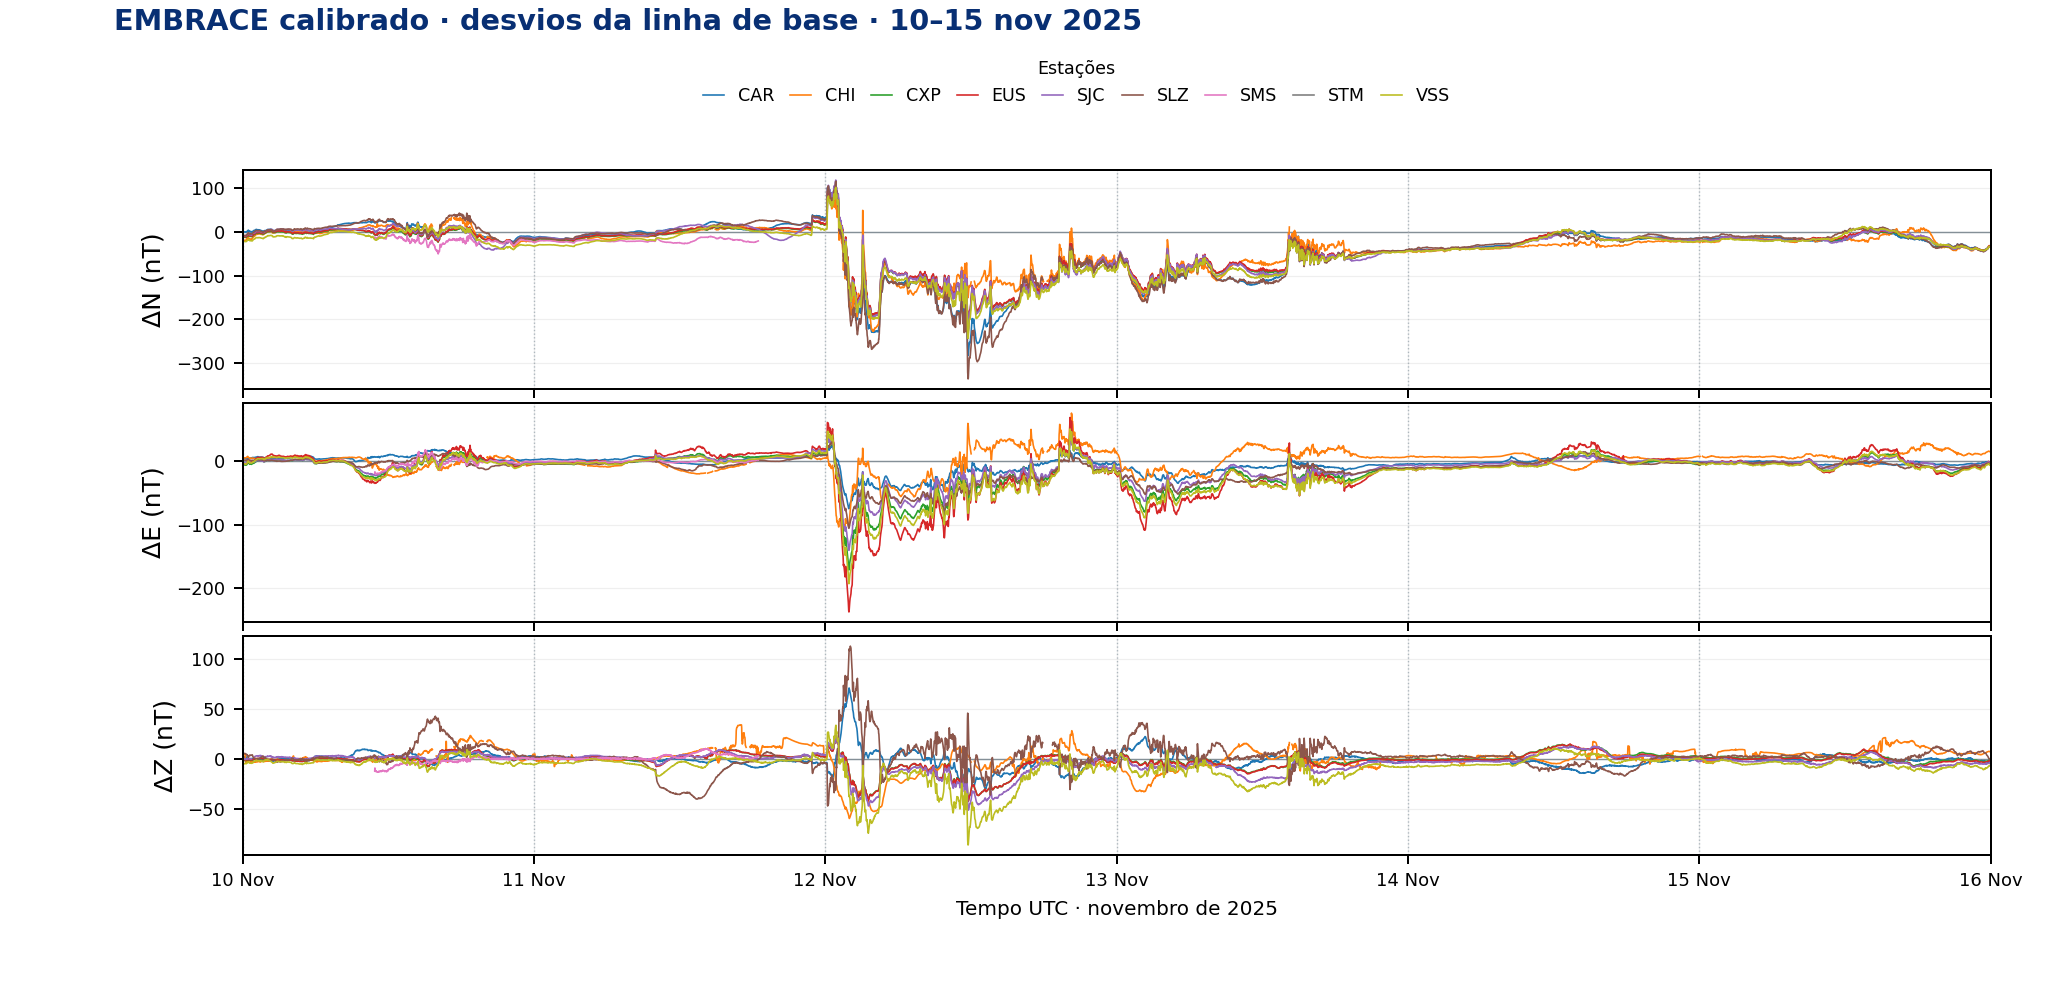

Calibrated SuperMAG-style stations: CAR, CHI, CXP, EUS, SJC, SLZ, SMS, STM, VSS
Baseline correction: X_final - Xqyear - Xqday - Xqoffset for X=N,E,Z
Valid calibrated samples in window: 62119
UTC window: 2025-11-10 00:00:00+00:00 to 2025-11-16 00:00:00+00:00 (exclusive)
Saved calibrated comparison figure: $SBGEA_KEYNOTE_DATA/outputs/figures/embrace/supermag_style_2025-11-10_15/EMBRACE_SuperMAG_style_N_E_Z_all_stations_2025-11-10_to_15.png


In [8]:
# Baseline-corrected calibrated components from the cartman SuperMAG-style archive.
STYLE_START=pd.Timestamp("2025-11-10T00:00:00Z")
STYLE_STOP=pd.Timestamp("2025-11-16T00:00:00Z")
STYLE_FIG_DIR=KEYNOTE/"outputs"/"figures"/"embrace"/"supermag_style_2025-11-10_15"
STYLE_FIG_DIR.mkdir(parents=True,exist_ok=True)

STYLE_YEAR_START=pd.Timestamp("2025-01-01T00:00:00Z")
STYLE_EXPECTED=365*24*60
STYLE_I0=int((STYLE_START-STYLE_YEAR_START)/pd.Timedelta(minutes=1))
STYLE_I1=int((STYLE_STOP-STYLE_YEAR_START)/pd.Timedelta(minutes=1))
style_time=pd.date_range(STYLE_START,STYLE_STOP,freq="min",inclusive="left")
style_frames=[]
style_files=sorted(EMBRACE_DIR.glob("2025_*_final.xdr"))
if not style_files:
    raise FileNotFoundError(f"No calibrated final XDR files found in {EMBRACE_DIR}")

for final_path in style_files:
    station=final_path.stem.split("_")[1].upper()
    baseline_path=EMBRACE_DIR/f"2025_{station}_baselines.xdr"
    if not baseline_path.exists():
        print(f"Skipping {station}: no matching yearly/daily baseline file")
        continue
    final_xdr=readsav(str(final_path),python_dict=True)
    baseline_xdr=readsav(str(baseline_path),python_dict=True)
    station_data={"time_utc":style_time,"station":station}
    for component in ("n","e","z"):
        values=np.asarray(final_xdr[component],dtype=float).reshape(-1)
        quiet_year=np.asarray(baseline_xdr[f"{component}qyear"],dtype=float).reshape(-1)
        quiet_day=np.asarray(baseline_xdr[f"{component}qday"],dtype=float).reshape(-1)
        quiet_offset=float(np.asarray(baseline_xdr[f"{component}qoffset"],dtype=float).item())
        if any(len(array)!=STYLE_EXPECTED for array in (values,quiet_year,quiet_day)):
            raise ValueError(f"Unexpected annual array length in {station} {component.upper()} data/baselines")
        if not np.isfinite(quiet_offset) or abs(quiet_offset)>=100000:
            raise ValueError(f"Invalid baseline offset in {station} {component.upper()}")
        values=values[STYLE_I0:STYLE_I1]
        quiet_year=quiet_year[STYLE_I0:STYLE_I1]
        quiet_day=quiet_day[STYLE_I0:STYLE_I1]
        valid=(np.isfinite(values)&np.isfinite(quiet_year)&np.isfinite(quiet_day)
               &(np.abs(values)<100000)&(np.abs(quiet_year)<100000)&(np.abs(quiet_day)<100000))
        anomaly=np.full(len(style_time),np.nan,dtype=float)
        anomaly[valid]=values[valid]-quiet_year[valid]-quiet_day[valid]-quiet_offset
        station_data[f"{component}_anomaly_nT"]=anomaly
    style_frames.append(pd.DataFrame(station_data))

if not style_frames:
    raise RuntimeError("No calibrated station records with matching baseline curves were found.")
style_window=pd.concat(style_frames,ignore_index=True)
style_stations=sorted(style_window.station.unique())
style_colors=plt.get_cmap("tab10").colors
style_station_color={station:style_colors[i%len(style_colors)]
                     for i,station in enumerate(style_stations)}
style_fields=[("n_anomaly_nT","ΔN (nT)"),("e_anomaly_nT","ΔE (nT)"),
              ("z_anomaly_nT","ΔZ (nT)")]

fig,axes=plt.subplots(3,1,figsize=(11.5,5.5),sharex=True,facecolor="white")
for ax,(field,label) in zip(axes,style_fields):
    for station,series in style_window.groupby("station",sort=True):
        ax.plot(series.time_utc,series[field],color=style_station_color[station],
                lw=.65,label=station)
    ax.axhline(0,color="#7A8792",lw=.55,zorder=0)
    ax.set_ylabel(label)
    ax.grid(True,alpha=.2,lw=.5)
    for midnight in pd.date_range(STYLE_START,STYLE_STOP,freq="D",inclusive="left"):
        ax.axvline(midnight,color="#9AA8B3",lw=.55,ls=":",alpha=.8,zorder=0)

handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc="upper center",bbox_to_anchor=(.52,.955),
           ncol=min(10,len(labels)),frameon=False,fontsize=7.0,
           columnspacing=.9,handlelength=1.2,title="Estações",title_fontsize=7.0)
axes[-1].xaxis.set_major_locator(mdates.DayLocator(interval=1,tz=STYLE_START.tz))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b",tz=STYLE_START.tz))
axes[-1].set_xlim(STYLE_START,STYLE_STOP)
axes[-1].set_xlabel("Tempo UTC · novembro de 2025",fontsize=8.0)
for ax in axes:
    ax.tick_params(axis="both",labelsize=7.2)
fig.suptitle("EMBRACE calibrado · desvios da linha de base · 10–15 nov 2025",
             x=.055,y=.992,ha="left",fontweight="bold",color="#082F73",fontsize=11.5)
fig.tight_layout(rect=(.055,.045,.99,.91),h_pad=.22)
STYLE_FIG=STYLE_FIG_DIR/"EMBRACE_SuperMAG_style_N_E_Z_all_stations_2025-11-10_to_15.png"
fig.savefig(STYLE_FIG,dpi=180,facecolor="white")
display(IPyImage(filename=str(STYLE_FIG)))
plt.close(fig)
print("Calibrated SuperMAG-style stations:",", ".join(style_stations))
print("Baseline correction: X_final - Xqyear - Xqday - Xqoffset for X=N,E,Z")
print("Valid calibrated samples in window:",int(style_window[[f"{c}_anomaly_nT" for c in ("n","e","z")]].notna().all(axis=1).sum()))
print("UTC window:",STYLE_START,"to",STYLE_STOP,"(exclusive)")
print("Saved calibrated comparison figure:",STYLE_FIG)


## Progressão da tempestade · vetores horizontais e componente vertical

A animação mostra a evolução de **11 nov 00:00 UT a 13 nov 00:00 UT** na mesma extensão geográfica do painel regional anterior. Cada seta representa a perturbação horizontal calibrada `ΔBₕ = (ΔE, ΔN)` após remover as curvas de base quietas anual e diária e os offsets escalares registrados nos arquivos. A cor representa `ΔZ` vertical **para cima**: os arquivos usam Z positivo para baixo, portanto o sinal é invertido para esta visualização. Azul indica componente para baixo e vermelho para cima. As setas são ampliadas para legibilidade; a escala gráfica é indicada no mapa. Quadros usam amostras medidas de 1 minuto; a 144 quadros por segundo, o vídeo tem 20 segundos, sem interpolação temporal.


In [9]:
from matplotlib.animation import FuncAnimation, FFMpegWriter
from matplotlib.colors import TwoSlopeNorm
from IPython.display import Video
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Sample the measured 1-minute calibrated residuals without temporal interpolation.
ANIM_START=pd.Timestamp("2025-11-11T00:00:00Z")
ANIM_STOP=pd.Timestamp("2025-11-13T00:00:00Z")
ANIM_TIMES=pd.date_range(ANIM_START,ANIM_STOP,freq="1min",inclusive="left")
ANIM_FPS=144
ANIM_DURATION_SECONDS=len(ANIM_TIMES)/ANIM_FPS
if len(ANIM_TIMES)!=2880 or ANIM_DURATION_SECONDS!=20.0:
    raise RuntimeError(f"Expected exactly 2,880 frames / 20 s; got {len(ANIM_TIMES)} / {ANIM_DURATION_SECONDS:.2f} s")
ANIM_STATIONS=sorted(set(style_stations)&set(STATION_CATALOG.station))
if len(ANIM_STATIONS)<2:
    raise RuntimeError("At least two calibrated stations with map coordinates are needed for the quiver animation.")

# Pivot to consistent station ordering and exact one-minute observations.
def _animation_matrix(column):
    wide=style_window.pivot(index="time_utc",columns="station",values=column)
    return wide.reindex(index=ANIM_TIMES,columns=ANIM_STATIONS).to_numpy(dtype=float)

ANIM_E=_animation_matrix("e_anomaly_nT")
ANIM_N=_animation_matrix("n_anomaly_nT")
# The XDR convention is positive-down; use upward-positive vertical component.
# style_window already has yearly, daily, and scalar offsets removed.
ANIM_Z_UP=-_animation_matrix("z_anomaly_nT")
station_geo=(STATION_CATALOG.set_index("station").loc[ANIM_STATIONS].reset_index())
ANIM_LON=station_geo.longitude.to_numpy(dtype=float)
ANIM_LAT=station_geo.latitude.to_numpy(dtype=float)

# Map-arrow geometry is intentionally enlarged: 100 nT is drawn as 1 degree.
# This affects arrow length only; vector values and colors retain nT units.
ARROW_NT_PER_DEGREE=60.0
U_DEG=ANIM_E/ARROW_NT_PER_DEGREE
V_DEG=ANIM_N/ARROW_NT_PER_DEGREE
finite_z=np.abs(ANIM_Z_UP[np.isfinite(ANIM_Z_UP)])
if finite_z.size==0:
    raise RuntimeError("No valid upward-positive ΔZ samples are available for the animation.")
Z_LIMIT=float(np.ceil(np.nanmax(finite_z)/10.0)*10.0)
Z_NORM=TwoSlopeNorm(vmin=-Z_LIMIT,vcenter=0.0,vmax=Z_LIMIT)

NAVY="#082F73"; PALE_LAND="#F2F5F4"; PALE_WATER="#EAF3FA"
PLATE=ccrs.PlateCarree()
ANIM_FIG_DIR=KEYNOTE/"outputs"/"figures"/"embrace"/"supermag_style_2025-11-10_15"
ANIM_FIG_DIR.mkdir(parents=True,exist_ok=True)
ANIM_MP4=ANIM_FIG_DIR/"EMBRACE_calibrated_storm_quiver_2025-11-11_to_13.mp4"

fig=plt.figure(figsize=(7.8,7.2),dpi=160,facecolor="white")
ax=fig.add_subplot(1,1,1,projection=PLATE)
ax.set_extent([-80,-30,-60,10],crs=PLATE)
ax.set_facecolor(PALE_WATER)
ax.add_feature(cfeature.OCEAN.with_scale("110m"),facecolor=PALE_WATER,zorder=0)
ax.add_feature(cfeature.LAND.with_scale("110m"),facecolor=PALE_LAND,edgecolor="none",zorder=1)
ax.add_feature(cfeature.COASTLINE.with_scale("110m"),edgecolor="#8293A1",linewidth=.6,zorder=2)
ax.add_feature(cfeature.BORDERS.with_scale("110m"),edgecolor="#A8B4BD",linewidth=.4,zorder=2)
grid=ax.gridlines(crs=PLATE,draw_labels=True,linewidth=.45,color="#91A4B5",alpha=.45,
                  linestyle=(0,(2,3)),zorder=1.5)
grid.top_labels=False; grid.right_labels=False
grid.xlabel_style={"size":8,"color":"#586A79"}; grid.ylabel_style={"size":8,"color":"#586A79"}
ax.scatter(ANIM_LON,ANIM_LAT,transform=PLATE,s=23,color=NAVY,
           edgecolors="white",linewidths=.6,zorder=5)
label_offsets={"CAR":(5,-8),"CHI":(-15,-4),"CXP":(-4,10),"EUS":(5,6),
               "SJC":(-18,-9),"SLZ":(3,8),"SMS":(6,-9),"STM":(-16,6),"VSS":(14,1)}
for row in station_geo.itertuples():
    dx,dy=label_offsets.get(row.station,(4,4))
    ax.annotate(row.station,(row.longitude,row.latitude),
        xycoords=PLATE._as_mpl_transform(ax),xytext=(dx,dy),textcoords="offset points",
        fontsize=7.5,fontweight="bold",color=NAVY,zorder=8)

q0=np.ma.masked_invalid(ANIM_Z_UP[0])
quiver=ax.quiver(ANIM_LON,ANIM_LAT,
    np.ma.masked_invalid(U_DEG[0]),np.ma.masked_invalid(V_DEG[0]),q0,
    transform=PLATE,cmap="coolwarm",norm=Z_NORM,
    angles="xy",scale_units="xy",scale=1.0,pivot="tail",
    width=.006,headwidth=4.2,headlength=4.8,headaxislength=4.0,
    zorder=7)
# Repaint station markers above the vectors so arrow origins remain easy to locate.
ax.scatter(ANIM_LON,ANIM_LAT,transform=PLATE,s=23,color=NAVY,
           edgecolors="white",linewidths=.6,zorder=9)
colorbar=fig.colorbar(quiver,ax=ax,fraction=.05,pad=.04,shrink=.82,
                      extend="both",label="ΔZ para cima (nT)")
colorbar.ax.tick_params(labelsize=7.5)
ax.quiverkey(quiver,.77,.94,100.0/ARROW_NT_PER_DEGREE,"100 nT",labelpos="E",coordinates="axes",
             fontproperties={"size":7.5},color="#253746",labelcolor="#253746")
time_label=ax.text(.025,.965,"",transform=ax.transAxes,ha="left",va="top",
    fontsize=10,fontweight="bold",color=NAVY,
    bbox={"boxstyle":"round,pad=.3","facecolor":"white","edgecolor":"#D5DEE5","alpha":.96},zorder=10)
fig.suptitle("EMBRACE · progressão da tempestade · ΔBₕ e ΔZ para cima",
             x=.055,y=.985,ha="left",fontsize=12,fontweight="bold",color=NAVY)
fig.text(.055,.025,
    f"Setas: (ΔE, ΔN); escala gráfica ampliada (100 nT = {100.0/ARROW_NT_PER_DEGREE:.1f}°). Cores: ΔZ para cima; azul = para baixo, vermelho = para cima.",
    ha="left",fontsize=7.3,color="#526575")
fig.tight_layout(rect=(.025,.055,.97,.93),pad=.6)

def _update_quiver(frame_index):
    quiver.set_UVC(np.ma.masked_invalid(U_DEG[frame_index]),
                   np.ma.masked_invalid(V_DEG[frame_index]),
                   np.ma.masked_invalid(ANIM_Z_UP[frame_index]))
    time_label.set_text(ANIM_TIMES[frame_index].strftime("%d %b %Y · %H:%M UT"))
    return quiver,time_label

storm_animation=FuncAnimation(fig,_update_quiver,frames=len(ANIM_TIMES),
                               interval=1000/ANIM_FPS,blit=False,repeat=True)
writer=FFMpegWriter(fps=ANIM_FPS,bitrate=900,metadata={"title":"EMBRACE calibrated storm progression"})
storm_animation.save(ANIM_MP4,writer=writer,dpi=120)
plt.close(fig)
# display(Video(filename=str(ANIM_MP4),embed=True,width=900))
print("Animated stations:",", ".join(ANIM_STATIONS))
print(f"Frames: {len(ANIM_TIMES)} at 1-minute sampling | duration: {ANIM_DURATION_SECONDS:.1f} s | color range: ±{Z_LIMIT:.0f} nT upward-positive ΔZ")
print("Saved storm progression:",ANIM_MP4)


Animated stations: CAR, CHI, CXP, EUS, SJC, SLZ, SMS, STM, VSS
Frames: 2880 at 1-minute sampling | duration: 20.0 s | color range: ±120 nT upward-positive ΔZ
Saved storm progression: $SBGEA_KEYNOTE_DATA/outputs/figures/embrace/supermag_style_2025-11-10_15/EMBRACE_calibrated_storm_quiver_2025-11-11_to_13.mp4


## Quadro da tempestade · 12 de novembro de 2025 · 14:00 UT

Este quadro estático usa a amostra medida de **12 nov 2025, 14:00 UT** e mantém a mesma projeção, extensão, escala das setas e normalização de cores do vídeo. As setas mostram `(ΔE, ΔN)` após a remoção das linhas de base quietas; a cor representa `ΔZ` positivo para cima.


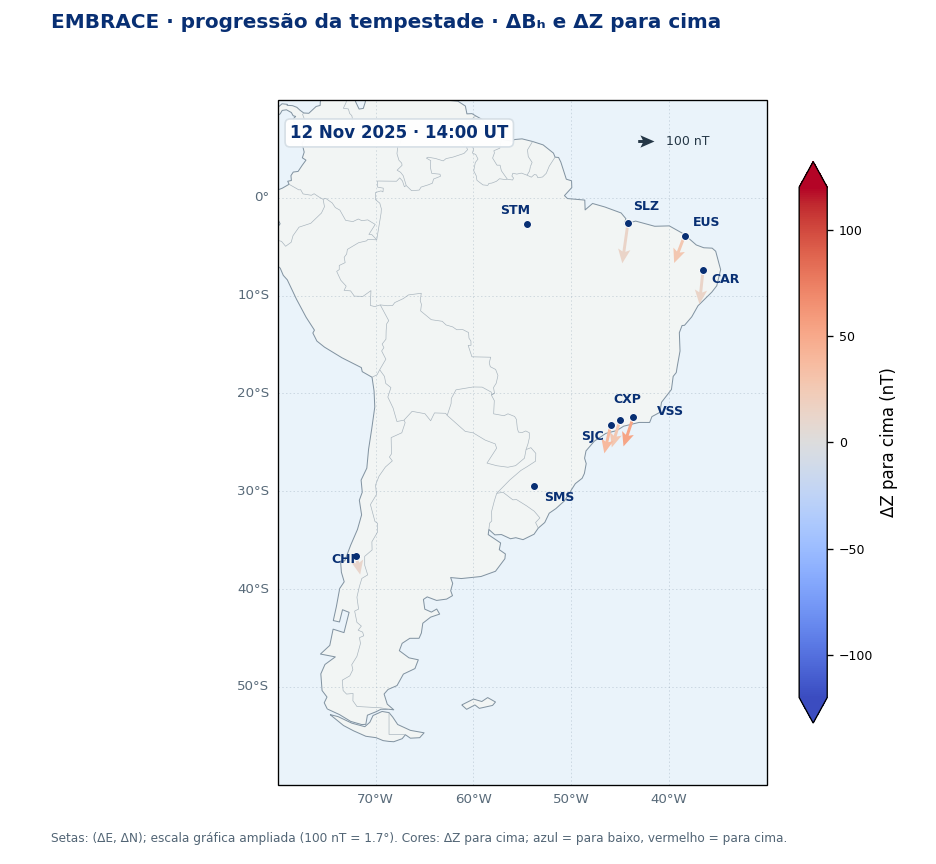

Frame: 2025-11-12 14:00:00+00:00 | animation sample: 2280 | output: $SBGEA_KEYNOTE_DATA/outputs/figures/embrace/supermag_style_2025-11-10_15/EMBRACE_calibrated_storm_quiver_2025-11-12_1400UT.png


In [10]:
# Render the exact one-minute sample at 12 Nov 2025, 14:00 UT using the video styling.
FRAME_TIME=pd.Timestamp("2025-11-12T14:00:00Z")
FRAME_MATCH=np.flatnonzero(ANIM_TIMES==FRAME_TIME)
if len(FRAME_MATCH)!=1:
    raise ValueError(f"Requested frame {FRAME_TIME} is not present in the animation's 1-minute samples.")
FRAME_INDEX=int(FRAME_MATCH[0])

NAVY="#082F73"; PALE_LAND="#F2F5F4"; PALE_WATER="#EAF3FA"
PLATE=ccrs.PlateCarree()
fig=plt.figure(figsize=(7.8,7.2),dpi=160,facecolor="white")
ax=fig.add_subplot(1,1,1,projection=PLATE)
ax.set_extent([-80,-30,-60,10],crs=PLATE)
ax.set_facecolor(PALE_WATER)
ax.add_feature(cfeature.OCEAN.with_scale("110m"),facecolor=PALE_WATER,zorder=0)
ax.add_feature(cfeature.LAND.with_scale("110m"),facecolor=PALE_LAND,edgecolor="none",zorder=1)
ax.add_feature(cfeature.COASTLINE.with_scale("110m"),edgecolor="#8293A1",linewidth=.6,zorder=2)
ax.add_feature(cfeature.BORDERS.with_scale("110m"),edgecolor="#A8B4BD",linewidth=.4,zorder=2)
grid=ax.gridlines(crs=PLATE,draw_labels=True,linewidth=.45,color="#91A4B5",alpha=.45,
                  linestyle=(0,(2,3)),zorder=1.5)
grid.top_labels=False; grid.right_labels=False
grid.xlabel_style={"size":8,"color":"#586A79"}; grid.ylabel_style={"size":8,"color":"#586A79"}
label_offsets={"CAR":(5,-8),"CHI":(-15,-4),"CXP":(-4,10),"EUS":(5,6),
               "SJC":(-18,-9),"SLZ":(3,8),"SMS":(6,-9),"STM":(-16,6),"VSS":(14,1)}

qframe=ax.quiver(ANIM_LON,ANIM_LAT,
    np.ma.masked_invalid(U_DEG[FRAME_INDEX]),np.ma.masked_invalid(V_DEG[FRAME_INDEX]),
    np.ma.masked_invalid(ANIM_Z_UP[FRAME_INDEX]),
    transform=PLATE,cmap="coolwarm",norm=Z_NORM,
    angles="xy",scale_units="xy",scale=1.0,pivot="tail",
    width=.006,headwidth=4.2,headlength=4.8,headaxislength=4.0,zorder=7)
ax.scatter(ANIM_LON,ANIM_LAT,transform=PLATE,s=23,color=NAVY,
           edgecolors="white",linewidths=.6,zorder=9)
for row in station_geo.itertuples():
    dx,dy=label_offsets.get(row.station,(4,4))
    ax.annotate(row.station,(row.longitude,row.latitude),
        xycoords=PLATE._as_mpl_transform(ax),xytext=(dx,dy),textcoords="offset points",
        fontsize=7.5,fontweight="bold",color=NAVY,zorder=10)
colorbar=fig.colorbar(qframe,ax=ax,fraction=.05,pad=.04,shrink=.82,
                      extend="both",label="ΔZ para cima (nT)")
colorbar.ax.tick_params(labelsize=7.5)
ax.quiverkey(qframe,.77,.94,100.0/ARROW_NT_PER_DEGREE,"100 nT",labelpos="E",coordinates="axes",
             fontproperties={"size":7.5},color="#253746",labelcolor="#253746")
ax.text(.025,.965,FRAME_TIME.strftime("%d %b %Y · %H:%M UT"),transform=ax.transAxes,
    ha="left",va="top",fontsize=10,fontweight="bold",color=NAVY,
    bbox={"boxstyle":"round,pad=.3","facecolor":"white","edgecolor":"#D5DEE5","alpha":.96},zorder=11)
fig.suptitle("EMBRACE · progressão da tempestade · ΔBₕ e ΔZ para cima",
             x=.055,y=.985,ha="left",fontsize=12,fontweight="bold",color=NAVY)
fig.text(.055,.025,
    f"Setas: (ΔE, ΔN); escala gráfica ampliada (100 nT = {100.0/ARROW_NT_PER_DEGREE:.1f}°). Cores: ΔZ para cima; azul = para baixo, vermelho = para cima.",
    ha="left",fontsize=7.3,color="#526575")
fig.tight_layout(rect=(.025,.055,.97,.93),pad=.6)
FRAME_PNG=ANIM_FIG_DIR/"EMBRACE_calibrated_storm_quiver_2025-11-12_1400UT.png"
fig.savefig(FRAME_PNG,dpi=120,facecolor="white")
display(IPyImage(filename=str(FRAME_PNG)))
plt.close(fig)
print("Frame:",FRAME_TIME,"| animation sample:",FRAME_INDEX,"| output:",FRAME_PNG)


## Visão global da tempestade · 12 de novembro de 2025 · 14:00 UT

Este mapa amplia a mesma amostra de um minuto para a cobertura mundial. Os vetores globais vêm do serviço oficial SuperMAG com `baseline=all` e `delta=none`; vetores EMBRACE calibrados completam apenas as estações locais sem vetor válido no produto global. Se um código aparece nas duas fontes, mantém-se o vetor SuperMAG para evitar duplicação. Todas as setas usam a escala do quadro regional (`100 nT = 1,7°`) e as cores usam a mesma normalização de `ΔZ` do vídeo. A base global é armazenada em `KEYNOTE/inputs/supermag/global/2025/` e reutilizada em execuções seguintes.

**Fontes e processamento:** SuperMAG (`dbn_geo`, `dbe_geo`, `dbz_geo`; baseline global `all`, delta `none`) e EMBRACE (`X_final − Xqyear − Xqday − Xqoffset`). O `Z` SuperMAG é convertido para positivo para cima. A escala visual dos vetores é ampliada; os valores continuam em nT. Fonte SuperMAG: Gjerloev (2012), doi:10.1029/2012JA017683.


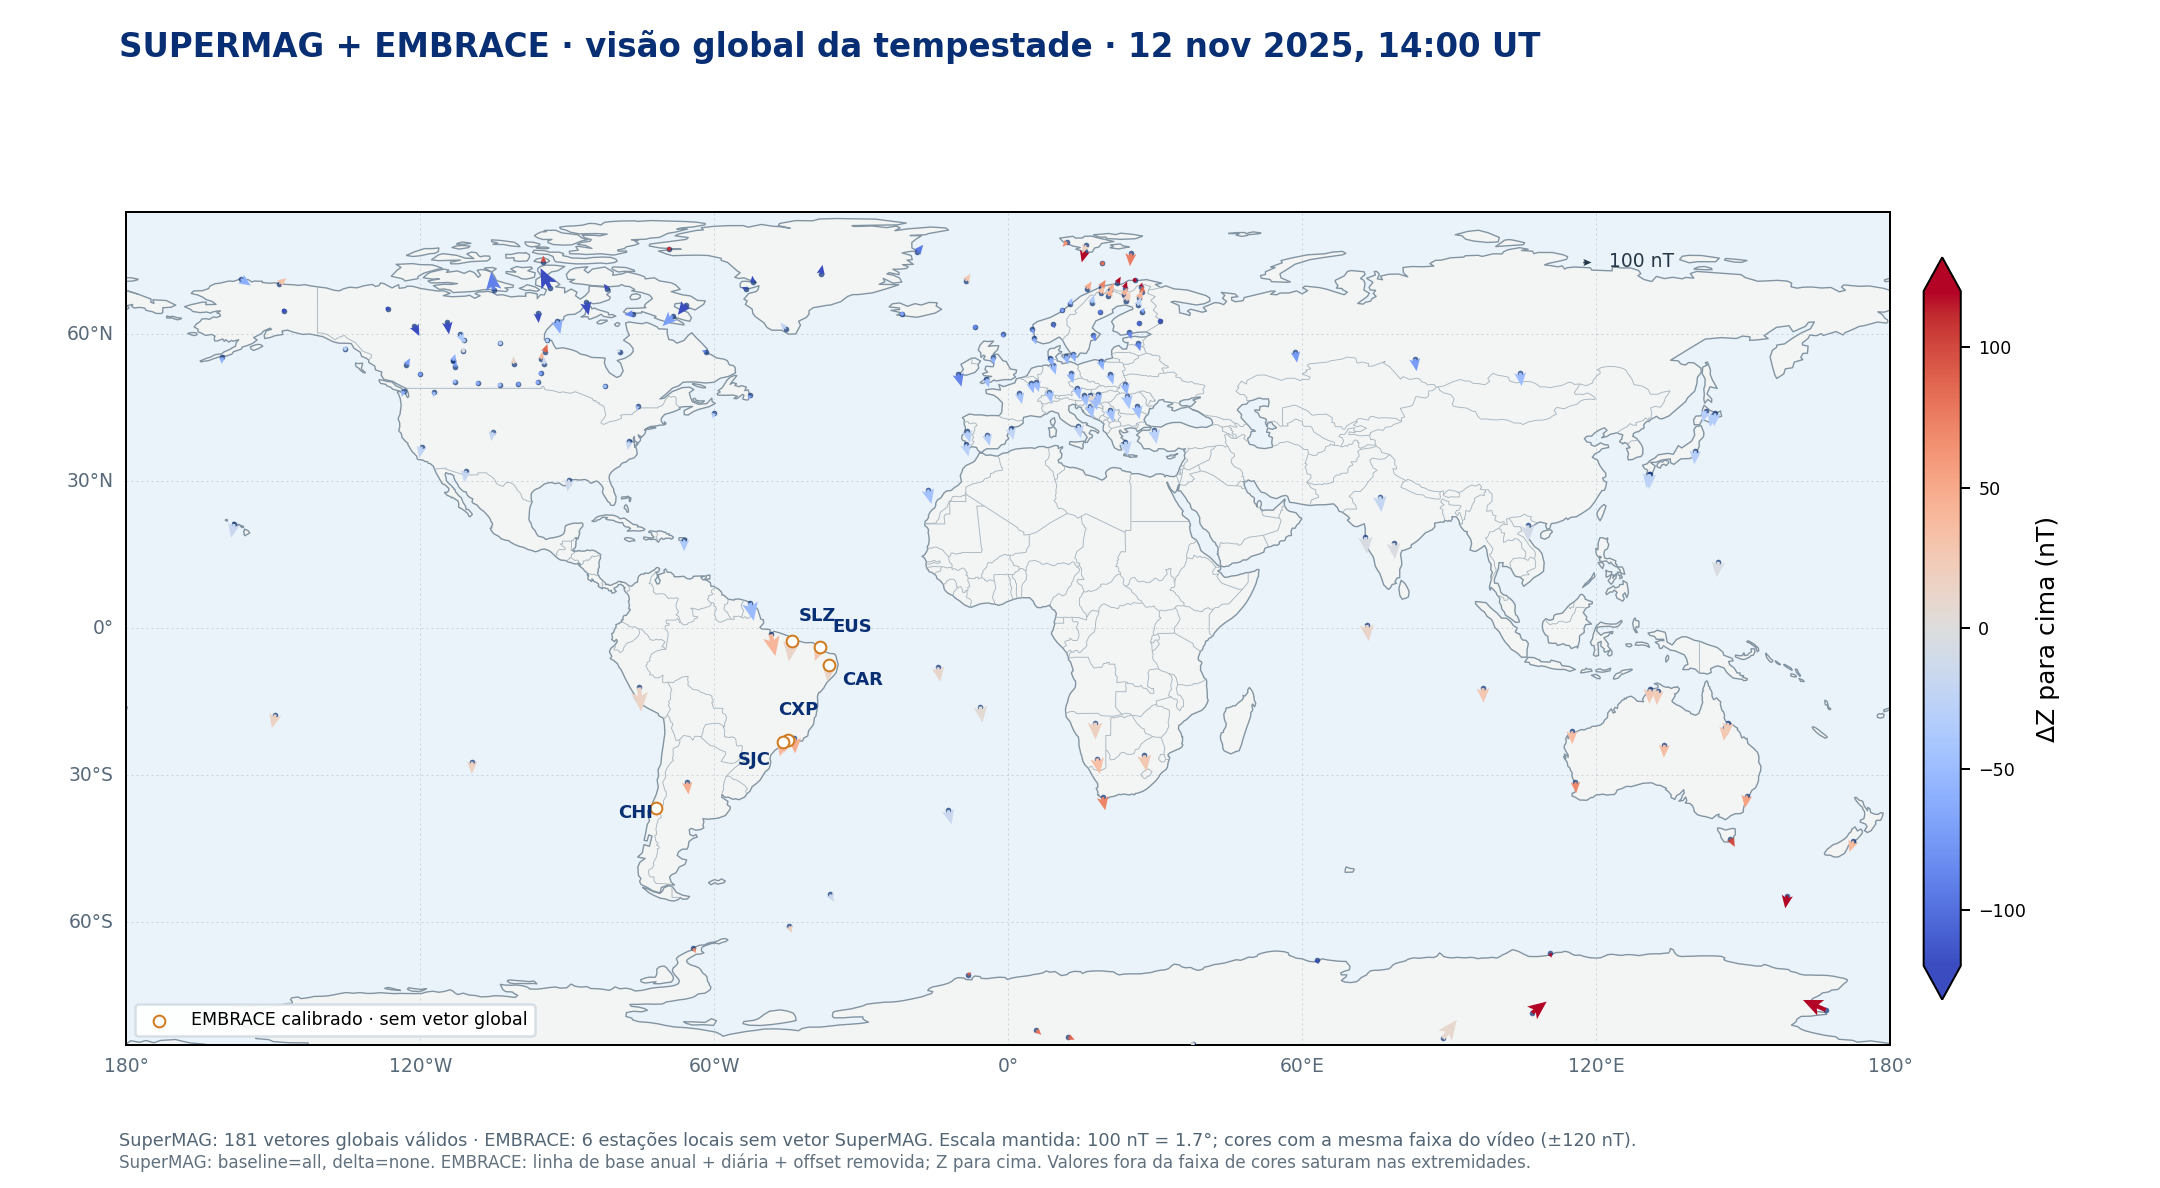

SuperMAG global vectors: 181 | EMBRACE-only vectors: 6
Duplicate station codes: 0
Shared vector scale: 100 nT = 1.67 degrees | shared ΔZ range: ± 120.0 nT
Cached SuperMAG sample: $SBGEA_KEYNOTE_DATA/inputs/supermag/global/2025/20251112_1400_supermag_mag_baseline_all.csv
Saved global view: $SBGEA_KEYNOTE_DATA/outputs/figures/embrace/supermag_style_2025-11-10_15/EMBRACE_SuperMAG_global_storm_quiver_2025-11-12_1400UT.png


In [12]:
# Global one-minute SuperMAG sample, cached in LFS; EMBRACE fills only missing local stations.
from io import StringIO
import json
import time as _time
import requests
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature

label_offsets={"CAR":(5,-8),"CHI":(-15,-4),"CXP":(-4,10),"EUS":(5,6),
               "SJC":(-18,-9),"SLZ":(3,8),"SMS":(6,-9),"STM":(-16,6),"VSS":(14,1)}
GLOBAL_STORM_TIME=pd.Timestamp("2025-11-12T14:00:00Z")
GLOBAL_INPUT_DIR=KEYNOTE/"inputs"/"supermag"/"global"/"2025"
GLOBAL_INPUT_DIR.mkdir(parents=True,exist_ok=True)
GLOBAL_API="https://supermag.jhuapl.edu/lib/services/"
GLOBAL_INVENTORY=GLOBAL_INPUT_DIR/"supermag_station_inventory.json"
GLOBAL_SAMPLE_CSV=GLOBAL_INPUT_DIR/"20251112_1400_supermag_mag_baseline_all.csv"

if GLOBAL_INVENTORY.exists():
    global_inventory=json.loads(GLOBAL_INVENTORY.read_text())
else:
    response=requests.get(GLOBAL_API,params={"service":"stations","fmt":"json"},timeout=(15,60))
    response.raise_for_status()
    global_inventory=response.json()
    GLOBAL_INVENTORY.write_text(json.dumps(global_inventory,indent=2,ensure_ascii=False)+"\n")

global_station_ids=sorted({row["id"] for row in global_inventory if row.get("id")})
if GLOBAL_SAMPLE_CSV.exists():
    global_csv_text=GLOBAL_SAMPLE_CSV.read_text()
else:
    global_params={
        "service":"mag","downloadtype":"website_request",
        "start":GLOBAL_STORM_TIME.strftime("%Y-%m-%dT%H:%M"),
        "end":GLOBAL_STORM_TIME.strftime("%Y-%m-%dT%H:%M"),
        "stations":",".join(global_station_ids),"fidelity":"60s",
        "baseline":"all","delta":"none","fmt":"csv",
    }
    global_response=None
    last_global_error=None
    with requests.Session() as session:
        for attempt in range(4):
            try:
                global_response=session.get(GLOBAL_API,params=global_params,timeout=(20,240))
                global_response.raise_for_status()
                if global_response.text.startswith("Date_UTC,"):
                    break
                last_global_error=global_response.text[:300]
            except requests.RequestException as exc:
                last_global_error=repr(exc)
            if attempt<3: _time.sleep(1.5*(attempt+1))
        else:
            raise RuntimeError(f"SuperMAG global vector request failed: {last_global_error}")
    global_csv_text=global_response.text
    GLOBAL_SAMPLE_CSV.write_text(global_csv_text)

global_vectors=pd.read_csv(StringIO(global_csv_text))
global_vectors["IAGA"]=global_vectors["IAGA"].astype(str).str.strip().str.upper()
for column in ("GEOLON","GEOLAT","dbn_geo","dbe_geo","dbz_geo"):
    global_vectors[column]=pd.to_numeric(global_vectors[column],errors="coerce")
global_vectors[["dbn_geo","dbe_geo","dbz_geo"]]=global_vectors[["dbn_geo","dbe_geo","dbz_geo"]].replace([999999,-999999,1e31,-1e31],np.nan)
global_vectors=global_vectors.dropna(subset=["GEOLON","GEOLAT","dbn_geo","dbe_geo","dbz_geo"])
global_vectors=global_vectors[(global_vectors["GEOLAT"].between(-90,90))
                              &(global_vectors[["dbn_geo","dbe_geo","dbz_geo"]].abs().max(axis=1)<2000)]
global_vectors=global_vectors.drop_duplicates("IAGA",keep="first").copy()
global_vectors["longitude"]=((global_vectors["GEOLON"]+180)%360)-180
global_vectors["latitude"]=global_vectors["GEOLAT"]
global_vectors["station"]=global_vectors["IAGA"]
global_vectors["delta_e_nT"]=global_vectors["dbe_geo"]
global_vectors["delta_n_nT"]=global_vectors["dbn_geo"]
# SuperMAG's geographic Z is positive down; this figure uses positive up.
global_vectors["delta_z_up_nT"]=-global_vectors["dbz_geo"]
global_vectors["source"]="SuperMAG"

local_at_time=style_window.loc[style_window.time_utc.eq(GLOBAL_STORM_TIME)].merge(
    STATION_CATALOG,on="station",how="inner")
global_codes=set(global_vectors.station)
local_missing=local_at_time.loc[~local_at_time.station.isin(global_codes)].copy()
local_missing=local_missing.dropna(subset=["e_anomaly_nT","n_anomaly_nT","z_anomaly_nT"])
local_vectors=pd.DataFrame({
    "station":local_missing.station,
    "longitude":local_missing.longitude,
    "latitude":local_missing.latitude,
    "delta_e_nT":local_missing.e_anomaly_nT,
    "delta_n_nT":local_missing.n_anomaly_nT,
    "delta_z_up_nT":-local_missing.z_anomaly_nT,
    "source":"EMBRACE calibrado",
})
GLOBAL_PLOT_VECTORS=pd.concat([
    global_vectors[["station","longitude","latitude","delta_e_nT","delta_n_nT","delta_z_up_nT","source"]],
    local_vectors,
],ignore_index=True)
if GLOBAL_PLOT_VECTORS.station.duplicated().any():
    raise RuntimeError("Duplicate station codes remain in the global vector map.")

# Keep the exact regional video scale: 60 nT per plotted degree and shared ΔZ norm.
GLOBAL_PLOT_VECTORS["u_deg"]=GLOBAL_PLOT_VECTORS.delta_e_nT/ARROW_NT_PER_DEGREE
GLOBAL_PLOT_VECTORS["v_deg"]=GLOBAL_PLOT_VECTORS.delta_n_nT/ARROW_NT_PER_DEGREE
NAVY="#082F73"; PALE_LAND="#F2F5F4"; PALE_WATER="#EAF3FA"
PLATE=ccrs.PlateCarree()
fig=plt.figure(figsize=(12.0,6.6),dpi=160,facecolor="white")
ax=fig.add_subplot(1,1,1,projection=PLATE)
ax.set_extent([-180,180,-85,85],crs=PLATE)
ax.set_facecolor(PALE_WATER)
ax.add_feature(cfeature.OCEAN.with_scale("110m"),facecolor=PALE_WATER,zorder=0)
ax.add_feature(cfeature.LAND.with_scale("110m"),facecolor=PALE_LAND,edgecolor="none",zorder=1)
ax.add_feature(cfeature.COASTLINE.with_scale("110m"),edgecolor="#8293A1",linewidth=.55,zorder=2)
ax.add_feature(cfeature.BORDERS.with_scale("110m"),edgecolor="#A8B4BD",linewidth=.35,zorder=2)
grid=ax.gridlines(crs=PLATE,draw_labels=True,linewidth=.4,color="#91A4B5",alpha=.4,
                  linestyle=(0,(2,3)),zorder=1.5)
grid.xlocator=mticker.FixedLocator(np.arange(-180,181,60))
grid.ylocator=mticker.FixedLocator(np.arange(-60,61,30))
grid.top_labels=False; grid.right_labels=False
grid.xlabel_style={"size":7.5,"color":"#586A79"}; grid.ylabel_style={"size":7.5,"color":"#586A79"}
# Station locations are subtle so the globally distributed vectors remain the focus.
ax.scatter(GLOBAL_PLOT_VECTORS.longitude,GLOBAL_PLOT_VECTORS.latitude,transform=PLATE,
           s=5,color=NAVY,alpha=.7,linewidths=0,zorder=4)
qglobal=ax.quiver(GLOBAL_PLOT_VECTORS.longitude,GLOBAL_PLOT_VECTORS.latitude,
    GLOBAL_PLOT_VECTORS.u_deg,GLOBAL_PLOT_VECTORS.v_deg,GLOBAL_PLOT_VECTORS.delta_z_up_nT,
    transform=PLATE,cmap="coolwarm",norm=Z_NORM,
    angles="xy",scale_units="xy",scale=1.0,pivot="tail",
    width=.0024,headwidth=4.0,headlength=4.6,headaxislength=3.8,zorder=6)
# Outline local-only EMBRACE sites and label them; global stations retain one vector each.
if not local_vectors.empty:
    ax.scatter(local_vectors.longitude,local_vectors.latitude,transform=PLATE,
               s=22,facecolor="white",edgecolor="#D17B20",linewidth=.8,zorder=8,
               label="EMBRACE calibrado · sem vetor global")
    for row in local_vectors.itertuples():
        dx,dy=label_offsets.get(row.station,(4,4))
        ax.annotate(row.station,(row.longitude,row.latitude),
            xycoords=PLATE._as_mpl_transform(ax),xytext=(dx,dy),textcoords="offset points",
            fontsize=7.2,fontweight="bold",color=NAVY,zorder=9)
colorbar=fig.colorbar(qglobal,ax=ax,fraction=.025,pad=.018,shrink=.78,
                      extend="both",label="ΔZ para cima (nT)")
colorbar.ax.tick_params(labelsize=7)
ax.quiverkey(qglobal,.83,.94,100.0/ARROW_NT_PER_DEGREE,"100 nT",labelpos="E",coordinates="axes",
             fontproperties={"size":7.5},color="#253746",labelcolor="#253746")
fig.suptitle("SUPERMAG + EMBRACE · visão global da tempestade · 12 nov 2025, 14:00 UT",
             x=.055,y=.975,ha="left",fontsize=13,fontweight="bold",color=NAVY)
if not local_vectors.empty:
    ax.legend(loc="lower left",frameon=True,framealpha=.94,facecolor="white",edgecolor="#D5DEE5",fontsize=7)
fig.text(.055,.035,
    f"SuperMAG: {len(global_vectors)} vetores globais válidos · EMBRACE: {len(local_vectors)} estações locais sem vetor SuperMAG. "
    f"Escala mantida: 100 nT = {100.0/ARROW_NT_PER_DEGREE:.1f}°; cores com a mesma faixa do vídeo (±{Z_LIMIT:.0f} nT).",
    ha="left",fontsize=7.1,color="#526575")
fig.text(.055,.017,
    "SuperMAG: baseline=all, delta=none. EMBRACE: linha de base anual + diária + offset removida; Z para cima. Valores fora da faixa de cores saturam nas extremidades.",
    ha="left",fontsize=6.7,color="#61717E")
fig.tight_layout(rect=(.025,.06,.96,.92),pad=.5)
GLOBAL_FIG=STYLE_FIG_DIR/"EMBRACE_SuperMAG_global_storm_quiver_2025-11-12_1400UT.png"
fig.savefig(GLOBAL_FIG,dpi=180,facecolor="white")
display(IPyImage(filename=str(GLOBAL_FIG)))
plt.close(fig)
print("SuperMAG global vectors:",len(global_vectors),"| EMBRACE-only vectors:",len(local_vectors))
print("Duplicate station codes:",int(GLOBAL_PLOT_VECTORS.station.duplicated().sum()))
print("Shared vector scale: 100 nT =",round(100.0/ARROW_NT_PER_DEGREE,2),"degrees | shared ΔZ range: ±",Z_LIMIT,"nT")
print("Cached SuperMAG sample:",GLOBAL_SAMPLE_CSV)
print("Saved global view:",GLOBAL_FIG)


## Interpolação global por harmônicos esféricos · 12 de novembro de 2025 · 14:00 UT

Ajusto uma expansão de harmônicos esféricos reais, de baixo grau, separadamente a cada componente perturbada: `ΔN`, `ΔE` e `ΔZ` positivo para cima. O ajuste usa os vetores únicos do quadro anterior; estações em células geográficas mais densas recebem menor peso. O grau máximo e a regularização ficam configuráveis no código.

O resultado é uma **interpolação espacial suave para visualização**. Não representa o campo principal total da Terra, não impõe as relações físicas de um potencial magnético vetorial e não deve ser interpretado como uma inversão de correntes. As regiões sem estações são extrapolações do ajuste de baixo grau.


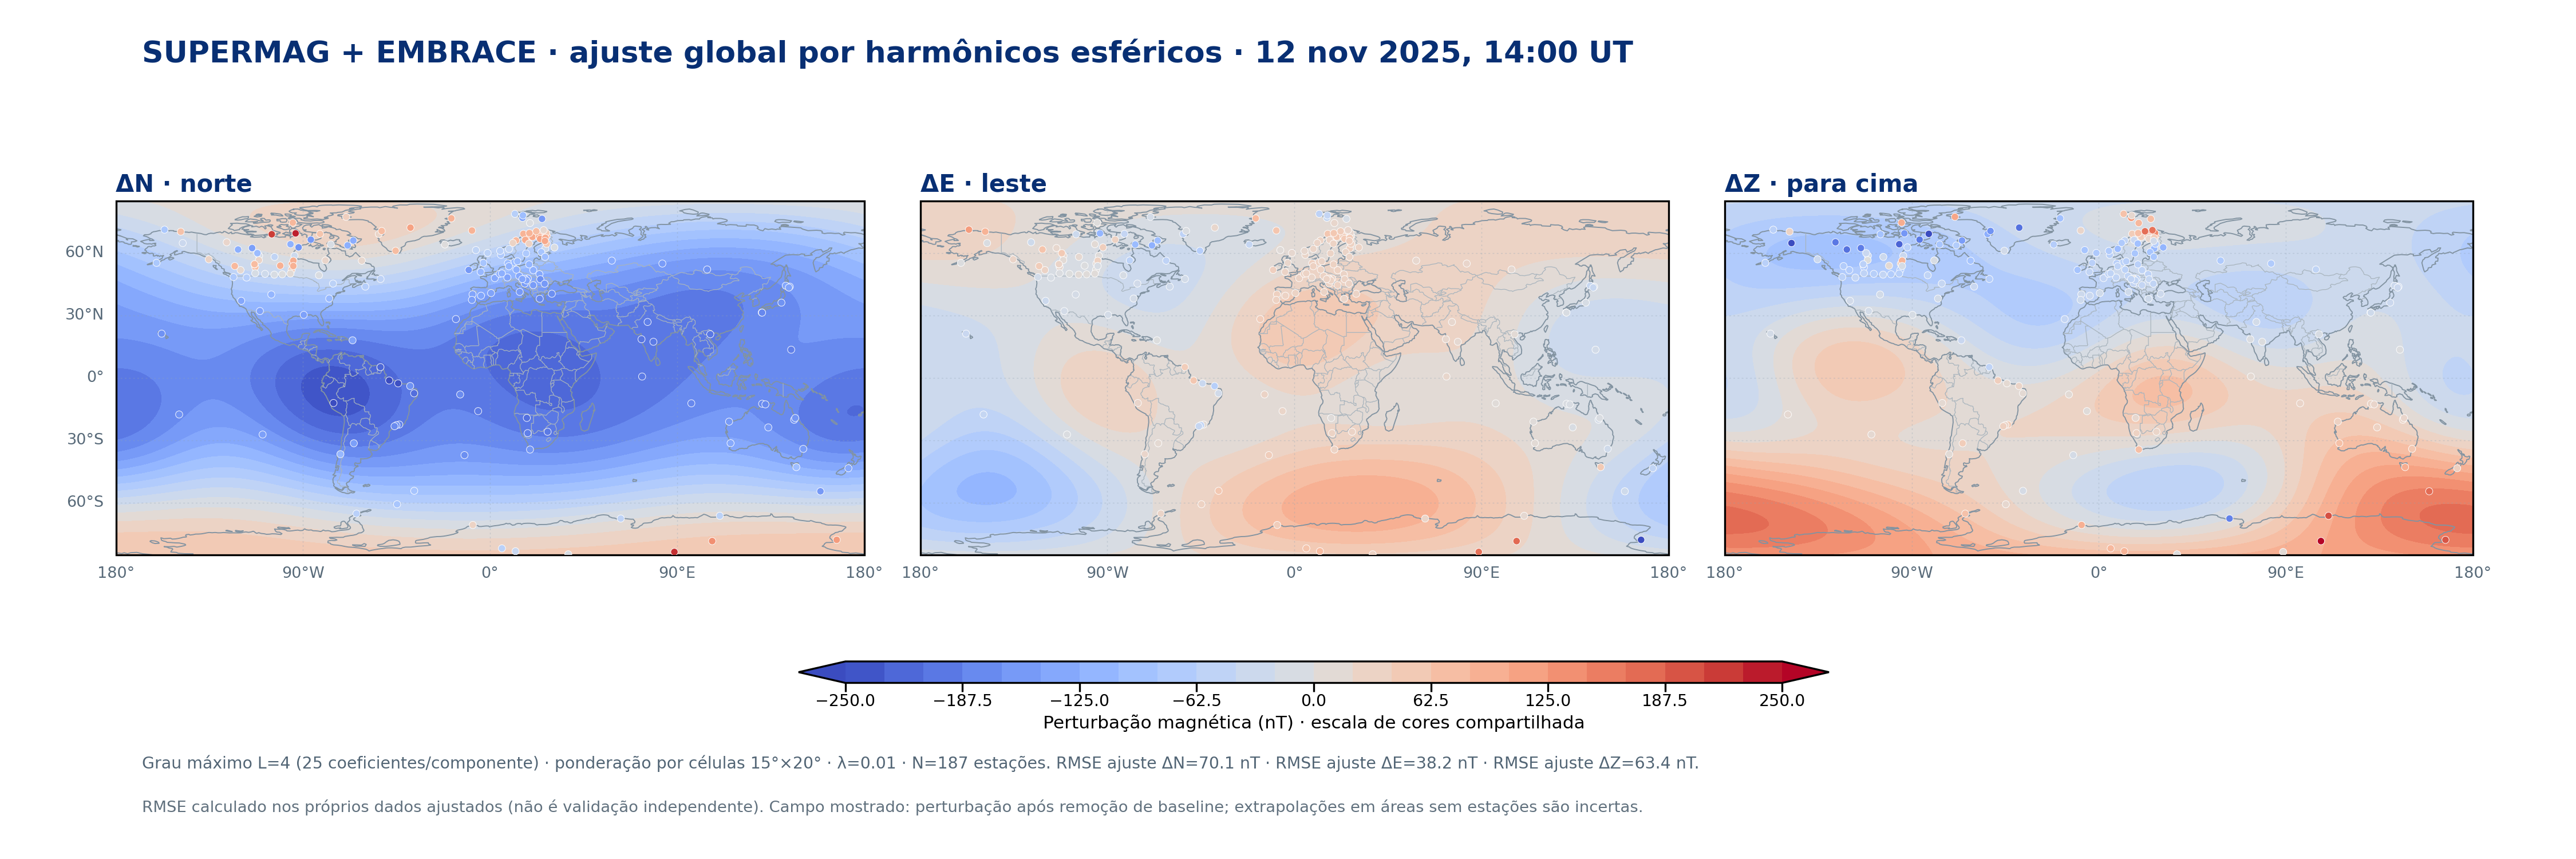

Unique station observations: 187 | real SH coefficients/component: 25
In-sample RMSE (nT): {'ΔN · norte': 70.14, 'ΔE · leste': 38.18, 'ΔZ · para cima': 63.43}
Shared component color range: ± 250.0 nT
Saved spherical-harmonic map: $SBGEA_KEYNOTE_DATA/outputs/figures/embrace/supermag_style_2025-11-10_15/EMBRACE_SuperMAG_spherical_harmonics_2025-11-12_1400UT.png
Saved coefficients: $SBGEA_KEYNOTE_DATA/outputs/data/supermag/SuperMAG_EMBRACE_SH_coefficients_2025-11-12_1400UT.csv


In [14]:
# Configurable real spherical-harmonic interpolation of the measured storm perturbations.
from math import lgamma
from scipy.special import lpmv

SH_LMAX=4                 # 25 real coefficients per component
SH_RIDGE=0.01             # degree-dependent L2 penalty
SH_BIN_LAT_DEG=15.0       # inverse-count weighting reduces station clustering bias
SH_BIN_LON_DEG=20.0
SH_MAP_LAT=np.linspace(-85.0,85.0,171)
SH_MAP_LON=np.linspace(-180.0,180.0,361)
SH_LAT_GRID,SH_LON_GRID=np.meshgrid(SH_MAP_LAT,SH_MAP_LON,indexing="ij")

SH_OBS=GLOBAL_PLOT_VECTORS.copy()
SH_OBS=SH_OBS.dropna(subset=["latitude","longitude","delta_n_nT","delta_e_nT","delta_z_up_nT"])
if SH_OBS.station.duplicated().any():
    raise RuntimeError("The spherical-harmonic input contains duplicate station codes.")
if len(SH_OBS)<(SH_LMAX+1)**2:
    raise ValueError("Fewer observations than spherical-harmonic coefficients.")

def real_spherical_harmonic_design(latitude_deg,longitude_deg,lmax):
    """Return a real, orthonormal-on-the-sphere harmonic design matrix."""
    lat=np.asarray(latitude_deg,dtype=float).reshape(-1)
    lon=np.asarray(longitude_deg,dtype=float).reshape(-1)
    theta=np.deg2rad(90.0-lat)
    phi=np.deg2rad(lon)
    x=np.cos(theta)
    columns=[]; names=[]; degrees=[]
    for ell in range(lmax+1):
        for order in range(ell+1):
            norm=np.sqrt((2*ell+1)/(4*np.pi)*np.exp(
                lgamma(ell-order+1)-lgamma(ell+order+1)))
            p=lpmv(order,ell,x)
            factor=norm if order==0 else np.sqrt(2.0)*norm
            columns.append(factor*p*np.cos(order*phi))
            names.append(f"Y{ell}_{order}c")
            degrees.append(ell)
            if order>0:
                columns.append(factor*p*np.sin(order*phi))
                names.append(f"Y{ell}_{order}s")
                degrees.append(ell)
    return np.column_stack(columns),names,np.asarray(degrees,dtype=float)

SH_A,SH_NAMES,SH_DEGREES=real_spherical_harmonic_design(
    SH_OBS.latitude,SH_OBS.longitude,SH_LMAX)
SH_GRID_A,_,_=real_spherical_harmonic_design(SH_LAT_GRID,SH_LON_GRID,SH_LMAX)
# Give each 15° x 20° geographic bin equal total weight, then normalize mean weight to one.
SH_LAT_BIN=np.floor((SH_OBS.latitude.to_numpy()+90.0)/SH_BIN_LAT_DEG).astype(int)
SH_LON_BIN=np.floor((SH_OBS.longitude.to_numpy()+180.0)/SH_BIN_LON_DEG).astype(int)
SH_BIN_KEYS=np.column_stack([SH_LAT_BIN,SH_LON_BIN])
_,SH_BIN_INDEX,SH_BIN_COUNTS=np.unique(SH_BIN_KEYS,axis=0,return_inverse=True,return_counts=True)
SH_WEIGHTS=1.0/SH_BIN_COUNTS[SH_BIN_INDEX]
SH_WEIGHTS=SH_WEIGHTS/SH_WEIGHTS.mean()
SH_PENALTY=SH_RIDGE*(SH_DEGREES*(SH_DEGREES+1.0))**2
SH_NORMAL=SH_A.T@(SH_WEIGHTS[:,None]*SH_A)+np.diag(SH_PENALTY)

SH_COMPONENTS={
    "ΔN · norte":SH_OBS.delta_n_nT.to_numpy(dtype=float),
    "ΔE · leste":SH_OBS.delta_e_nT.to_numpy(dtype=float),
    "ΔZ · para cima":SH_OBS.delta_z_up_nT.to_numpy(dtype=float),
}
SH_COEFFICIENTS={}; SH_FIELD_MAPS={}; SH_FIT_RMSE={}
for name,values in SH_COMPONENTS.items():
    rhs=SH_A.T@(SH_WEIGHTS*values)
    coef=np.linalg.solve(SH_NORMAL,rhs)
    prediction=SH_A@coef
    SH_COEFFICIENTS[name]=coef
    SH_FIELD_MAPS[name]=(SH_GRID_A@coef).reshape(SH_LAT_GRID.shape)
    SH_FIT_RMSE[name]=float(np.sqrt(np.mean((prediction-values)**2)))

# A shared color scale makes the fitted N, E, and upward-positive Z maps comparable.
SH_ABS=np.concatenate([np.abs(v) for v in SH_COMPONENTS.values()])
SH_COLOR_LIMIT=float(np.ceil(np.nanpercentile(SH_ABS,99)/25.0)*25.0)
SH_LEVELS=np.linspace(-SH_COLOR_LIMIT,SH_COLOR_LIMIT,25)
SH_CMAP="coolwarm"
SH_FIG=plt.figure(figsize=(15.0,5.0),dpi=180,facecolor="white")
SH_GRID_SPEC=SH_FIG.add_gridspec(1,3,left=.045,right=.96,top=.82,bottom=.30,wspace=.075)
SH_AXES=[SH_FIG.add_subplot(SH_GRID_SPEC[0,i],projection=PLATE) for i in range(3)]
SH_CONTOURS=[]
for i,(ax,(name,values)) in enumerate(zip(SH_AXES,SH_COMPONENTS.items())):
    ax.set_extent([-180,180,-85,85],crs=PLATE)
    ax.set_facecolor(PALE_WATER)
    ax.add_feature(cfeature.OCEAN.with_scale("110m"),facecolor=PALE_WATER,zorder=0)
    ax.add_feature(cfeature.LAND.with_scale("110m"),facecolor=PALE_LAND,edgecolor="none",zorder=1)
    ax.add_feature(cfeature.COASTLINE.with_scale("110m"),edgecolor="#8293A1",linewidth=.45,zorder=2)
    ax.add_feature(cfeature.BORDERS.with_scale("110m"),edgecolor="#A8B4BD",linewidth=.3,zorder=2)
    grid=ax.gridlines(crs=PLATE,draw_labels=True,linewidth=.35,color="#91A4B5",alpha=.35,
                      linestyle=(0,(2,3)),zorder=1.5)
    grid.xlocator=mticker.FixedLocator(np.arange(-180,181,90))
    grid.ylocator=mticker.FixedLocator(np.arange(-60,61,30))
    grid.top_labels=False; grid.right_labels=False
    grid.left_labels=(i==0); grid.bottom_labels=True
    grid.xlabel_style={"size":6.5,"color":"#586A79"}
    grid.ylabel_style={"size":6.5,"color":"#586A79"}
    contour=ax.contourf(SH_MAP_LON,SH_MAP_LAT,SH_FIELD_MAPS[name],levels=SH_LEVELS,
                        cmap=SH_CMAP,vmin=-SH_COLOR_LIMIT,vmax=SH_COLOR_LIMIT,
                        extend="both",transform=PLATE,zorder=1.2)
    SH_CONTOURS.append(contour)
    ax.scatter(SH_OBS.longitude,SH_OBS.latitude,c=values,cmap=SH_CMAP,
               vmin=-SH_COLOR_LIMIT,vmax=SH_COLOR_LIMIT,s=9,
               edgecolors="white",linewidths=.22,transform=PLATE,zorder=5)
    ax.set_title(name,loc="left",fontsize=10,fontweight="bold",color=NAVY,pad=4)

SH_CAX=SH_FIG.add_axes([.31,.205,.40,.025])
SH_COLORBAR=SH_FIG.colorbar(SH_CONTOURS[0],cax=SH_CAX,orientation="horizontal",extend="both")
SH_COLORBAR.set_label("Perturbação magnética (nT) · escala de cores compartilhada",fontsize=7.5,labelpad=2)
SH_COLORBAR.ax.tick_params(labelsize=6.8,pad=1)
SH_FIG.suptitle("SUPERMAG + EMBRACE · ajuste global por harmônicos esféricos · 12 nov 2025, 14:00 UT",
                x=.055,y=.955,ha="left",fontsize=12.5,fontweight="bold",color=NAVY)
SH_RMSE_TEXT=" · ".join(f"RMSE ajuste {k.split(' · ')[0]}={v:.1f} nT" for k,v in SH_FIT_RMSE.items())
SH_FIG.text(.055,.105,
    f"Grau máximo L={SH_LMAX} ({(SH_LMAX+1)**2} coeficientes/componente) · ponderação por células {SH_BIN_LAT_DEG:.0f}°×{SH_BIN_LON_DEG:.0f}° · λ={SH_RIDGE:g} · N={len(SH_OBS)} estações. {SH_RMSE_TEXT}.",
    ha="left",fontsize=6.8,color="#526575")
SH_FIG.text(.055,.055,
    "RMSE calculado nos próprios dados ajustados (não é validação independente). Campo mostrado: perturbação após remoção de baseline; extrapolações em áreas sem estações são incertas.",
    ha="left",fontsize=6.6,color="#61717E")
GLOBAL_SH_FIG=STYLE_FIG_DIR/"EMBRACE_SuperMAG_spherical_harmonics_2025-11-12_1400UT.png"
SH_FIG.savefig(GLOBAL_SH_FIG,dpi=300,facecolor="white")
SH_COEF_TABLE=pd.DataFrame({"basis":SH_NAMES,"degree":SH_DEGREES,
    **{name:coef for name,coef in SH_COEFFICIENTS.items()}})
SH_DATA_DIR=KEYNOTE/"outputs"/"data"/"supermag"
SH_DATA_DIR.mkdir(parents=True,exist_ok=True)
SH_COEF_CSV=SH_DATA_DIR/"SuperMAG_EMBRACE_SH_coefficients_2025-11-12_1400UT.csv"
SH_COEF_TABLE.to_csv(SH_COEF_CSV,index=False,float_format="%.8g")
display(IPyImage(filename=str(GLOBAL_SH_FIG)))
plt.close(SH_FIG)
print("Unique station observations:",len(SH_OBS),"| real SH coefficients/component:",(SH_LMAX+1)**2)
print("In-sample RMSE (nT):",{k:round(v,2) for k,v in SH_FIT_RMSE.items()})
print("Shared component color range: ±",SH_COLOR_LIMIT,"nT")
print("Saved spherical-harmonic map:",GLOBAL_SH_FIG)
print("Saved coefficients:",SH_COEF_CSV)


## Campo vetorial global · ΔZ em cores e setas nas estações

O fundo mostra `ΔZ` para cima previsto pelo ajuste harmônico esférico, com faixa de cores fixa de **−300 a +300 nT**. Setas cinza finas mostram `(ΔE, ΔN)` interpolados na grade aleatorizada; setas pretas mostram os vetores medidos nos magnetômetros. Círculos indicam estações com vetor SuperMAG válido; quadrados indicam as estações EMBRACE sul-americanas.


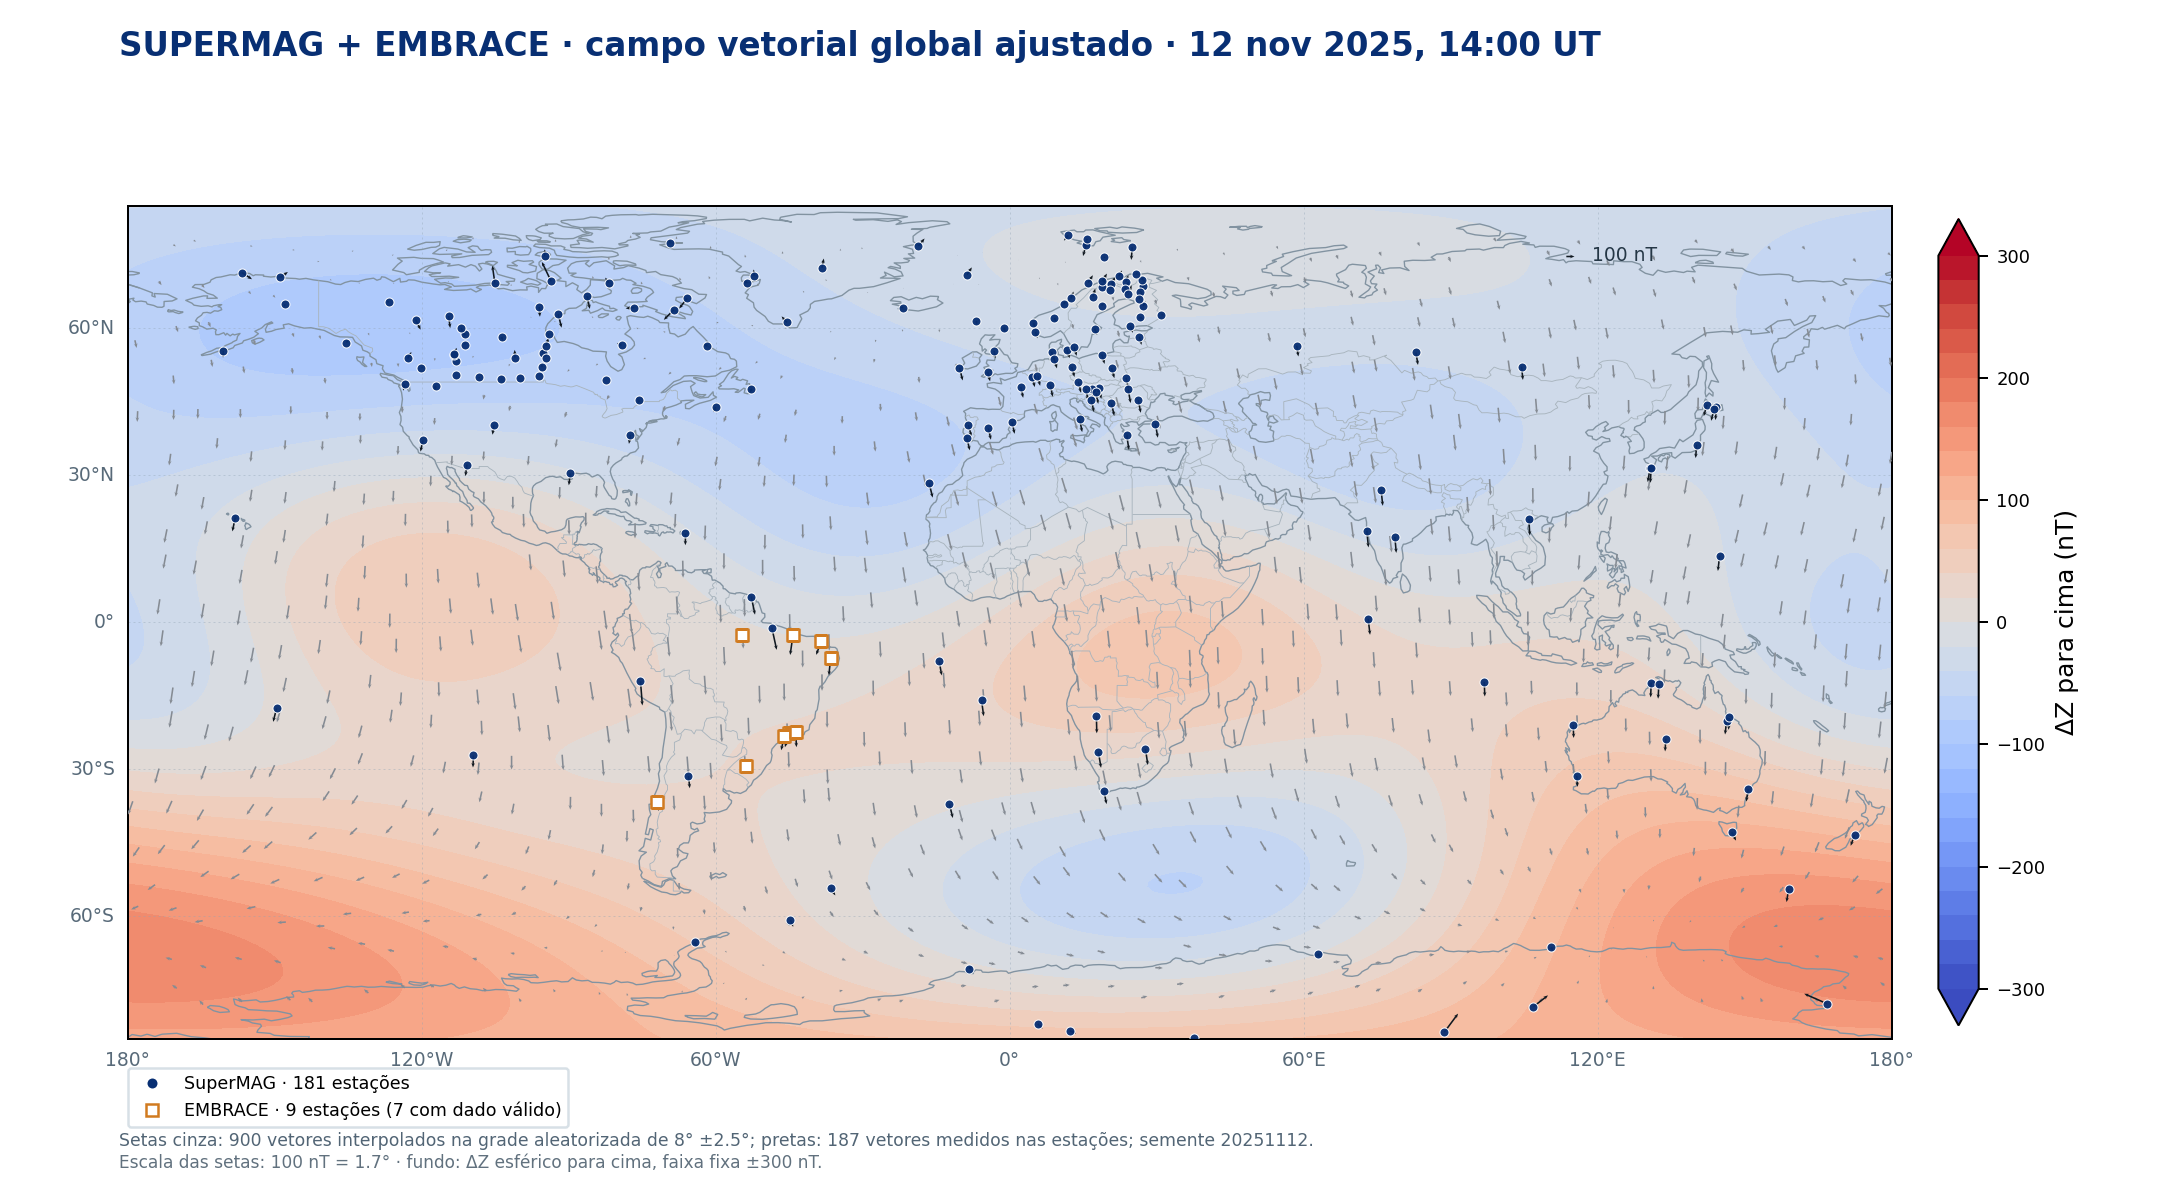

Randomized grid arrows: 900 | measured station arrows: 187
SuperMAG station symbols: 181 | EMBRACE station symbols: 9 | EMBRACE with valid 14 UT sample: 7
Black arrow length scale: 100 nT = 1.67 degrees | ΔZ background range: ± 300.0 nT
Saved map: $SBGEA_KEYNOTE_DATA/outputs/figures/embrace/supermag_style_2025-11-10_15/EMBRACE_SuperMAG_SH_global_vector_randomized_grid_2025-11-12_1400UT.png


In [6]:
# Global map: fitted ΔZ background, gray harmonic-fit arrows, and black measured station arrows.
from matplotlib.lines import Line2D
from matplotlib.colors import TwoSlopeNorm

SH_GRID_SEED=20251112
SH_GRID_SPACING_DEG=8.0
SH_GRID_JITTER_DEG=2.5
SH_GRID_RNG=np.random.default_rng(SH_GRID_SEED)
SH_BASE_LAT=np.arange(-76.0,77.0,SH_GRID_SPACING_DEG)
SH_BASE_LON=np.arange(-180.0,180.0,SH_GRID_SPACING_DEG)
SH_BASE_LON_GRID,SH_BASE_LAT_GRID=np.meshgrid(SH_BASE_LON,SH_BASE_LAT)
SH_RANDOM_LAT=np.clip(SH_BASE_LAT_GRID.ravel()+SH_GRID_RNG.uniform(
    -SH_GRID_JITTER_DEG,SH_GRID_JITTER_DEG,SH_BASE_LAT_GRID.size),-82.0,82.0)
SH_RANDOM_LON=((SH_BASE_LON_GRID.ravel()+SH_GRID_RNG.uniform(
    -SH_GRID_JITTER_DEG,SH_GRID_JITTER_DEG,SH_BASE_LON_GRID.size)+180.0)%360.0)-180.0
SH_ARROW_A,_,_=real_spherical_harmonic_design(SH_RANDOM_LAT,SH_RANDOM_LON,SH_LMAX)
SH_RANDOM_N=SH_ARROW_A@SH_COEFFICIENTS["ΔN · norte"]
SH_RANDOM_E=SH_ARROW_A@SH_COEFFICIENTS["ΔE · leste"]
SH_RANDOM_Z=SH_ARROW_A@SH_COEFFICIENTS["ΔZ · para cima"]

# At instrument positions use the measured horizontal vectors, not interpolated values.
SH_STATION_ARROW_POINTS=GLOBAL_PLOT_VECTORS[[
    "station","longitude","latitude","delta_e_nT","delta_n_nT"]].drop_duplicates("station")
SH_SUPERMAG_STATIONS=global_vectors[["station","longitude","latitude"]].drop_duplicates("station")
SH_EMBRACE_VALID_CODES=set(local_at_time.dropna(subset=[
    "e_anomaly_nT","n_anomaly_nT","z_anomaly_nT"]).station)
SH_EMBRACE_STATIONS=STATION_CATALOG.loc[
    STATION_CATALOG.station.isin(style_stations),["station","longitude","latitude"]].drop_duplicates("station")
SH_ALL_ARROW_LON=np.concatenate([SH_RANDOM_LON,SH_STATION_ARROW_POINTS.longitude.to_numpy(dtype=float)])
SH_ALL_ARROW_LAT=np.concatenate([SH_RANDOM_LAT,SH_STATION_ARROW_POINTS.latitude.to_numpy(dtype=float)])
SH_ALL_ARROW_E=np.concatenate([SH_RANDOM_E,SH_STATION_ARROW_POINTS.delta_e_nT.to_numpy(dtype=float)])
SH_ALL_ARROW_N=np.concatenate([SH_RANDOM_N,SH_STATION_ARROW_POINTS.delta_n_nT.to_numpy(dtype=float)])

SH_FIG_VECTOR=plt.figure(figsize=(12.0,6.6),dpi=160,facecolor="white")
SH_AX_VECTOR=SH_FIG_VECTOR.add_subplot(1,1,1,projection=PLATE)
SH_AX_VECTOR.set_extent([-180,180,-85,85],crs=PLATE)
SH_AX_VECTOR.set_facecolor(PALE_WATER)
SH_AX_VECTOR.add_feature(cfeature.OCEAN.with_scale("110m"),facecolor=PALE_WATER,zorder=0)
SH_AX_VECTOR.add_feature(cfeature.LAND.with_scale("110m"),facecolor=PALE_LAND,edgecolor="none",zorder=1)
SH_AX_VECTOR.add_feature(cfeature.COASTLINE.with_scale("110m"),edgecolor="#8293A1",linewidth=.55,zorder=2)
SH_AX_VECTOR.add_feature(cfeature.BORDERS.with_scale("110m"),edgecolor="#A8B4BD",linewidth=.35,zorder=2)
SH_GRID=SH_AX_VECTOR.gridlines(crs=PLATE,draw_labels=True,linewidth=.4,color="#91A4B5",alpha=.4,
    linestyle=(0,(2,3)),zorder=1.5)
SH_GRID.xlocator=mticker.FixedLocator(np.arange(-180,181,60))
SH_GRID.ylocator=mticker.FixedLocator(np.arange(-60,61,30))
SH_GRID.top_labels=False; SH_GRID.right_labels=False
SH_GRID.xlabel_style={"size":7.5,"color":"#586A79"}; SH_GRID.ylabel_style={"size":7.5,"color":"#586A79"}
# The background uses the same upward-positive ΔZ range as the regional animation.
SH_GLOBAL_COLOR_LIMIT=300.0
SH_GLOBAL_NORM=TwoSlopeNorm(vmin=-SH_GLOBAL_COLOR_LIMIT,vcenter=0.0,vmax=SH_GLOBAL_COLOR_LIMIT)
SH_Z_BACKGROUND=SH_AX_VECTOR.contourf(SH_MAP_LON,SH_MAP_LAT,
    SH_FIELD_MAPS["ΔZ · para cima"],levels=np.linspace(-SH_GLOBAL_COLOR_LIMIT,SH_GLOBAL_COLOR_LIMIT,31),
    cmap="coolwarm",norm=SH_GLOBAL_NORM,extend="both",transform=PLATE,zorder=1.2)
# Gray arrows are harmonic-fit samples; black arrows are measured station vectors.
SH_Q_GRID=SH_AX_VECTOR.quiver(SH_RANDOM_LON,SH_RANDOM_LAT,
    SH_RANDOM_E/ARROW_NT_PER_DEGREE,SH_RANDOM_N/ARROW_NT_PER_DEGREE,
    transform=PLATE,color="#858B93",angles="xy",scale_units="xy",scale=1.0,
    pivot="tail",width=.0009,headwidth=2.4,headlength=3.0,headaxislength=2.2,
    minshaft=1.0,minlength=.2,zorder=7)
SH_Q_STATION=SH_AX_VECTOR.quiver(SH_STATION_ARROW_POINTS.longitude,SH_STATION_ARROW_POINTS.latitude,
    SH_STATION_ARROW_POINTS.delta_e_nT/ARROW_NT_PER_DEGREE,
    SH_STATION_ARROW_POINTS.delta_n_nT/ARROW_NT_PER_DEGREE,
    transform=PLATE,color="#101820",angles="xy",scale_units="xy",scale=1.0,
    pivot="tail",width=.0009,headwidth=2.4,headlength=3.0,headaxislength=2.2,
    minshaft=1.0,minlength=.2,zorder=8)
# Distinguish instrument networks while retaining measured arrows at their locations.
SH_AX_VECTOR.scatter(SH_SUPERMAG_STATIONS.longitude,SH_SUPERMAG_STATIONS.latitude,
    transform=PLATE,s=13,marker="o",facecolor=NAVY,edgecolor="white",
    linewidth=.4,alpha=.95,zorder=9)
SH_AX_VECTOR.scatter(SH_EMBRACE_STATIONS.longitude,SH_EMBRACE_STATIONS.latitude,
    transform=PLATE,s=27,marker="s",facecolor="white",edgecolor="#D17B20",
    linewidth=1.0,zorder=10)
SH_CB_VECTOR=SH_FIG_VECTOR.colorbar(SH_Z_BACKGROUND,ax=SH_AX_VECTOR,fraction=.028,pad=.025,
    shrink=.84,extend="both",label="ΔZ para cima (nT)")
SH_CB_VECTOR.set_ticks(np.arange(-SH_GLOBAL_COLOR_LIMIT,SH_GLOBAL_COLOR_LIMIT+1,100))
SH_CB_VECTOR.ax.tick_params(labelsize=7.2)
SH_AX_VECTOR.quiverkey(SH_Q_STATION,.82,.94,100.0/ARROW_NT_PER_DEGREE,"100 nT",
    labelpos="E",coordinates="axes",fontproperties={"size":7.5},
    color="#101820",labelcolor="#253746")
SH_FIG_VECTOR.suptitle("SUPERMAG + EMBRACE · campo vetorial global ajustado · 12 nov 2025, 14:00 UT",
    x=.055,y=.975,ha="left",fontsize=13,fontweight="bold",color=NAVY)
SH_STATION_LEGEND=[
    Line2D([],[],marker="o",linestyle="none",markersize=5,markerfacecolor=NAVY,
           markeredgecolor="white",label=f"SuperMAG · {len(SH_SUPERMAG_STATIONS)} estações"),
    Line2D([],[],marker="s",linestyle="none",markersize=5,markerfacecolor="white",
           markeredgecolor="#D17B20",label=f"EMBRACE · {len(SH_EMBRACE_STATIONS)} estações ({len(SH_EMBRACE_VALID_CODES)} com dado válido)"),
]
SH_AX_VECTOR.legend(handles=SH_STATION_LEGEND,loc="upper left",
    bbox_to_anchor=(0.0,-.035),borderaxespad=0.0,frameon=True,
    framealpha=.94,facecolor="white",edgecolor="#D5DEE5",fontsize=7)
SH_FIG_VECTOR.text(.055,.035,
    f"Setas cinza: {len(SH_RANDOM_LAT)} vetores interpolados na grade aleatorizada de {SH_GRID_SPACING_DEG:.0f}° ±{SH_GRID_JITTER_DEG:.1f}°; pretas: {len(SH_STATION_ARROW_POINTS)} vetores medidos nas estações; semente {SH_GRID_SEED}.",
    ha="left",fontsize=6.9,color="#526575")
SH_FIG_VECTOR.text(.055,.017,
    f"Escala das setas: 100 nT = {100.0/ARROW_NT_PER_DEGREE:.1f}° · fundo: ΔZ esférico para cima, faixa fixa ±{SH_GLOBAL_COLOR_LIMIT:.0f} nT.",
    ha="left",fontsize=6.8,color="#61717E")
SH_FIG_VECTOR.tight_layout(rect=(.025,.06,.97,.93),pad=.55)
GLOBAL_SH_VECTOR_FIG=STYLE_FIG_DIR/"EMBRACE_SuperMAG_SH_global_vector_randomized_grid_2025-11-12_1400UT.png"
SH_FIG_VECTOR.savefig(GLOBAL_SH_VECTOR_FIG,dpi=180,facecolor="white")
display(IPyImage(filename=str(GLOBAL_SH_VECTOR_FIG)))
plt.close(SH_FIG_VECTOR)
print("Randomized grid arrows:",len(SH_RANDOM_LAT),"| measured station arrows:",len(SH_STATION_ARROW_POINTS))
print("SuperMAG station symbols:",len(SH_SUPERMAG_STATIONS),"| EMBRACE station symbols:",len(SH_EMBRACE_STATIONS),
      "| EMBRACE with valid 14 UT sample:",len(SH_EMBRACE_VALID_CODES))
print("Black arrow length scale: 100 nT =",round(100.0/ARROW_NT_PER_DEGREE,2),"degrees | ΔZ background range: ±",SH_GLOBAL_COLOR_LIMIT,"nT")
print("Saved map:",GLOBAL_SH_VECTOR_FIG)


## Animação global · grade aleatorizada + SuperMAG e EMBRACE

Gera a evolução global **11 nov 22:00 UT a 12 nov 15:00 UT**, amostras medidas de 1 minuto, **34 fps** e 30 segundos. O ajuste usa harmônicos esféricos reais até grau L=4 (25 coeficientes por componente), com ajuste regularizado (λ=0,01) e ponderação espacial em células de 15°×20°. O fundo mostra `ΔZ` ajustado, com faixa fixa de **−300 a +300 nT**. Setas cinza finas mostram `(ΔE, ΔN)` interpolados na grade aleatorizada; setas pretas mostram observações nos magnetômetros. Círculos marcam SuperMAG e quadrados marcam EMBRACE. Os CSVs diários globais são lidos do cache LFS ou baixados e validados na primeira execução.


In [16]:
# Animate the global SH field on the configured 1-minute sample interval.
from io import StringIO
import json
from matplotlib.animation import FuncAnimation, FFMpegWriter
from matplotlib.lines import Line2D
from matplotlib.colors import TwoSlopeNorm
import requests
import time as _time
import cartopy.crs as ccrs
import cartopy.feature as cfeature

GLOBAL_ANIM_START=pd.Timestamp("2025-11-11T22:00:00Z")
GLOBAL_ANIM_STOP=pd.Timestamp("2025-11-12T15:00:00Z")  # exclusive; final sample is 14:59 UT
GLOBAL_ANIM_TIMES=pd.date_range(GLOBAL_ANIM_START,GLOBAL_ANIM_STOP,freq="1min",inclusive="left")
GLOBAL_ANIM_FPS=34  # 1,020 one-minute samples in a 30-second clip
GLOBAL_ANIM_DURATION=len(GLOBAL_ANIM_TIMES)/GLOBAL_ANIM_FPS
GLOBAL_ANIM_COLOR_LIMIT=300.0
GLOBAL_ANIM_Z_NORM=TwoSlopeNorm(vmin=-GLOBAL_ANIM_COLOR_LIMIT,vcenter=0.0,vmax=GLOBAL_ANIM_COLOR_LIMIT)
if len(GLOBAL_ANIM_TIMES)!=1020 or GLOBAL_ANIM_DURATION!=30.0:
    raise RuntimeError(f"Expected 1,020 one-minute frames / 30 s; found {len(GLOBAL_ANIM_TIMES)} / {GLOBAL_ANIM_DURATION:.2f} s")

# Retrieve/cache two UTC days of 60-second SuperMAG vectors. The website_request
# endpoint may append an HTML timeout notice after its complete CSV; only validated
# timestamped data rows are retained in the local cache.
GLOBAL_ANIM_API="https://supermag.jhuapl.edu/lib/services/"
GLOBAL_ANIM_INPUT=KEYNOTE/"inputs"/"supermag"/"global"/"2025"
GLOBAL_ANIM_INPUT.mkdir(parents=True,exist_ok=True)
GLOBAL_ANIM_INVENTORY=GLOBAL_ANIM_INPUT/"supermag_station_inventory.json"
if GLOBAL_ANIM_INVENTORY.exists():
    GLOBAL_ANIM_STATION_INVENTORY=json.loads(GLOBAL_ANIM_INVENTORY.read_text())
else:
    inv_response=requests.get(GLOBAL_ANIM_API,params={"service":"stations","fmt":"json"},timeout=(15,60))
    inv_response.raise_for_status()
    GLOBAL_ANIM_STATION_INVENTORY=inv_response.json()
    GLOBAL_ANIM_INVENTORY.write_text(json.dumps(GLOBAL_ANIM_STATION_INVENTORY,indent=2,ensure_ascii=False)+"\n")
GLOBAL_ANIM_STATION_IDS=sorted({r["id"] for r in GLOBAL_ANIM_STATION_INVENTORY if r.get("id")})
GLOBAL_ANIM_HEADER="Date_UTC,Extent,IAGA,GEOLON,GEOLAT,dbn_nez,dbe_nez,dbz_nez,dbn_geo,dbe_geo,dbz_geo"

def _validated_supermag_day_csv(day,raw_text):
    lines=raw_text.splitlines()
    header=next((line for line in lines if line.startswith("Date_UTC,")),None)
    if header is None:
        raise RuntimeError(f"No CSV header in SuperMAG response for {day}: {raw_text[:250]}")
    rows=[line for line in lines if line.startswith(day) and line.count(",")==10]
    times=pd.DatetimeIndex(pd.to_datetime([line.split(",",1)[0] for line in rows],utc=True)).unique().sort_values()
    expected=pd.date_range(pd.Timestamp(day,tz="UTC"),periods=1440,freq="min")
    if not times.equals(expected):
        raise RuntimeError(f"SuperMAG {day}: expected all 1,440 minutes, got {len(times)} distinct minutes")
    return header+"\n"+"\n".join(rows)+"\n"

def _request_supermag_chunk(session,start,stop):
    end=stop-pd.Timedelta(minutes=1)
    params={"service":"mag","downloadtype":"website_request",
        "start":start.strftime("%Y-%m-%dT%H:%M"),"end":end.strftime("%Y-%m-%dT%H:%M"),
        "stations":",".join(GLOBAL_ANIM_STATION_IDS),"fidelity":"60s",
        "baseline":"all","delta":"none","fmt":"csv"}
    last=None
    for attempt in range(4):
        try:
            response=session.get(GLOBAL_ANIM_API,params=params,timeout=(20,180))
            response.raise_for_status()
            lines=response.text.splitlines()
            header=next((line for line in lines if line.startswith("Date_UTC,")),None)
            if header is None: raise RuntimeError(response.text[:250])
            rows=[line for line in lines if line.startswith(start.strftime("%Y-%m-%d")) and line.count(",")==10]
            times=pd.DatetimeIndex(pd.to_datetime([line.split(",",1)[0] for line in rows],utc=True)).unique().sort_values()
            expected=pd.date_range(start,stop,freq="min",inclusive="left")
            if not times.equals(expected):
                raise RuntimeError(f"Only {len(times)}/{len(expected)} minutes returned for {start} to {stop}")
            return header,rows
        except Exception as exc:
            last=repr(exc)
            if attempt<3: _time.sleep(1.5*(attempt+1))
    raise RuntimeError(f"SuperMAG request failed for {start} to {stop}: {last}")

def _load_or_fetch_supermag_day(day):
    cache=GLOBAL_ANIM_INPUT/(day.replace("-","")+"_supermag_mag_baseline_all.csv")
    if cache.exists():
        try:
            clean=_validated_supermag_day_csv(day,cache.read_text())
            if clean!=cache.read_text(): cache.write_text(clean)
            return clean
        except Exception as exc:
            print("Cached day failed validation; refreshing:",day,exc)
    day_start=pd.Timestamp(day,tz="UTC")
    # Six-hour chunks stay below the SuperMAG web service's PHP execution limit.
    csv_parts=[]; output_header=None
    with requests.Session() as session:
        for offset in range(0,24,6):
            start=day_start+pd.Timedelta(hours=offset)
            stop=start+pd.Timedelta(hours=6)
            header,rows=_request_supermag_chunk(session,start,stop)
            output_header=output_header or header
            csv_parts.extend(rows)
            print(f"SuperMAG {day} {start:%H}–{stop:%H} UT: {len(rows):,} vector rows")
    clean=output_header+"\n"+"\n".join(csv_parts)+"\n"
    clean=_validated_supermag_day_csv(day,clean)
    cache.write_text(clean)
    return clean

GLOBAL_ANIM_DAY_TEXTS=[]
for day in ("2025-11-11","2025-11-12"):
    text_day=_load_or_fetch_supermag_day(day)
    day_frame=pd.read_csv(StringIO(text_day))
    day_frame["time_utc"]=pd.to_datetime(day_frame["Date_UTC"],utc=True)
    day_frame["station"]=day_frame["IAGA"].astype(str).str.strip().str.upper()
    GLOBAL_ANIM_DAY_TEXTS.append(day_frame)
GLOBAL_ANIM_GLOBAL=pd.concat(GLOBAL_ANIM_DAY_TEXTS,ignore_index=True)
for column in ("GEOLON","GEOLAT","dbn_geo","dbe_geo","dbz_geo"):
    GLOBAL_ANIM_GLOBAL[column]=pd.to_numeric(GLOBAL_ANIM_GLOBAL[column],errors="coerce")
GLOBAL_ANIM_GLOBAL[["dbn_geo","dbe_geo","dbz_geo"]]=GLOBAL_ANIM_GLOBAL[["dbn_geo","dbe_geo","dbz_geo"]].replace([999999,-999999,1e31,-1e31],np.nan)
GLOBAL_ANIM_GLOBAL=GLOBAL_ANIM_GLOBAL.dropna(subset=["time_utc","station","GEOLON","GEOLAT"])
GLOBAL_ANIM_GLOBAL=GLOBAL_ANIM_GLOBAL.drop_duplicates(["time_utc","station"],keep="first")
GLOBAL_ANIM_GLOBAL["longitude"]=((GLOBAL_ANIM_GLOBAL["GEOLON"]+180.0)%360.0)-180.0
GLOBAL_ANIM_GLOBAL["latitude"]=GLOBAL_ANIM_GLOBAL["GEOLAT"]
GLOBAL_ANIM_GLOBAL["z_up_nT"]=-GLOBAL_ANIM_GLOBAL["dbz_geo"]
GLOBAL_ANIM_MINUTES=pd.DatetimeIndex(GLOBAL_ANIM_GLOBAL.time_utc.unique()).sort_values()
if not GLOBAL_ANIM_TIMES.isin(GLOBAL_ANIM_MINUTES).all():
    missing_times=GLOBAL_ANIM_TIMES[~GLOBAL_ANIM_TIMES.isin(GLOBAL_ANIM_MINUTES)]
    raise RuntimeError(f"Global SuperMAG data missing {len(missing_times)} requested minutes; first missing: {missing_times[:3].tolist()}")

GLOBAL_ANIM_GLOBAL_CODES=sorted(GLOBAL_ANIM_GLOBAL.station.unique())
GLOBAL_ANIM_LOCAL_CODES=sorted(set(style_stations))
GLOBAL_ANIM_CODES=sorted(set(GLOBAL_ANIM_GLOBAL_CODES)|set(GLOBAL_ANIM_LOCAL_CODES))
GLOBAL_ANIM_COORDS=GLOBAL_ANIM_GLOBAL.drop_duplicates("station").set_index("station")[["longitude","latitude"]].reindex(GLOBAL_ANIM_CODES)
local_coord_index=STATION_CATALOG.set_index("station")[["longitude","latitude"]]
missing_coord=GLOBAL_ANIM_COORDS.longitude.isna()
GLOBAL_ANIM_COORDS.loc[missing_coord]=local_coord_index.reindex(GLOBAL_ANIM_COORDS.index[missing_coord])
if GLOBAL_ANIM_COORDS.isna().any().any():
    raise RuntimeError("A station used in the animated fit has no geographic coordinates")

def _global_anim_matrix(frame,time_name,value_name):
    wide=frame.pivot(index=time_name,columns="station",values=value_name)
    return wide.reindex(index=GLOBAL_ANIM_TIMES,columns=GLOBAL_ANIM_CODES).to_numpy(dtype=float)

G_E=_global_anim_matrix(GLOBAL_ANIM_GLOBAL,"time_utc","dbe_geo")
G_N=_global_anim_matrix(GLOBAL_ANIM_GLOBAL,"time_utc","dbn_geo")
G_Z=_global_anim_matrix(GLOBAL_ANIM_GLOBAL,"time_utc","z_up_nT")
L_E=_global_anim_matrix(style_window,"time_utc","e_anomaly_nT")
L_N=_global_anim_matrix(style_window,"time_utc","n_anomaly_nT")
L_Z=-_global_anim_matrix(style_window,"time_utc","z_anomaly_nT")
G_VALID=np.isfinite(G_E)&np.isfinite(G_N)&np.isfinite(G_Z)
L_VALID=np.isfinite(L_E)&np.isfinite(L_N)&np.isfinite(L_Z)
USE_LOCAL=L_VALID&~G_VALID
OBS_E=np.where(G_VALID,G_E,np.where(USE_LOCAL,L_E,np.nan))
OBS_N=np.where(G_VALID,G_N,np.where(USE_LOCAL,L_N,np.nan))
OBS_Z=np.where(G_VALID,G_Z,np.where(USE_LOCAL,L_Z,np.nan))
OBS_VALID=np.isfinite(OBS_E)&np.isfinite(OBS_N)&np.isfinite(OBS_Z)

GLOBAL_ANIM_LMAX=SH_LMAX
GLOBAL_ANIM_RIDGE=SH_RIDGE
GLOBAL_ANIM_STATION_LAT=GLOBAL_ANIM_COORDS.latitude.to_numpy(dtype=float)
GLOBAL_ANIM_STATION_LON=GLOBAL_ANIM_COORDS.longitude.to_numpy(dtype=float)
GLOBAL_ANIM_STATION_A,_,GLOBAL_ANIM_DEGREES=real_spherical_harmonic_design(
    GLOBAL_ANIM_STATION_LAT,GLOBAL_ANIM_STATION_LON,GLOBAL_ANIM_LMAX)
GLOBAL_ANIM_PENALTY=GLOBAL_ANIM_RIDGE*(GLOBAL_ANIM_DEGREES*(GLOBAL_ANIM_DEGREES+1.0))**2
# Cell-balanced weights reduce the influence of dense station clusters in Europe/North America.
GLOBAL_ANIM_LAT_BIN=np.floor((GLOBAL_ANIM_STATION_LAT+90.0)/SH_BIN_LAT_DEG).astype(int)
GLOBAL_ANIM_LON_BIN=np.floor((GLOBAL_ANIM_STATION_LON+180.0)/SH_BIN_LON_DEG).astype(int)
GLOBAL_ANIM_BIN_KEYS=np.column_stack([GLOBAL_ANIM_LAT_BIN,GLOBAL_ANIM_LON_BIN])
GLOBAL_ANIM_COEFS=np.full((len(GLOBAL_ANIM_TIMES),(GLOBAL_ANIM_LMAX+1)**2,3),np.nan,dtype=float)
GLOBAL_ANIM_NOBS=np.zeros(len(GLOBAL_ANIM_TIMES),dtype=int)
for frame_index in range(len(GLOBAL_ANIM_TIMES)):
    valid_index=np.flatnonzero(OBS_VALID[frame_index])
    GLOBAL_ANIM_NOBS[frame_index]=len(valid_index)
    if len(valid_index)<(GLOBAL_ANIM_LMAX+1)**2:
        continue
    _,bin_index,bin_counts=np.unique(GLOBAL_ANIM_BIN_KEYS[valid_index],axis=0,
                                     return_inverse=True,return_counts=True)
    weight=1.0/bin_counts[bin_index]
    weight=weight/weight.mean()
    basis=GLOBAL_ANIM_STATION_A[valid_index]
    normal=basis.T@(weight[:,None]*basis)+np.diag(GLOBAL_ANIM_PENALTY)
    observations=np.column_stack([OBS_N[frame_index,valid_index],
                                  OBS_E[frame_index,valid_index],
                                  OBS_Z[frame_index,valid_index]])
    rhs=basis.T@(weight[:,None]*observations)
    GLOBAL_ANIM_COEFS[frame_index]=np.linalg.solve(normal,rhs)
if not np.isfinite(GLOBAL_ANIM_COEFS).all():
    raise RuntimeError("At least one minute lacked enough valid vectors for the spherical-harmonic fit")
print(f"Global vectors/frame: {GLOBAL_ANIM_NOBS.min()}–{GLOBAL_ANIM_NOBS.max()} | measured global stations: {len(GLOBAL_ANIM_GLOBAL_CODES)} | EMBRACE files: {len(GLOBAL_ANIM_LOCAL_CODES)}")

# A fixed jittered arrow grid and 2-degree background grid for the whole movie.
GLOBAL_ANIM_GRID_SEED=20251112
GLOBAL_ANIM_GRID_SPACING=8.0
GLOBAL_ANIM_GRID_JITTER=2.5
_global_rng=np.random.default_rng(GLOBAL_ANIM_GRID_SEED)
_base_lat=np.arange(-76.0,77.0,GLOBAL_ANIM_GRID_SPACING)
_base_lon=np.arange(-180.0,180.0,GLOBAL_ANIM_GRID_SPACING)
_base_lon_grid,_base_lat_grid=np.meshgrid(_base_lon,_base_lat)
GLOBAL_ANIM_ARROW_LAT=np.clip(_base_lat_grid.ravel()+_global_rng.uniform(
    -GLOBAL_ANIM_GRID_JITTER,GLOBAL_ANIM_GRID_JITTER,_base_lat_grid.size),-82.0,82.0)
GLOBAL_ANIM_ARROW_LON=((_base_lon_grid.ravel()+_global_rng.uniform(
    -GLOBAL_ANIM_GRID_JITTER,GLOBAL_ANIM_GRID_JITTER,_base_lon_grid.size)+180.0)%360.0)-180.0
GLOBAL_ANIM_ARROW_A,_,_=real_spherical_harmonic_design(
    GLOBAL_ANIM_ARROW_LAT,GLOBAL_ANIM_ARROW_LON,GLOBAL_ANIM_LMAX)
GLOBAL_ANIM_BG_LAT=np.arange(-85.0,85.01,2.0)
GLOBAL_ANIM_BG_LON=np.arange(-180.0,180.01,2.0)
GLOBAL_ANIM_BG_LON_GRID,GLOBAL_ANIM_BG_LAT_GRID=np.meshgrid(GLOBAL_ANIM_BG_LON,GLOBAL_ANIM_BG_LAT)
GLOBAL_ANIM_BG_A,_,_=real_spherical_harmonic_design(
    GLOBAL_ANIM_BG_LAT_GRID,GLOBAL_ANIM_BG_LON_GRID,GLOBAL_ANIM_LMAX)

# Stable station markers; observed arrows are updated/masked for each measured minute.
GLOBAL_ANIM_GLOBAL_CODES=np.flatnonzero(np.any(G_VALID,axis=0))
GLOBAL_ANIM_LOCAL_MARK_CODES=GLOBAL_ANIM_LOCAL_CODES
GLOBAL_ANIM_GLOBAL_LON=GLOBAL_ANIM_STATION_LON[GLOBAL_ANIM_GLOBAL_CODES]
GLOBAL_ANIM_GLOBAL_LAT=GLOBAL_ANIM_STATION_LAT[GLOBAL_ANIM_GLOBAL_CODES]
GLOBAL_ANIM_GLOBAL_NAMES=np.asarray(GLOBAL_ANIM_CODES,dtype=object)[GLOBAL_ANIM_GLOBAL_CODES]
GLOBAL_ANIM_LOCAL_LOC=STATION_CATALOG.set_index("station").loc[GLOBAL_ANIM_LOCAL_MARK_CODES].reset_index()
GLOBAL_ANIM_ARROW_STATIONS=np.flatnonzero(np.any(OBS_VALID,axis=0))
GLOBAL_ANIM_ARROW_STATION_LON=GLOBAL_ANIM_STATION_LON[GLOBAL_ANIM_ARROW_STATIONS]
GLOBAL_ANIM_ARROW_STATION_LAT=GLOBAL_ANIM_STATION_LAT[GLOBAL_ANIM_ARROW_STATIONS]

GLOBAL_ANIM_OUTPUT_DIR=KEYNOTE/"outputs"/"figures"/"embrace"/"supermag_style_2025-11-10_15"
GLOBAL_ANIM_OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
GLOBAL_ANIM_MP4=GLOBAL_ANIM_OUTPUT_DIR/"EMBRACE_SuperMAG_global_SH_storm_2025-11-11_2200_to_2025-11-12_1500UT.mp4"
GLOBAL_ANIM_BLACK="#101820"
GLOBAL_ANIM_FIT_GRAY="#858B93"
fig_global=plt.figure(figsize=(12.0,6.6),dpi=160,facecolor="white")
ax_global=fig_global.add_subplot(1,1,1,projection=PLATE)
ax_global.set_extent([-180,180,-85,85],crs=PLATE)
ax_global.set_facecolor(PALE_WATER)
first_coef=GLOBAL_ANIM_COEFS[0]
first_z=(GLOBAL_ANIM_BG_A@first_coef[:,2]).reshape(GLOBAL_ANIM_BG_LAT_GRID.shape)
zmesh=ax_global.pcolormesh(GLOBAL_ANIM_BG_LON,GLOBAL_ANIM_BG_LAT,first_z,
    shading="auto",cmap="coolwarm",norm=GLOBAL_ANIM_Z_NORM,transform=PLATE,zorder=1.2)
# The ΔZ raster covers both land and ocean; coastlines are drawn above it.
ax_global.add_feature(cfeature.COASTLINE.with_scale("110m"),edgecolor="#8293A1",linewidth=.55,zorder=2)
ax_global.add_feature(cfeature.BORDERS.with_scale("110m"),edgecolor="#A8B4BD",linewidth=.35,zorder=2)
grid_global=ax_global.gridlines(crs=PLATE,draw_labels=True,linewidth=.4,color="#91A4B5",alpha=.4,
    linestyle=(0,(2,3)),zorder=2.1)
grid_global.xlocator=mticker.FixedLocator(np.arange(-180,181,60))
grid_global.ylocator=mticker.FixedLocator(np.arange(-60,61,30))
grid_global.top_labels=False; grid_global.right_labels=False
grid_global.xlabel_style={"size":7.5,"color":"#586A79"}; grid_global.ylabel_style={"size":7.5,"color":"#586A79"}
first_grid=(GLOBAL_ANIM_ARROW_A@first_coef)
qgrid=ax_global.quiver(GLOBAL_ANIM_ARROW_LON,GLOBAL_ANIM_ARROW_LAT,
    first_grid[:,1]/ARROW_NT_PER_DEGREE,first_grid[:,0]/ARROW_NT_PER_DEGREE,
    transform=PLATE,color=GLOBAL_ANIM_FIT_GRAY,angles="xy",scale_units="xy",scale=1.0,
    pivot="tail",width=.0009,headwidth=2.4,headlength=3.0,headaxislength=2.2,
    minshaft=1.0,minlength=.2,zorder=6)
qstation=ax_global.quiver(GLOBAL_ANIM_ARROW_STATION_LON,GLOBAL_ANIM_ARROW_STATION_LAT,
    np.ma.masked_invalid(OBS_E[0,GLOBAL_ANIM_ARROW_STATIONS]/ARROW_NT_PER_DEGREE),
    np.ma.masked_invalid(OBS_N[0,GLOBAL_ANIM_ARROW_STATIONS]/ARROW_NT_PER_DEGREE),
    transform=PLATE,color=GLOBAL_ANIM_BLACK,angles="xy",scale_units="xy",scale=1.0,
    pivot="tail",width=.0009,headwidth=2.4,headlength=3.0,headaxislength=2.2,
    minshaft=1.0,minlength=.2,zorder=7)
ax_global.scatter(GLOBAL_ANIM_GLOBAL_LON,GLOBAL_ANIM_GLOBAL_LAT,transform=PLATE,
    s=13,marker="o",facecolor=NAVY,edgecolor="white",linewidth=.4,alpha=.95,zorder=9)
ax_global.scatter(GLOBAL_ANIM_LOCAL_LOC.longitude,GLOBAL_ANIM_LOCAL_LOC.latitude,
    transform=PLATE,s=27,marker="s",facecolor="white",edgecolor="#D17B20",linewidth=1.0,zorder=10)
colorbar_global=fig_global.colorbar(zmesh,ax=ax_global,fraction=.028,pad=.025,
    shrink=.84,extend="both",label="ΔZ ajustado para cima (nT)")
colorbar_global.set_ticks(np.arange(-GLOBAL_ANIM_COLOR_LIMIT,GLOBAL_ANIM_COLOR_LIMIT+1,100))
colorbar_global.ax.tick_params(labelsize=7.2)
ax_global.quiverkey(qgrid,.82,.94,100.0/ARROW_NT_PER_DEGREE,"100 nT",
    labelpos="E",coordinates="axes",fontproperties={"size":7.5},
    color=GLOBAL_ANIM_BLACK,labelcolor="#253746")
time_label_global=ax_global.text(.025,.965,"",transform=ax_global.transAxes,ha="left",va="top",
    fontsize=10,fontweight="bold",color=NAVY,
    bbox={"boxstyle":"round,pad=.3","facecolor":"white","edgecolor":"#D5DEE5","alpha":.96},zorder=11)
fig_global.suptitle("SUPERMAG + EMBRACE · progressão global da tempestade · campo ajustado",
    x=.055,y=.975,ha="left",fontsize=13,fontweight="bold",color=NAVY)
fig_global.text(.055,.918,"AJUSTE POR HARMÔNICOS ESFÉRICOS REAIS",
    ha="left",fontsize=8.8,fontweight="bold",color=NAVY)
sh_equation=(rf"$\Delta B_c(\phi,\lambda)=\sum_{{\ell=0}}^{{{GLOBAL_ANIM_LMAX}}}"
             rf"\sum_{{m=-\ell}}^{{\ell}}a_{{\ell m,c}}Y_{{\ell m}}(\phi,\lambda)$")
fig_global.text(.055,.892,
    sh_equation + f" · c∈{{N,E,Z}} · {(GLOBAL_ANIM_LMAX+1)**2} coef./componente · λ={GLOBAL_ANIM_RIDGE:g} · pesos {SH_BIN_LAT_DEG:.0f}°×{SH_BIN_LON_DEG:.0f}°",
    ha="left",fontsize=8.0,color="#526575")
legend_global=[
    Line2D([],[],marker="o",linestyle="none",markersize=5,markerfacecolor=NAVY,
           markeredgecolor="white",label=f"SuperMAG · {len(GLOBAL_ANIM_GLOBAL_CODES)} estações"),
    Line2D([],[],marker="s",linestyle="none",markersize=5,markerfacecolor="white",
           markeredgecolor="#D17B20",label=f"EMBRACE · {len(GLOBAL_ANIM_LOCAL_CODES)} estações"),
]
ax_global.legend(handles=legend_global,loc="upper left",bbox_to_anchor=(0.0,-.035),
    borderaxespad=0.0,frameon=True,framealpha=.94,facecolor="white",edgecolor="#D5DEE5",fontsize=7)
fig_global.text(.055,.052,
    f"Setas cinza: vetores ajustados em {len(GLOBAL_ANIM_ARROW_LAT)} pontos interpolados · pretas: medições nas estações · escala: 100 nT = {100.0/ARROW_NT_PER_DEGREE:.1f}°.",
    ha="left",fontsize=7.0,color="#526575")
fig_global.text(.055,.029,
    f"Fundo: ΔZ ajustado para cima · faixa ±{GLOBAL_ANIM_COLOR_LIMIT:.0f} nT · amostras de 1 min · SuperMAG baseline=all/delta=none · EMBRACE: baselines anual/diário e offset removidos.",
    ha="left",fontsize=6.8,color="#61717E")
fig_global.tight_layout(rect=(.025,.13,.97,.875),pad=.55)

def _update_global_frame(frame_index):
    coef=GLOBAL_ANIM_COEFS[frame_index]
    background=(GLOBAL_ANIM_BG_A@coef[:,2]).reshape(-1)
    zmesh.set_array(background)
    grid_field=GLOBAL_ANIM_ARROW_A@coef
    qgrid.set_UVC(grid_field[:,1]/ARROW_NT_PER_DEGREE,
                  grid_field[:,0]/ARROW_NT_PER_DEGREE)
    qstation.set_UVC(np.ma.masked_invalid(OBS_E[frame_index,GLOBAL_ANIM_ARROW_STATIONS]/ARROW_NT_PER_DEGREE),
                     np.ma.masked_invalid(OBS_N[frame_index,GLOBAL_ANIM_ARROW_STATIONS]/ARROW_NT_PER_DEGREE))
    time_label_global.set_text(GLOBAL_ANIM_TIMES[frame_index].strftime("%d %b %Y · %H:%M UT"))
    return zmesh,qgrid,qstation,time_label_global

global_storm_animation=FuncAnimation(fig_global,_update_global_frame,
    frames=len(GLOBAL_ANIM_TIMES),interval=1000/GLOBAL_ANIM_FPS,blit=False,repeat=True)
global_writer=FFMpegWriter(fps=GLOBAL_ANIM_FPS,bitrate=1600,
    metadata={"title":"SuperMAG and EMBRACE global storm progression"})
global_storm_animation.save(GLOBAL_ANIM_MP4,writer=global_writer,dpi=300)
plt.close(fig_global)
print("Global daily caches:",*[GLOBAL_ANIM_INPUT/(d.replace("-","")+"_supermag_mag_baseline_all.csv") for d in ("2025-11-11","2025-11-12")],sep="\n  ")
print(f"Frames: {len(GLOBAL_ANIM_TIMES):,} measured 1-minute samples at {GLOBAL_ANIM_FPS} fps | duration {GLOBAL_ANIM_DURATION:.1f} s")
print(f"Vectors per fit: {GLOBAL_ANIM_NOBS.min()}–{GLOBAL_ANIM_NOBS.max()} | SH degree L={GLOBAL_ANIM_LMAX} | grid arrows {len(GLOBAL_ANIM_ARROW_LAT)}")
print("Saved global storm animation:",GLOBAL_ANIM_MP4)


Global vectors/frame: 186–188 | measured global stations: 189 | EMBRACE files: 9
Global daily caches:
  $SBGEA_KEYNOTE_DATA/inputs/supermag/global/2025/20251111_supermag_mag_baseline_all.csv
  $SBGEA_KEYNOTE_DATA/inputs/supermag/global/2025/20251112_supermag_mag_baseline_all.csv
Frames: 1,020 measured 1-minute samples at 34 fps | duration 30.0 s
Vectors per fit: 186–188 | SH degree L=4 | grid arrows 900
Saved global storm animation: $SBGEA_KEYNOTE_DATA/outputs/figures/embrace/supermag_style_2025-11-10_15/EMBRACE_SuperMAG_global_SH_storm_2025-11-11_2200_to_2025-11-12_1500UT.mp4


## Métricas do painel USGS/SuperMAG · instantâneo de 28 out. 2026

Esta seção plota as três famílias de dados exportadas do painel: cobertura anual por estação, contagens mensais de downloads e line plots por estação, e estatísticas mensais de uso do site. Os arquivos `.txt` são conferidos contra seus equivalentes `.csv`; `webstats.txt` é analisado diretamente. As figuras mantêm as lacunas dos dados, inclusive os valores `na` no histórico de downloads.


As três figuras são exibidas no notebook e exportadas em PNG para `LFS/KEYNOTE/outputs/figures/supermag/dashboard/`. As séries mensais são reindexadas para preservar lacunas; as séries de contagem usam escalas logarítmicas para manter visíveis tanto os meses típicos quanto os picos.

Tamanho de exportação (largura × altura): cobertura anual 5,54″ × 6,03″; atividade mensal 7,8″ × 7,8″; estatísticas do site 12,23″ × 5,75″ (300 dpi).

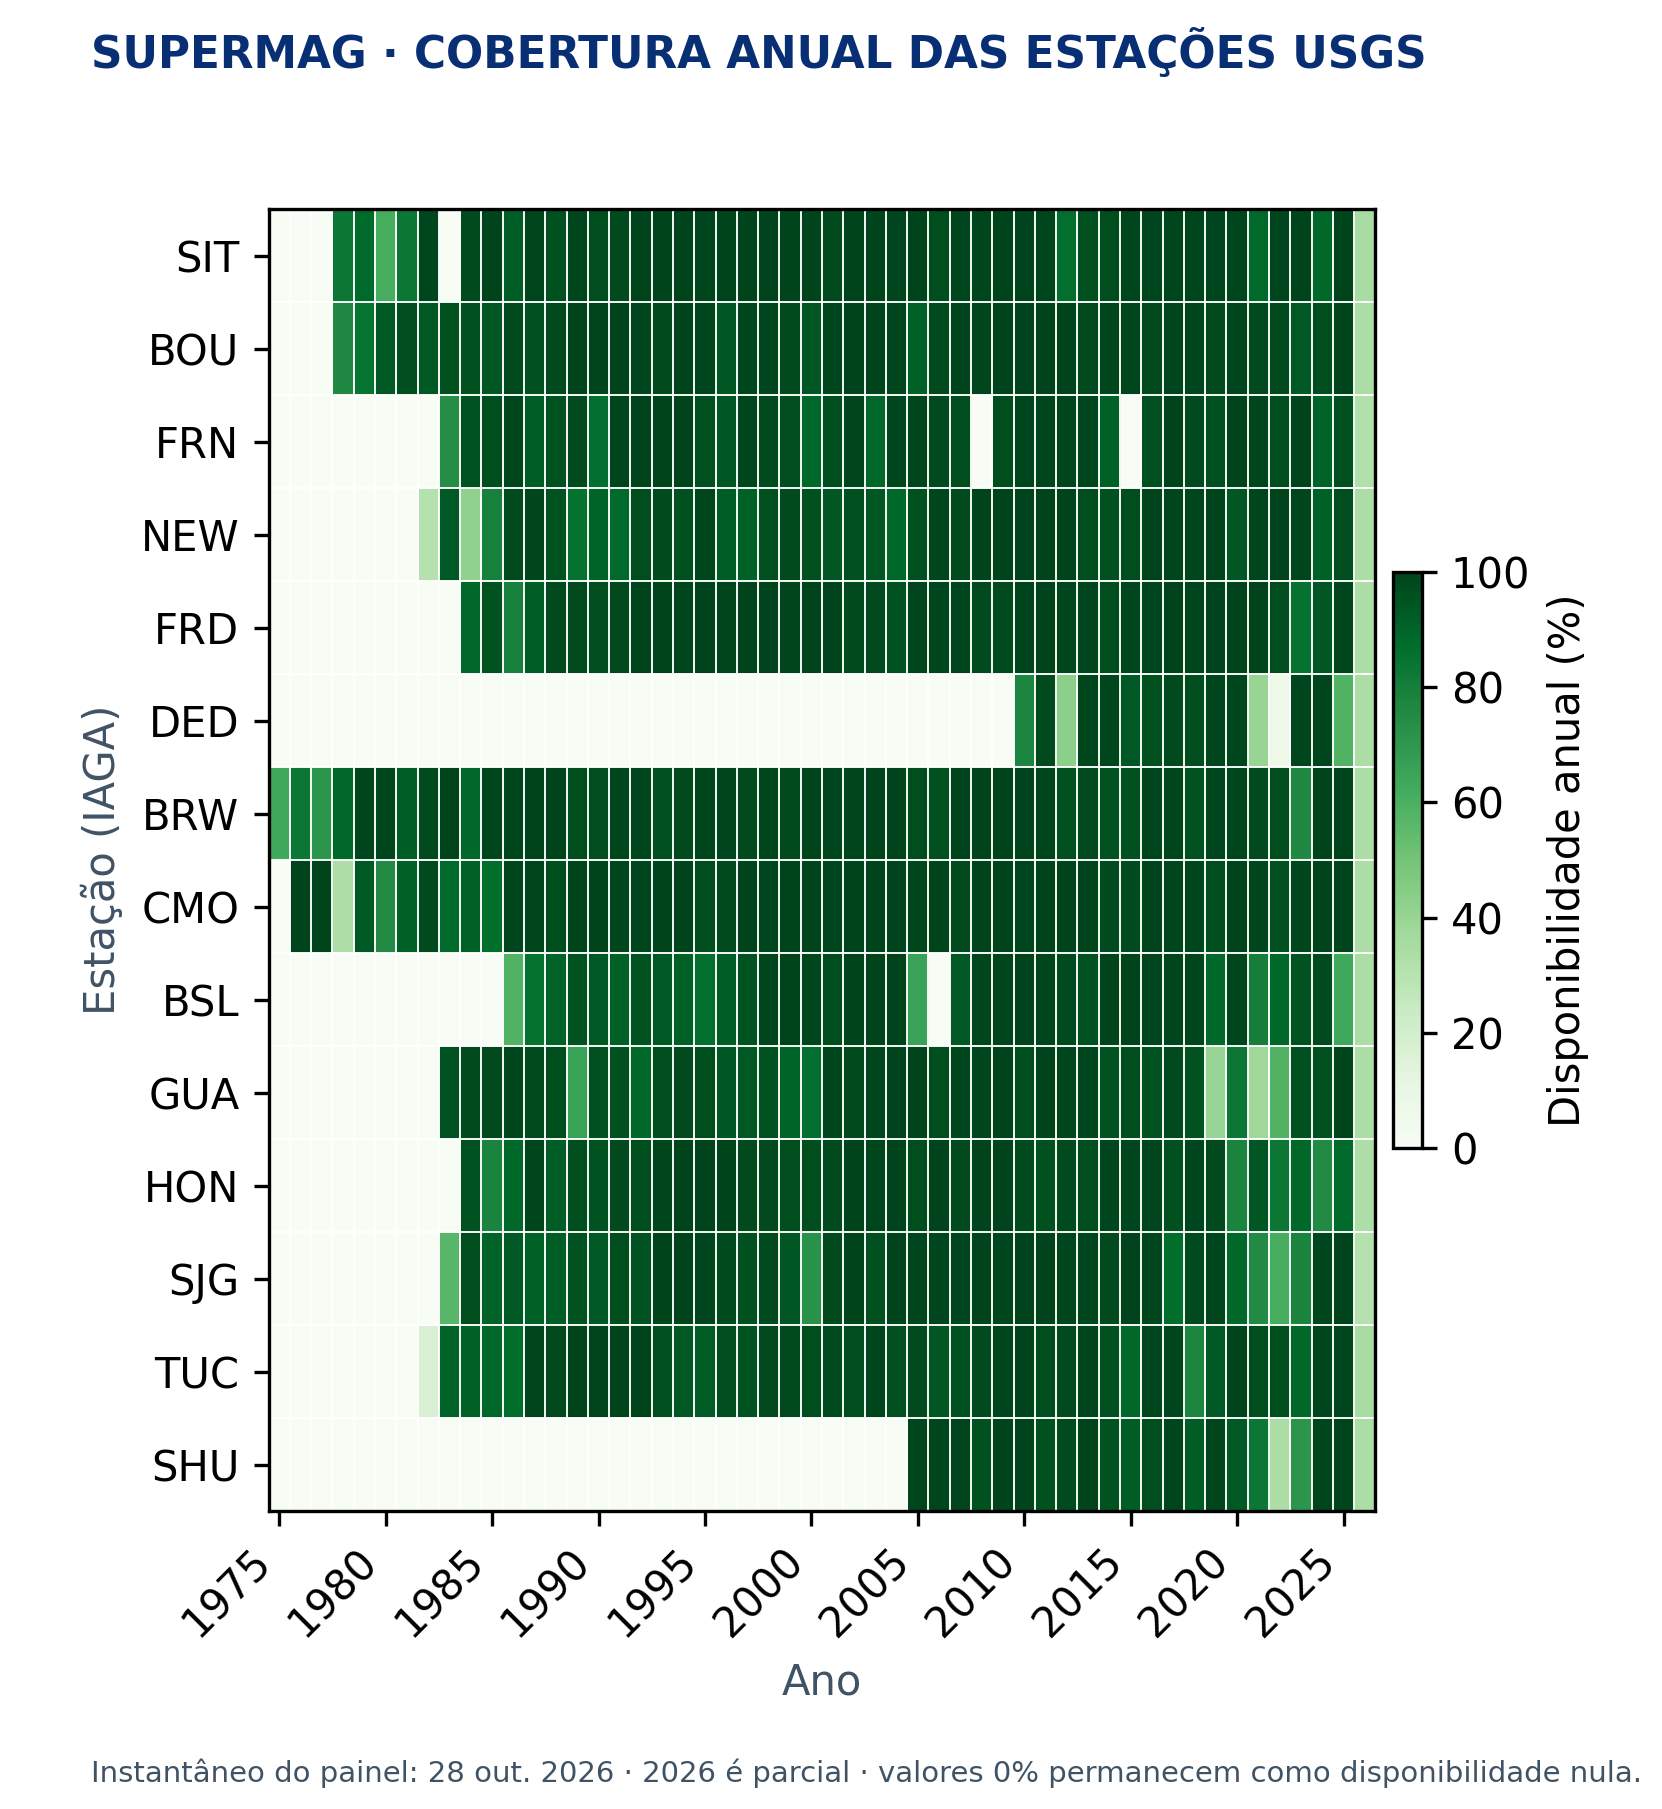

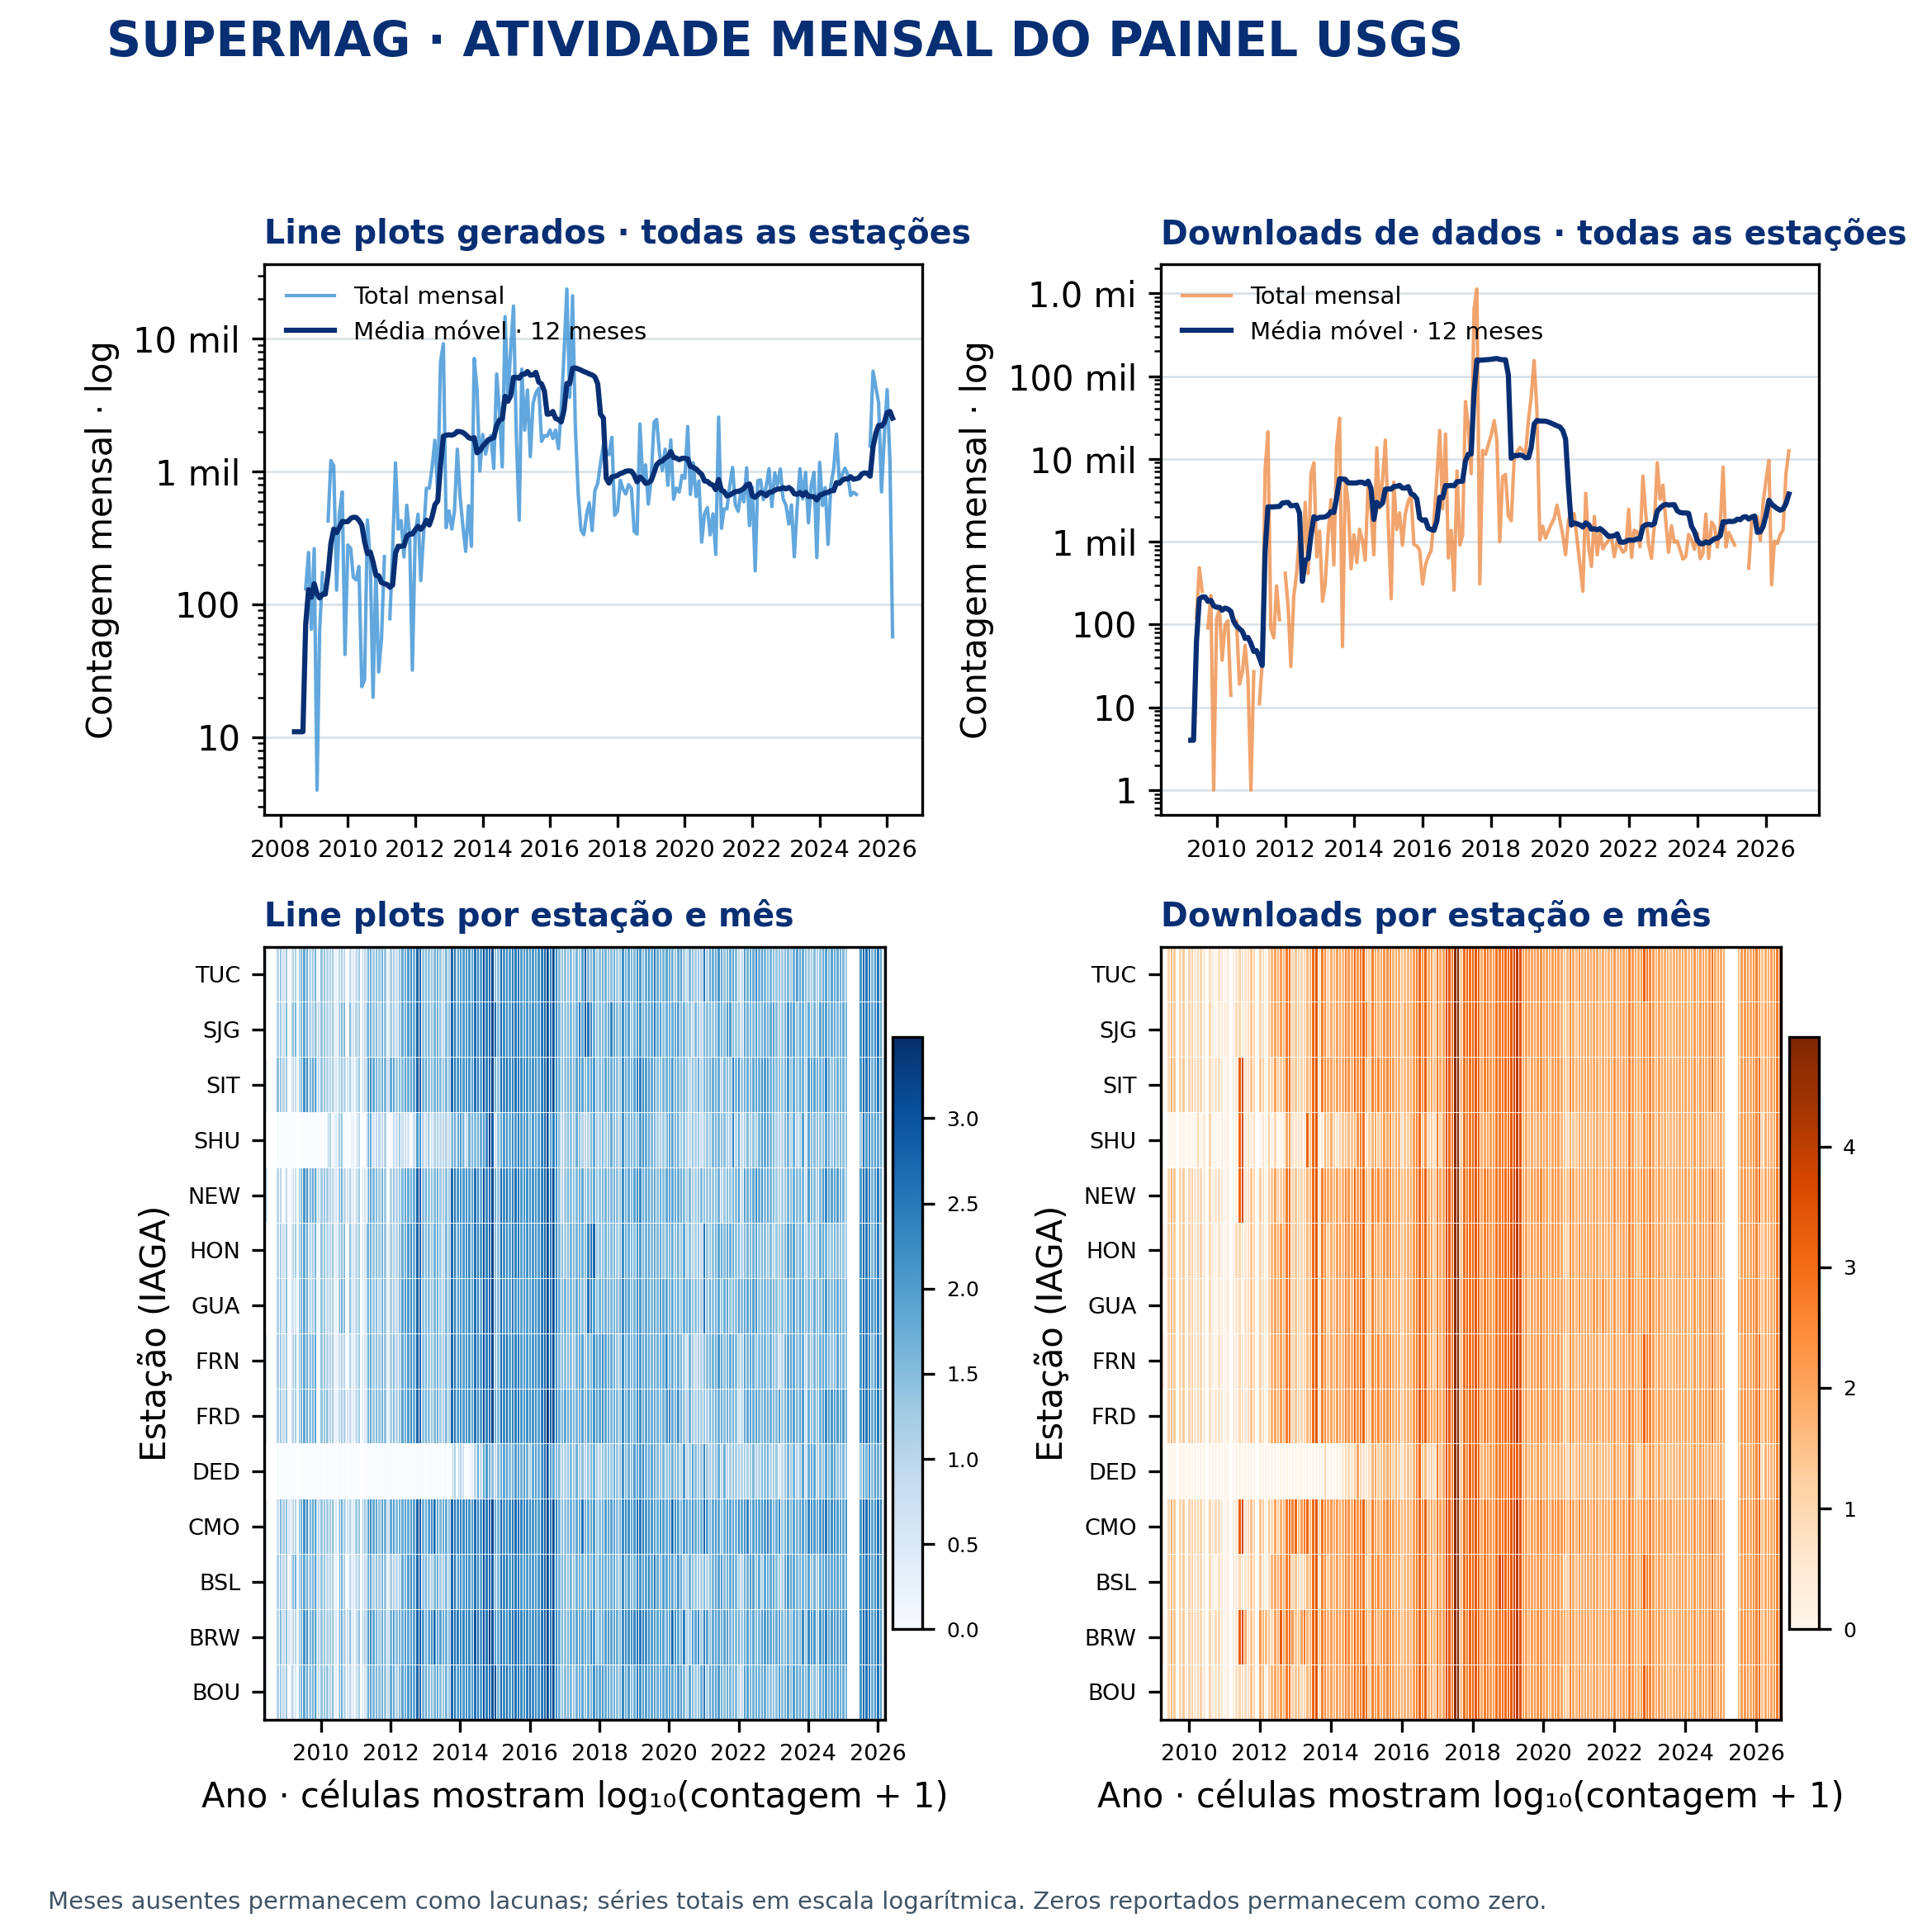

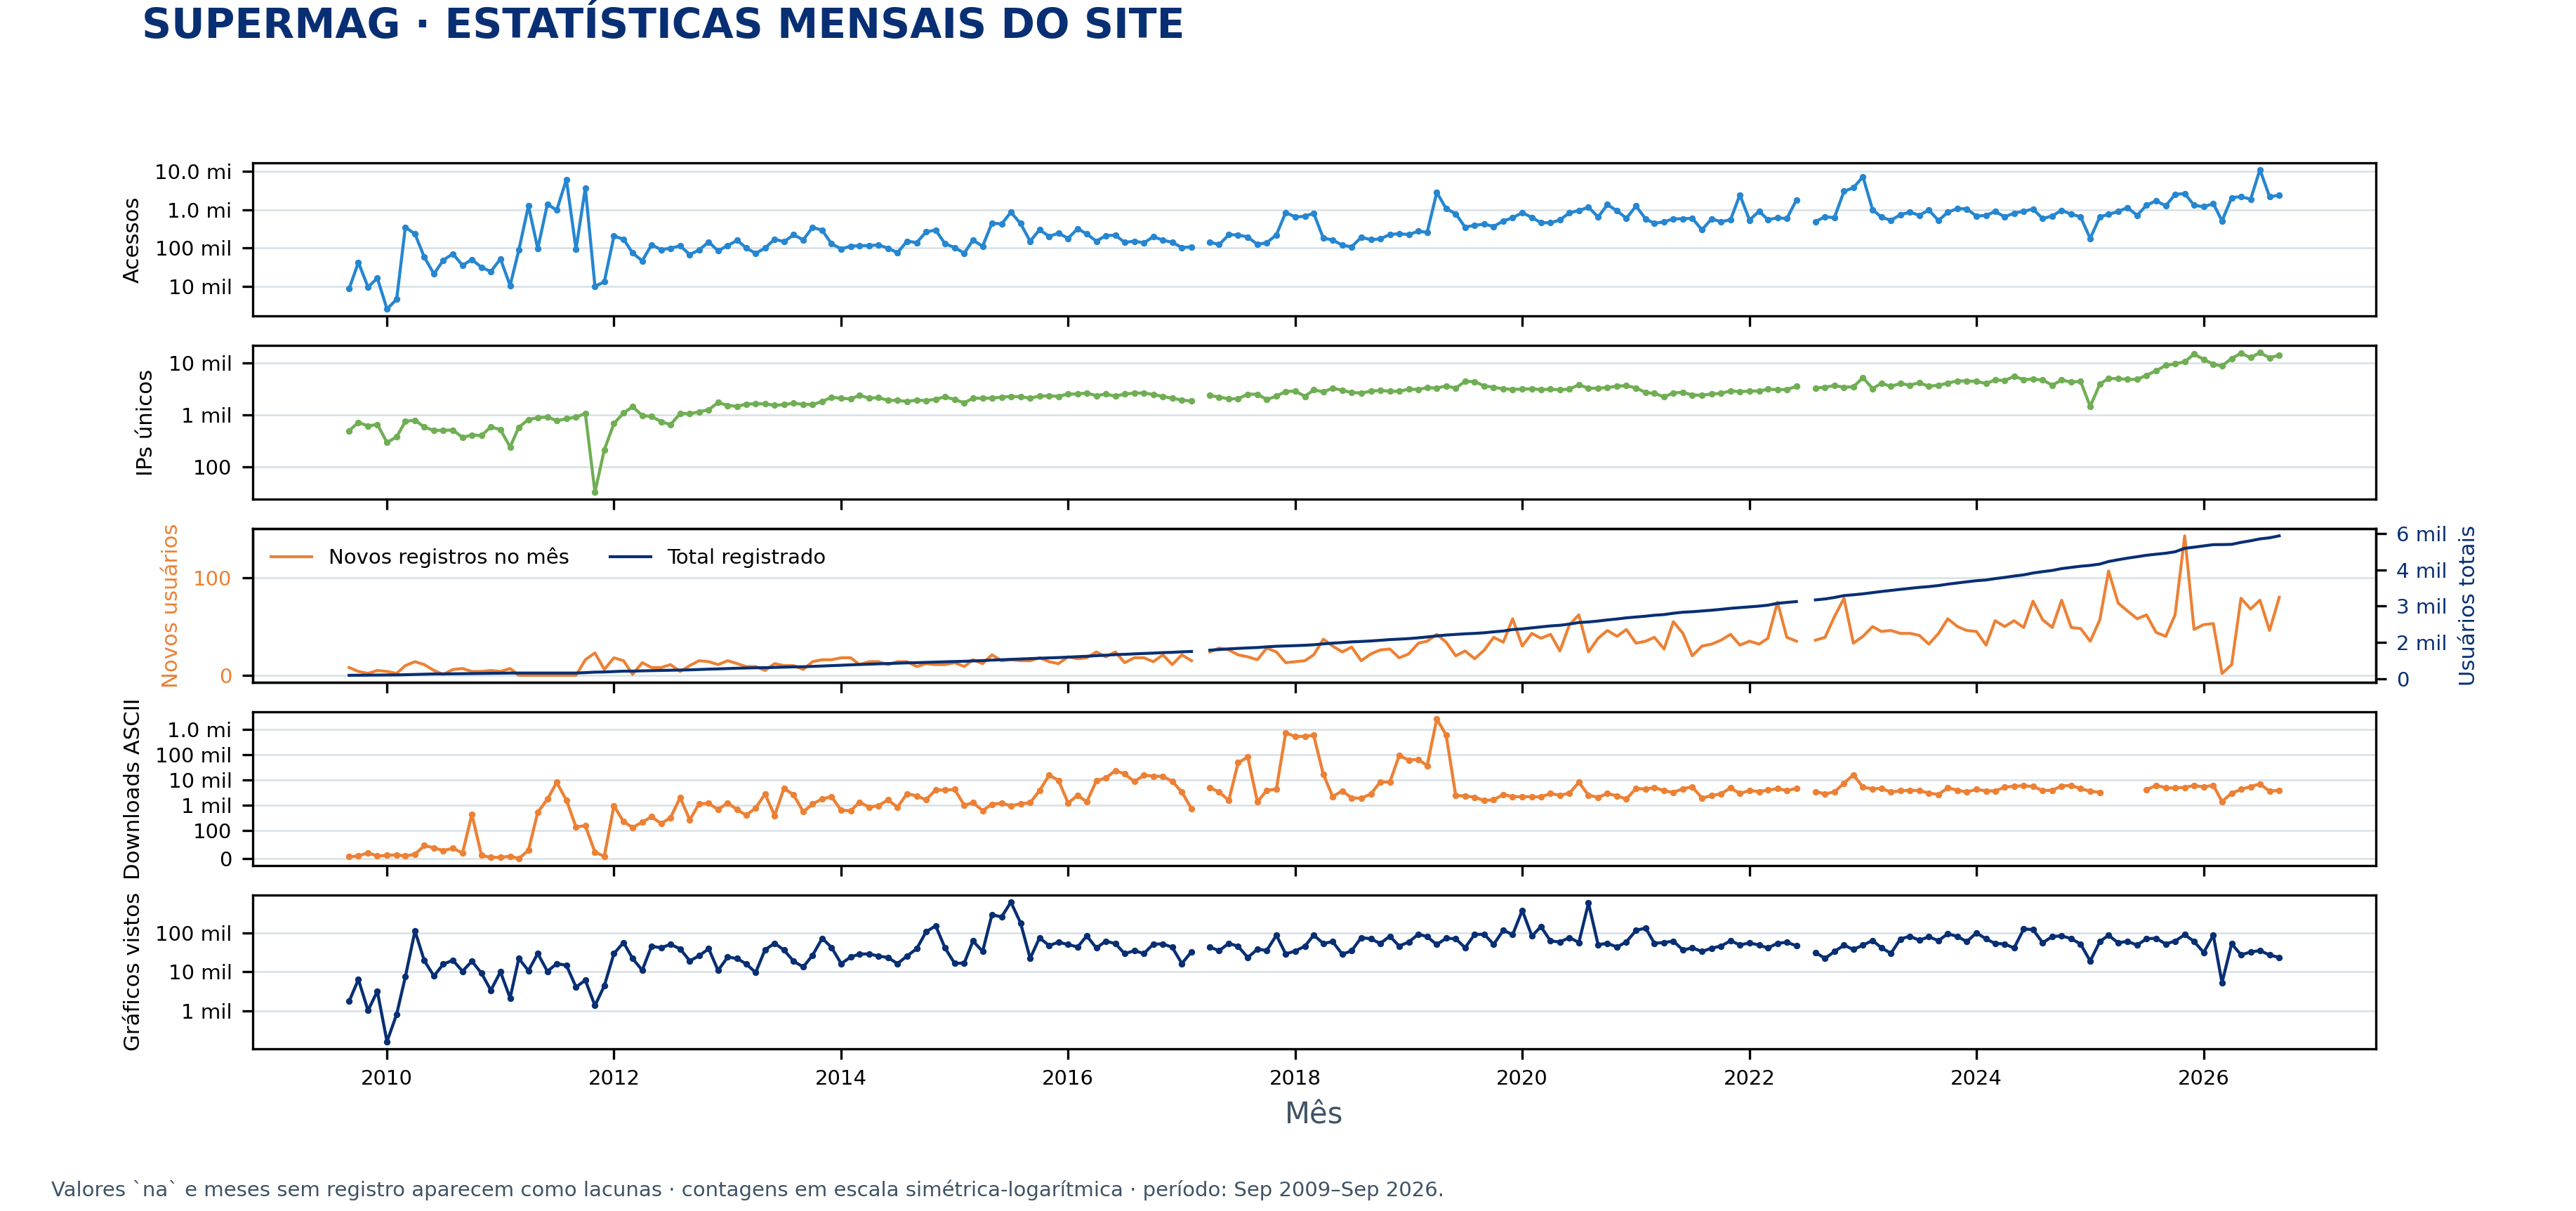

Dashboard inputs located at: $KEYNOTETALK_PROJECT/notebooks/supermag
Dashboard figure outputs: $SBGEA_KEYNOTE_DATA/outputs/figures/supermag/dashboard
Saved figures: USGS_station_annual_coverage_snapshot_2026-10-28.png USGS_monthly_downloads_and_lineplots_snapshot_2026-10-28.png SuperMAG_website_monthly_usage_snapshot_2026-10-28.png
CSV/TXT pairs match: availability 14 stations; downloads 201 months; line plots 205 months.
Website statistics: 203 months from 2009-09-01 00:00:00 to 2026-09-01 00:00:00
2025 site totals: hits 15050535 unique-IP month counts 81432 reported downloads 37987 plots viewed 752345


In [1]:
from pathlib import Path
import re
import calendar
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, LogLocator, MaxNLocator
from IPython.display import display, Image

# Locate the inputs whether the kernel starts at the repository root or notebook folder.
_stats_candidates=[
    Path.cwd(),
    Path.cwd()/"notebooks"/"supermag",
    Path.cwd()/"ezieAsPy"/"develop"/"mesqur1"/"KeynoteTalkGodHelpMe"/"notebooks"/"supermag",
]
STATS_DIR=next((p.resolve() for p in _stats_candidates
                if (p/"USGS-2026-10-28.csv").is_file()),None)
if STATS_DIR is None:
    raise FileNotFoundError("Could not find the USGS/SuperMAG dashboard exports from the notebook working directory.")
KEYNOTE_ROOT=Path(os.environ.get("SBGEA_KEYNOTE_DATA",Path.home()/"Documents/Science/Programs/LFS/KEYNOTE")).expanduser()
DASHBOARD_FIG_DIR=KEYNOTE_ROOT/"outputs"/"figures"/"supermag"/"dashboard"
DASHBOARD_FIG_DIR.mkdir(parents=True,exist_ok=True)

# Read each tab-separated text companion and verify it matches the CSV snapshot.
def _read_dashboard_pair(stem):
    csv_frame=pd.read_csv(STATS_DIR/f"{stem}.csv")
    txt_frame=pd.read_csv(STATS_DIR/f"{stem}.txt",sep="\t")
    if not csv_frame.equals(txt_frame):
        raise ValueError(f"CSV and TXT exports differ for {stem}")
    return csv_frame

station_year=_read_dashboard_pair("USGS-2026-10-28")
station_downloads=_read_dashboard_pair("USGS-downloads-2026-10-28")
station_lineplots=_read_dashboard_pair("USGS-line-plots-2026-10-28")

NAVY="#082F73"; BLUE="#2686D0"; ORANGE="#EC8135"; GREEN="#70AE54"
PALE="#F2F5F4"; GRID="#D8E0E6"; TEXT="#405365"

# 1) Annual data availability by station (% of possible observations in each year).
year_columns=[column for column in station_year.columns if str(column).isdigit()]
years=np.asarray([int(year) for year in year_columns])
coverage=station_year.set_index("IAGA")[year_columns].apply(
    lambda col: pd.to_numeric(col.astype(str).str.rstrip("%"),errors="coerce"))
coverage_values=coverage.to_numpy(dtype=float)
fig_coverage,ax=plt.subplots(figsize=(5.54,6.03),dpi=130,facecolor="white")
fig_coverage.suptitle("SUPERMAG · COBERTURA ANUAL DAS ESTAÇÕES USGS",
    x=.055,y=.985,ha="left",fontsize=10.5,fontweight="bold",color=NAVY)
ax.set_facecolor("#EEF1F3")
coverage_image=ax.imshow(coverage_values,aspect="auto",interpolation="nearest",
    cmap="Greens",vmin=0,vmax=100)
ax.set_yticks(np.arange(len(coverage.index)),coverage.index)
ax.set_ylabel("Estação (IAGA)",color=TEXT)
visible_year_indices=[i for i,y in enumerate(years) if y%5==0]
ax.set_xticks(visible_year_indices,[str(years[i]) for i in visible_year_indices],rotation=45,ha="right")
ax.set_xlabel("Ano",color=TEXT)
ax.set_xticks(np.arange(-.5,len(years),1),minor=True)
ax.set_yticks(np.arange(-.5,len(coverage.index),1),minor=True)
ax.grid(which="minor",color="white",linewidth=.45)
ax.tick_params(which="minor",bottom=False,left=False)
cb=fig_coverage.colorbar(coverage_image,ax=ax,pad=.015,fraction=.025)
cb.set_label("Disponibilidade anual (%)")
fig_coverage.text(.055,.015,
    "Instantâneo do painel: 28 out. 2026 · 2026 é parcial · valores 0% permanecem como disponibilidade nula.",
    ha="left",fontsize=7,color=TEXT)
fig_coverage.tight_layout(rect=(.035,.045,.97,.94),pad=.6)
coverage_png=DASHBOARD_FIG_DIR/"USGS_station_annual_coverage_snapshot_2026-10-28.png"
fig_coverage.savefig(coverage_png,dpi=300,facecolor="white")
display(Image(filename=str(coverage_png)))
plt.close(fig_coverage)

# 2) Monthly station downloads and generated line plots.
def _monthly_frame(frame):
    result=frame.copy()
    result["Month"]=pd.to_datetime(result["Month"],format="%Y-%m")
    result=result.sort_values("Month").set_index("Month")
    full_months=pd.date_range(result.index.min(),result.index.max(),freq="MS",name="Month")
    return result.reindex(full_months)

downloads_monthly=_monthly_frame(station_downloads)
lineplots_monthly=_monthly_frame(station_lineplots)
station_codes=[column for column in station_downloads.columns if column not in {"Month","All"}]
def _short_count(value,pos=None):
    value=float(value)
    if abs(value)>=1_000_000: return f"{value/1_000_000:.1f} mi"
    if abs(value)>=1_000: return f"{value/1_000:.0f} mil"
    return f"{value:.0f}"
fig_monthly,axs=plt.subplots(2,2,figsize=(7.8,7.8),dpi=130,facecolor="white",
    gridspec_kw={"height_ratios":[.82,1.15]})
fig_monthly.suptitle("SUPERMAG · ATIVIDADE MENSAL DO PAINEL USGS",
    x=.055,y=.99,ha="left",fontsize=14,fontweight="bold",color=NAVY)

for ax,frame,metric,color,title in [
    (axs[0,0],lineplots_monthly,"All",BLUE,"Line plots gerados · todas as estações"),
    (axs[0,1],downloads_monthly,"All",ORANGE,"Downloads de dados · todas as estações"),
]:
    ax.plot(frame.index,frame[metric],color=color,lw=1.0,alpha=.72,label="Total mensal")
    ax.plot(frame.index,frame[metric].rolling(12,min_periods=1).mean(),
            color=NAVY,lw=1.5,label="Média móvel · 12 meses")
    ax.set_title(title,loc="left",fontsize=9.5,fontweight="bold",color=NAVY)
    ax.set_ylabel("Contagem mensal · log")
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10,numticks=7))
    ax.yaxis.set_major_formatter(FuncFormatter(_short_count))
    ax.grid(True,axis="y",color=GRID,linewidth=.6)
    ax.legend(frameon=False,fontsize=7,loc="upper left")
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.tick_params(axis="x",labelsize=7)

# Station-by-month matrices use log10(count + 1) so quieter stations remain visible.
def _station_heatmap(ax,frame,title,cmap):
    month_grid=pd.date_range(frame.index.min(),frame.index.max(),freq="MS")
    values=frame[station_codes].apply(pd.to_numeric,errors="coerce").reindex(month_grid)
    matrix=np.log10(values.to_numpy(dtype=float).T+1.0)
    image=ax.imshow(np.ma.masked_invalid(matrix),aspect="auto",origin="lower",
        interpolation="nearest",cmap=cmap,vmin=0,
        vmax=max(1.0,float(np.nanmax(matrix))))
    ax.set_yticks(np.arange(len(station_codes)),station_codes)
    ax.set_ylabel("Estação (IAGA)")
    ax.set_title(title,loc="left",fontsize=9.5,fontweight="bold",color=NAVY)
    ticks=[i for i,month in enumerate(month_grid) if month.month==1 and month.year%2==0]
    ax.set_xticks(ticks,[str(month_grid[i].year) for i in ticks],rotation=0)
    ax.set_xlabel("Ano · células mostram log₁₀(contagem + 1)")
    ax.tick_params(axis="both",labelsize=6.5)
    ax.set_xticks(np.arange(-.5,len(month_grid),1),minor=True)
    ax.set_yticks(np.arange(-.5,len(station_codes),1),minor=True)
    ax.grid(which="minor",color="white",linewidth=.22)
    ax.tick_params(which="minor",bottom=False,left=False)
    cbar=fig_monthly.colorbar(image,ax=ax,pad=.012,fraction=.045)
    cbar.ax.tick_params(labelsize=6)
    return month_grid

_station_heatmap(axs[1,0],lineplots_monthly,"Line plots por estação e mês","Blues")
_station_heatmap(axs[1,1],downloads_monthly,"Downloads por estação e mês","Oranges")
fig_monthly.text(.025,.012,
    "Meses ausentes permanecem como lacunas; séries totais em escala logarítmica. Zeros reportados permanecem como zero.",
    ha="left",fontsize=7,color=TEXT)
fig_monthly.tight_layout(rect=(.025,.04,.98,.95),h_pad=1.0,w_pad=1.1)
monthly_png=DASHBOARD_FIG_DIR/"USGS_monthly_downloads_and_lineplots_snapshot_2026-10-28.png"
fig_monthly.savefig(monthly_png,dpi=300,facecolor="white")
display(Image(filename=str(monthly_png)))
plt.close(fig_monthly)

# 3) Site-wide monthly statistics parsed from the SuperMAG webstats text export.
webstats_path=STATS_DIR/"webstats.txt"
web_pattern=re.compile(
    r"^(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)\s+(\d{4}):\s*"
    r"([\d,]+)\s+([\d,]+)\s+(\d+)\s*\(\s*([\d,]+)\s*\)\s+"
    r"(na|[\d,]+)\s+([\d,]+)",re.I)
web_records=[]
for raw_line in webstats_path.read_text(encoding="utf-8",errors="replace").splitlines():
    match=web_pattern.match(raw_line.strip())
    if not match: continue
    month_name,year,hits,unique_ips,new_users,total_users,downloads,plots=match.groups()
    parse_int=lambda value: int(value.replace(",",""))
    web_records.append({
        "Month":pd.to_datetime(f"{year}-{month_name}-01",format="%Y-%b-%d"),
        "Hits":parse_int(hits),"UniqueIPs":parse_int(unique_ips),
        "NewUsers":parse_int(new_users),"RegisteredTotal":parse_int(total_users),
        "Downloads":np.nan if downloads.lower()=="na" else parse_int(downloads),
        "PlotsViewed":parse_int(plots),
    })
webstats=pd.DataFrame(web_records).sort_values("Month").reset_index(drop=True)
if webstats.empty:
    raise ValueError(f"No monthly records parsed from {webstats_path}")
web_months=pd.date_range(webstats.Month.min(),webstats.Month.max(),freq="MS",name="Month")
webstats_plot=webstats.set_index("Month").reindex(web_months)

fig_web,web_axes=plt.subplots(5,1,figsize=(12.23,5.75),dpi=130,sharex=True,facecolor="white")
fig_web.suptitle("SUPERMAG · ESTATÍSTICAS MENSAIS DO SITE",
    x=.055,y=.995,ha="left",fontsize=14,fontweight="bold",color=NAVY)
web_specs=[
    ("Hits","Acessos",BLUE),
    ("UniqueIPs","IPs únicos",GREEN),
    ("Downloads","Downloads ASCII",ORANGE),
    ("PlotsViewed","Gráficos vistos",NAVY),
]
# Dedicated axes for activity counts; user registrations get their own panel with cumulative total.
for ax,(column,label,color) in zip([web_axes[0],web_axes[1],web_axes[3],web_axes[4]],web_specs):
    ax.plot(webstats_plot.index,webstats_plot[column],color=color,lw=1.05,marker=".",markersize=2.5)
    ax.set_yscale("symlog",linthresh=100)
    ax.yaxis.set_major_formatter(FuncFormatter(_short_count))
    ax.set_ylabel(label,fontsize=7.4)
    ax.grid(True,axis="y",color=GRID,linewidth=.6)
    ax.tick_params(axis="y",labelsize=7)

ax_users=web_axes[2]
ax_users.plot(webstats_plot.index,webstats_plot.NewUsers,color=ORANGE,lw=1.0,
             label="Novos registros no mês")
ax_users.set_ylabel("Novos usuários",fontsize=7.4,color=ORANGE)
ax_users.tick_params(axis="y",labelcolor=ORANGE,labelsize=7)
ax_users.grid(True,axis="y",color=GRID,linewidth=.6)
ax_users_total=ax_users.twinx()
ax_users_total.plot(webstats_plot.index,webstats_plot.RegisteredTotal,color=NAVY,lw=1.0,
                    label="Total registrado")
ax_users_total.set_ylabel("Usuários totais",fontsize=7.4,color=NAVY)
ax_users_total.yaxis.set_major_locator(MaxNLocator(nbins=5,integer=True))
ax_users_total.yaxis.set_major_formatter(FuncFormatter(_short_count))
ax_users_total.tick_params(axis="y",labelcolor=NAVY,labelsize=7)
handles1,labels1=ax_users.get_legend_handles_labels()
handles2,labels2=ax_users_total.get_legend_handles_labels()
ax_users.legend(handles1+handles2,labels1+labels2,loc="upper left",frameon=False,fontsize=7,ncol=2)
for ax in web_axes:
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.tick_params(axis="x",labelsize=7)
web_axes[-1].set_xlabel("Mês",color=TEXT)
fig_web.text(.02,.012,
    "Valores `na` e meses sem registro aparecem como lacunas · contagens em escala simétrica-logarítmica · período: "
    f"{webstats.Month.min():%b %Y}–{webstats.Month.max():%b %Y}.",
    ha="left",fontsize=7,color=TEXT)
fig_web.tight_layout(rect=(.035,.04,.975,.95),h_pad=.55)
web_png=DASHBOARD_FIG_DIR/"SuperMAG_website_monthly_usage_snapshot_2026-10-28.png"
fig_web.savefig(web_png,dpi=300,facecolor="white")
display(Image(filename=str(web_png)))
plt.close(fig_web)

print("Dashboard inputs located at:",STATS_DIR)
print("Dashboard figure outputs:",DASHBOARD_FIG_DIR)
print("Saved figures:",coverage_png.name,monthly_png.name,web_png.name)
print("CSV/TXT pairs match: availability",len(station_year),"stations; downloads",len(station_downloads),
      "months; line plots",len(station_lineplots),"months.")
print("Website statistics:",len(webstats),"months from",webstats.Month.min(),"to",webstats.Month.max())
web_2025=webstats[webstats.Month.dt.year.eq(2025)]
print("2025 site totals: hits",int(web_2025.Hits.sum()),"unique-IP month counts",
      int(web_2025.UniqueIPs.sum()),"reported downloads",int(web_2025.Downloads.sum()),
      "plots viewed",int(web_2025.PlotsViewed.sum()))


## SuperMAG user registrations and doubling milestones

This cell is self-contained: it reads `webstats.txt` directly and does not depend on variables or imports from earlier cells. The chart shows only monthly new users and the cumulative total of registered users. Vertical dashed lines mark the first month the total reaches each successive doubling of the first reported total. The PNG is saved in the KEYNOTE dashboard output folder.


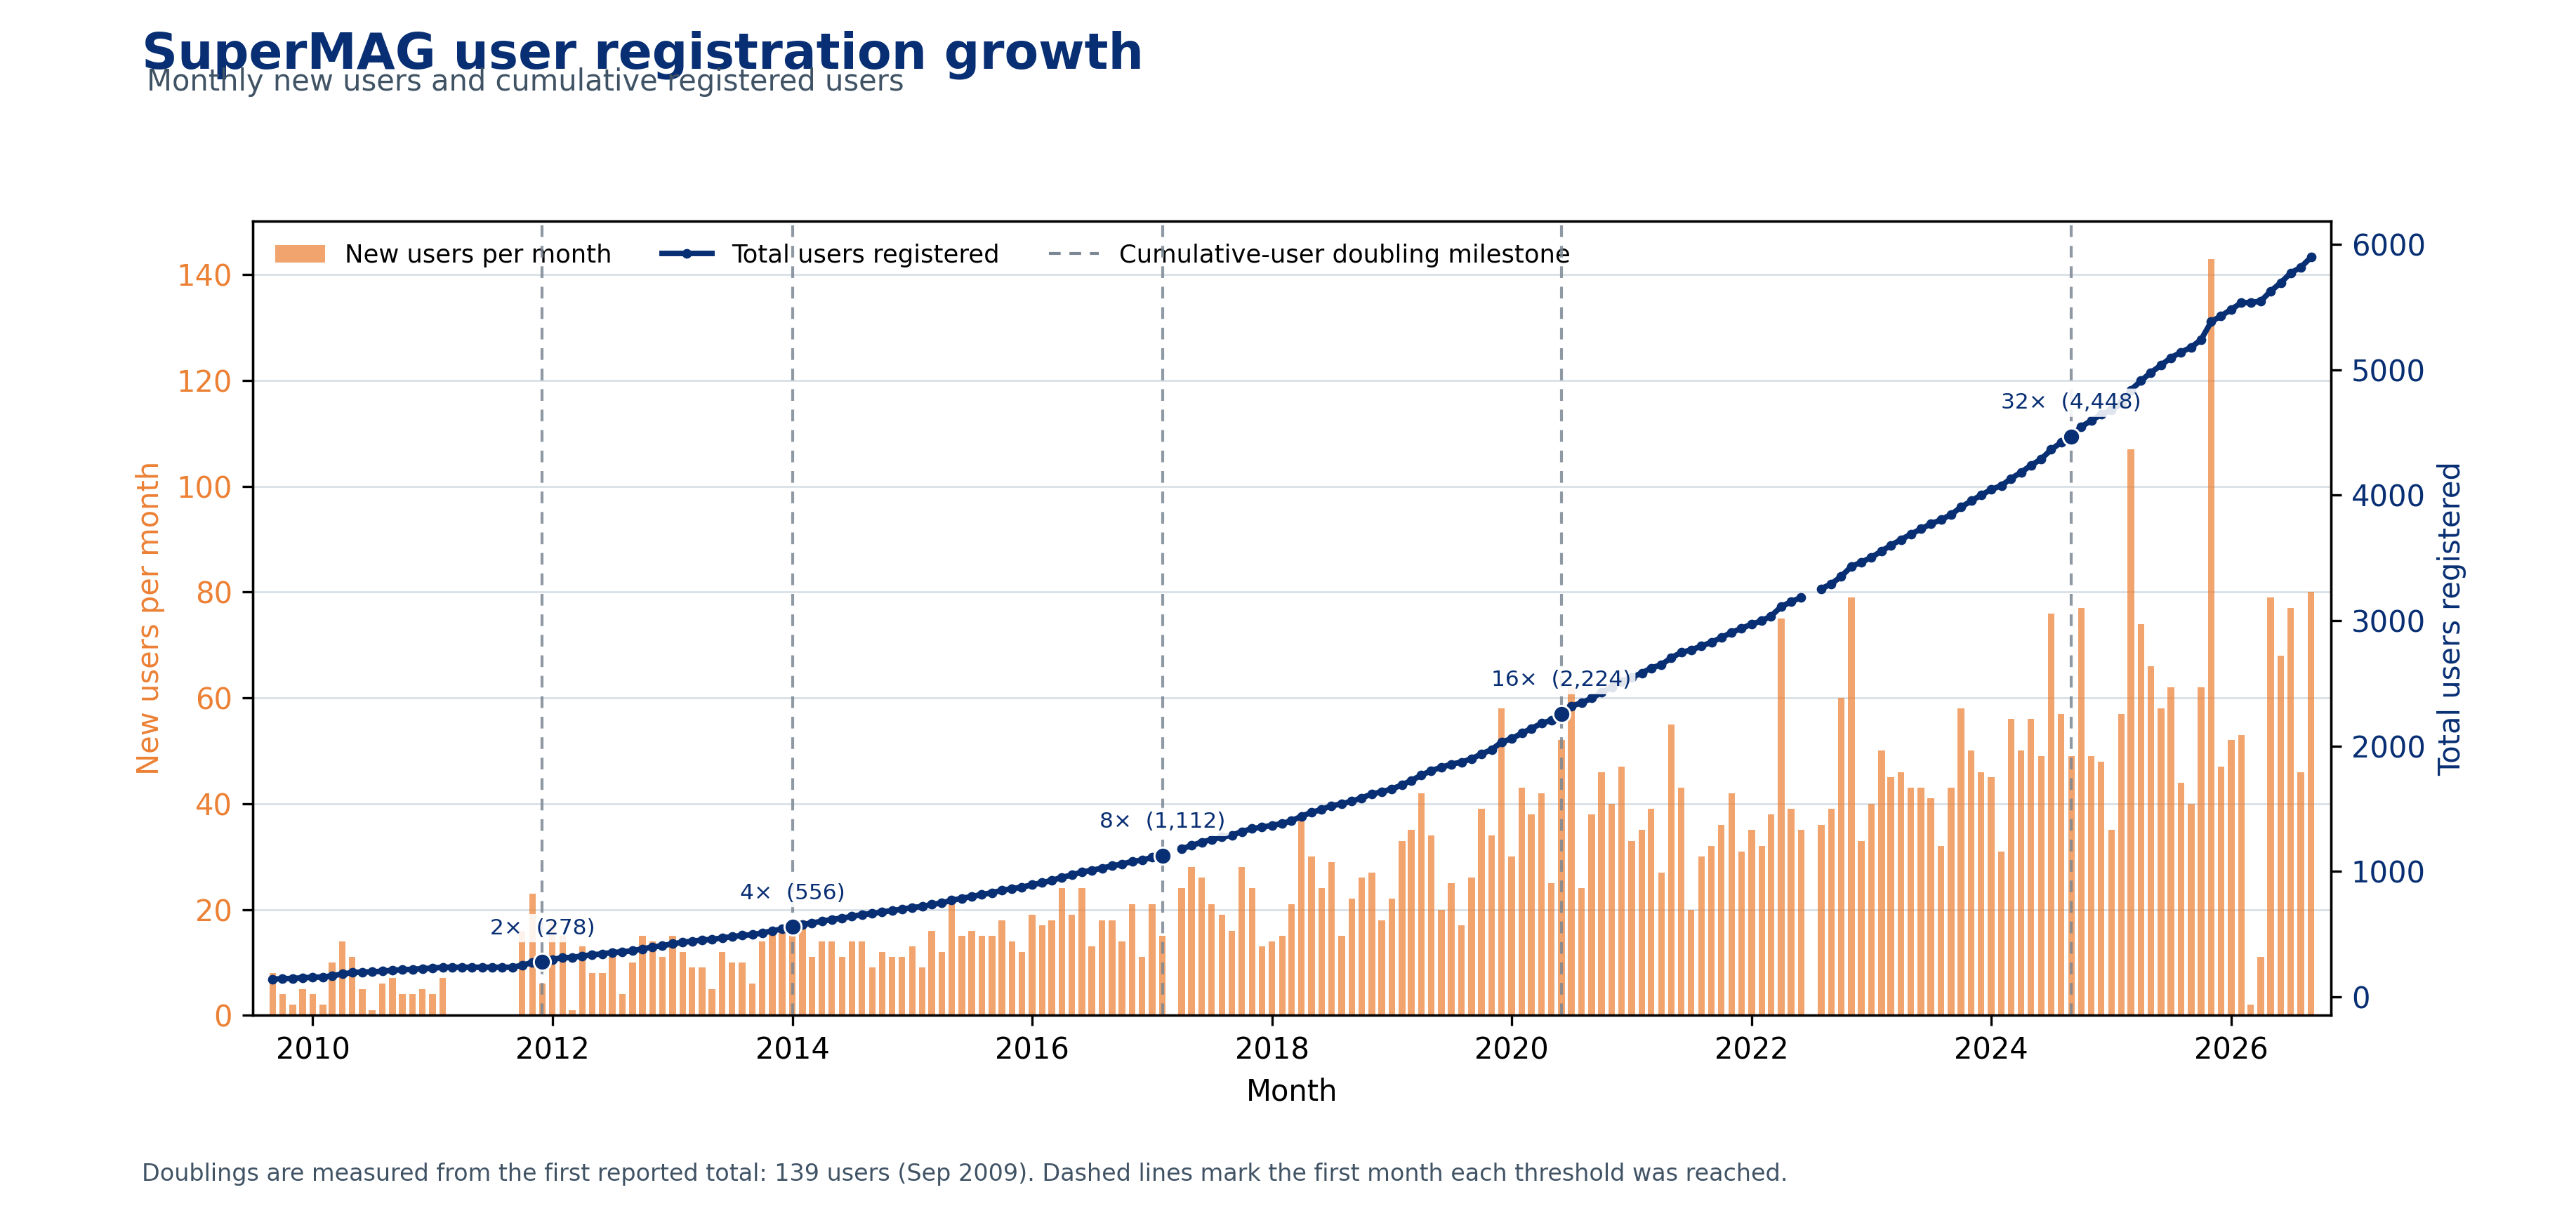

Parsed 203 reported monthly totals, Sep 2009–Sep 2026.
Initial total: 139; latest total: 5,899.
Doubling milestones: 2× (278) in Dec 2011; 4× (556) in Jan 2014; 8× (1,112) in Feb 2017; 16× (2,224) in Jun 2020; 32× (4,448) in Sep 2024
Saved figure: KEYNOTE/outputs/figures/supermag/dashboard/SuperMAG_user_registration_growth.png


In [17]:
# Standalone SuperMAG user-growth plot: this cell reads webstats.txt directly and
# does not depend on variables or imports from any earlier notebook cell.
from pathlib import Path
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from IPython.display import display, Image

# Find the dashboard data in either supported project copy, or through an
# explicit KEYNOTETALK_PROJECT path on another computer.
_USER_GROWTH_CANDIDATES = []
_PROJECT_ENV = os.environ.get("KEYNOTETALK_PROJECT")
if _PROJECT_ENV:
    _USER_GROWTH_CANDIDATES.append(Path(_PROJECT_ENV).expanduser() / "notebooks" / "supermag")
_CWD = Path.cwd().resolve()
for _BASE in (_CWD, *_CWD.parents):
    _USER_GROWTH_CANDIDATES.extend([
        _BASE,
        _BASE / "notebooks" / "supermag",
        _BASE / "ezieAsPy" / "develop" / "mesqur1" / "KeynoteTalkGodHelpMe" / "notebooks" / "supermag",
    ])
_USER_GROWTH_CANDIDATES.extend([
    Path.home() / "Documents" / "Science" / "Programs" / "KeynoteTalk" / "notebooks" / "supermag",
    Path.home() / "Documents" / "Science" / "Programs" / "prizm" / "ezieAsPy" / "develop" / "mesqur1" / "KeynoteTalkGodHelpMe" / "notebooks" / "supermag",
])
_USER_GROWTH_STATS_DIR = next(
    (candidate for candidate in dict.fromkeys(_USER_GROWTH_CANDIDATES)
     if (candidate / "webstats.txt").is_file()),
    None,
)
if _USER_GROWTH_STATS_DIR is None:
    raise FileNotFoundError(
        "Could not locate notebooks/supermag/webstats.txt. Set KEYNOTETALK_PROJECT "
        "to the project folder or open this notebook from its project checkout."
    )

# Parse only the monthly new-user and cumulative-user fields from webstats.txt.
_USER_GROWTH_PATTERN = re.compile(
    r"^(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)\s+(\d{4}):\s*"
    r"[\d,]+\s+[\d,]+\s+(\d+)\s*\(\s*([\d,]+)\s*\)\s+"
    r"(?:na|[\d,]+)\s+[\d,]+\s*$",
    re.IGNORECASE,
)
_USER_GROWTH_RECORDS = []
for _RAW_LINE in (_USER_GROWTH_STATS_DIR / "webstats.txt").read_text(
        encoding="utf-8", errors="replace").splitlines():
    _MATCH = _USER_GROWTH_PATTERN.match(_RAW_LINE.strip())
    if _MATCH:
        _MONTH_NAME, _YEAR, _NEW_USERS, _TOTAL_USERS = _MATCH.groups()
        _USER_GROWTH_RECORDS.append({
            "Month": pd.to_datetime(f"{_YEAR}-{_MONTH_NAME}-01", format="%Y-%b-%d"),
            "NewUsers": int(_NEW_USERS.replace(",", "")),
            "RegisteredTotal": int(_TOTAL_USERS.replace(",", "")),
        })
USER_GROWTH_DATA = (
    pd.DataFrame(_USER_GROWTH_RECORDS)
    .drop_duplicates("Month", keep="first")
    .sort_values("Month")
    .set_index("Month")
)
if USER_GROWTH_DATA.empty:
    raise ValueError(f"No monthly user-registration records were parsed from {_USER_GROWTH_STATS_DIR / 'webstats.txt'}")
_USER_GROWTH_MONTHS = pd.date_range(
    USER_GROWTH_DATA.index.min(), USER_GROWTH_DATA.index.max(), freq="MS", name="Month"
)
USER_GROWTH_DATA = USER_GROWTH_DATA.reindex(_USER_GROWTH_MONTHS)
_USER_GROWTH_VALID = USER_GROWTH_DATA["RegisteredTotal"].dropna()
_USER_GROWTH_BASELINE = float(_USER_GROWTH_VALID.iloc[0])
_USER_GROWTH_MAX = float(_USER_GROWTH_VALID.max())

# A doubling milestone is each successive power of two times the first
# reported cumulative total (for this snapshot, 139 users in Sep 2009).
USER_GROWTH_MILESTONES = []
_USER_GROWTH_MULTIPLE = 2
while _USER_GROWTH_BASELINE * _USER_GROWTH_MULTIPLE <= _USER_GROWTH_MAX:
    _THRESHOLD = _USER_GROWTH_BASELINE * _USER_GROWTH_MULTIPLE
    _CROSSED = _USER_GROWTH_VALID[_USER_GROWTH_VALID >= _THRESHOLD]
    if not _CROSSED.empty:
        _MILESTONE_MONTH = _CROSSED.index[0]
        USER_GROWTH_MILESTONES.append({
            "multiple": _USER_GROWTH_MULTIPLE,
            "threshold": _THRESHOLD,
            "month": _MILESTONE_MONTH,
            "observed_total": float(_CROSSED.iloc[0]),
        })
    _USER_GROWTH_MULTIPLE *= 2

# Save to the shared KEYNOTE output tree, honoring its portable override.
_USER_GROWTH_DATA_ROOT = Path(os.environ.get(
    "SBGEA_KEYNOTE_DATA",
    Path.home() / "Documents" / "Science" / "Programs" / "LFS" / "KEYNOTE",
)).expanduser()
_USER_GROWTH_OUTPUT_DIR = _USER_GROWTH_DATA_ROOT / "outputs" / "figures" / "supermag" / "dashboard"
_USER_GROWTH_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
USER_GROWTH_FIGURE = _USER_GROWTH_OUTPUT_DIR / "SuperMAG_user_registration_growth.png"

NAVY = "#082F73"
ORANGE = "#EC8135"
GRAY = "#7B8794"
GRID = "#D8E0E6"
TEXT = "#405365"

fig_user_growth, ax_new_users = plt.subplots(
    figsize=(12.23, 5.75), dpi=130, facecolor="white"
)
fig_user_growth.suptitle(
    "SuperMAG user registration growth",
    x=0.055, y=0.975, ha="left", fontsize=17, fontweight="bold", color=NAVY,
)
fig_user_growth.text(
    0.057, 0.925,
    "Monthly new users and cumulative registered users",
    ha="left", fontsize=10, color=TEXT,
)

ax_new_users.bar(
    USER_GROWTH_DATA.index,
    USER_GROWTH_DATA["NewUsers"],
    width=20,
    color=ORANGE,
    alpha=0.72,
    label="New users per month",
    zorder=2,
)
ax_new_users.set_ylabel("New users per month", color=ORANGE)
ax_new_users.tick_params(axis="y", labelcolor=ORANGE)
ax_new_users.set_ylim(bottom=0)
ax_new_users.grid(axis="y", color=GRID, linewidth=0.65)
ax_new_users.set_axisbelow(True)
ax_new_users.set_xlabel("Month")
ax_new_users.xaxis.set_major_locator(mdates.YearLocator(2))
ax_new_users.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax_new_users.set_xlim(USER_GROWTH_DATA.index.min() - pd.Timedelta(days=60),
                       USER_GROWTH_DATA.index.max() + pd.Timedelta(days=60))

ax_total_users = ax_new_users.twinx()
ax_total_users.plot(
    USER_GROWTH_DATA.index,
    USER_GROWTH_DATA["RegisteredTotal"],
    color=NAVY,
    linewidth=1.9,
    marker="o",
    markersize=2.3,
    label="Total users registered",
    zorder=4,
)
ax_total_users.set_ylabel("Total users registered", color=NAVY)
ax_total_users.tick_params(axis="y", labelcolor=NAVY)
ax_total_users.grid(False)

for _MILESTONE in USER_GROWTH_MILESTONES:
    ax_total_users.axvline(
        _MILESTONE["month"], color=GRAY, linestyle=(0, (4, 3)),
        linewidth=1.0, alpha=0.85, zorder=1,
    )
    ax_total_users.scatter(
        [_MILESTONE["month"]], [_MILESTONE["observed_total"]],
        color=NAVY, edgecolor="white", linewidth=0.7, s=34, zorder=5,
    )
    ax_total_users.annotate(
        f"{_MILESTONE['multiple']}×  ({_MILESTONE['threshold']:,.0f})",
        xy=(_MILESTONE["month"], _MILESTONE["observed_total"]),
        xytext=(0, 8), textcoords="offset points",
        ha="center", va="bottom", fontsize=7.5, color=NAVY,
        bbox={"boxstyle": "round,pad=0.18", "facecolor": "white", "edgecolor": "none", "alpha": 0.88},
        zorder=6,
    )

_milestone_legend = Line2D(
    [0], [0], color=GRAY, linestyle=(0, (4, 3)), linewidth=1.0,
    label="Cumulative-user doubling milestone",
)
_handles_new, _labels_new = ax_new_users.get_legend_handles_labels()
_handles_total, _labels_total = ax_total_users.get_legend_handles_labels()
ax_new_users.legend(
    _handles_new + _handles_total + [_milestone_legend],
    _labels_new + _labels_total + [_milestone_legend.get_label()],
    loc="upper left", frameon=False, ncol=3, fontsize=8.5,
)

fig_user_growth.text(
    0.055, 0.025,
    f"Doublings are measured from the first reported total: {_USER_GROWTH_BASELINE:,.0f} users "
    f"({USER_GROWTH_DATA.index.min():%b %Y}). Dashed lines mark the first month each threshold was reached.",
    ha="left", fontsize=8, color=TEXT,
)
fig_user_growth.tight_layout(rect=(0.045, 0.07, 0.965, 0.89), pad=0.7)
fig_user_growth.savefig(USER_GROWTH_FIGURE, dpi=300, facecolor="white")
display(Image(filename=str(USER_GROWTH_FIGURE)))

print(f"Parsed {len(_USER_GROWTH_VALID):,} reported monthly totals, {_USER_GROWTH_VALID.index.min():%b %Y}–{_USER_GROWTH_VALID.index.max():%b %Y}.")
print(f"Initial total: {_USER_GROWTH_BASELINE:,.0f}; latest total: {_USER_GROWTH_VALID.iloc[-1]:,.0f}.")
print("Doubling milestones:", "; ".join(
    f"{m['multiple']}× ({m['threshold']:,.0f}) in {m['month']:%b %Y}"
    for m in USER_GROWTH_MILESTONES
))
print("Saved figure: KEYNOTE/outputs/figures/supermag/dashboard/SuperMAG_user_registration_growth.png")
